# BERT

In [1]:
!curl -L -o ~/invoices-ocr.zip https://www.kaggle.com/api/v1/datasets/download/osamahosamabdellatif/high-quality-invoice-images-for-ocr
!unzip ~/invoices-ocr.zip -d /content/invoices

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1165M  100 1165M    0     0  16.4M      0  0:01:10  0:01:10 --:--:-- 16.8M
Archive:  /root/invoices-ocr.zip
  inflating: /content/invoices/batch_1/batch_1/batch1_1.csv  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0001.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0002.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0003.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0004.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0005.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0006.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0007.jpg  
  inflating: /content/invoices/batch_1/batch_1/batch1_1/batch1-0008.jpg

In [2]:
!pip install -q \
    transformers \
    datasets \
    accelerate \
    sentencepiece \
    scikit-learn
!pip install -q --use-pep517 seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
import json
import random
import re

import numpy as np
import pandas as pd
import torch
from dataclasses import dataclass
from pathlib import Path
import unicodedata

from pydantic_core import core_schema

from datasets import Dataset, DatasetDict
from collections.abc import Callable
from collections import defaultdict
from sklearn.model_selection import train_test_split
from seqeval.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from pydantic import BaseModel
from enum import StrEnum

from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [7]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA: True
GPU: NVIDIA A100-SXM4-40GB


In [8]:
DATA_PATH = Path("/content/drive/MyDrive/ocr/annotated_invoices.parquet")

In [9]:
columns = [
    "path",
    "file_name",
    "subdir",
    "source_group",
    "ocred_text",
    "json_data",
]

In [10]:
df = pd.read_parquet(DATA_PATH)
df.head()

,file_name,json_data,ocred_text,subdir,source_group,csv_path,path,target,top_level_keys,target_text
0,batch1-0494.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",Invoice no: 84652373 Date of issue: 02/23/2021...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '77477 Troy Cli...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""77477 Troy Cliff..."
1,batch1-0489.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Willi...",Invoice no: 37451664 Date of issue: 06/11/2020...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '588 Morales Ra...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""588 Morales Rapi..."
2,batch1-0499.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Heste...",Invoice no: 40108666 Date of issue: 02/07/2020...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '4000 Tonya Rap...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""4000 Tonya Rapid..."
3,batch1-0497.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Olson...",Invoice no: 73285932 Date of issue: 07/25/2017...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '80943 Beck Div...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""80943 Beck Divid..."
4,batch1-0081.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Wilso...",Invoice no: 15288019 Date of issue: 09/07/2014...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '85455 Carter E...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""85455 Carter Est..."


In [771]:
PHASE_1_FIELDS = [
    "invoice.invoice_number",
    "invoice.invoice_date",
    "invoice.due_date",
    "invoice.seller_name",
    "invoice.seller_address",
    "invoice.client_name",
    "invoice.client_address",
    "subtotal.tax",
    "subtotal.discount",
    "subtotal.total",
    "payment_instructions.bank_name",
    "payment_instructions.account_number",
    "payment_instructions.payment_method",
]

ENTITY_TYPES = [
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "INVOICE_DUE_DATE",
    "SELLER_NAME",
    "SELLER_ADDRESS",
    "CLIENT_NAME",
    "CLIENT_ADDRESS",
    "TAX",
    "DISCOUNT",
    "TOTAL",
    "PAYMENT_DUE_DATE",
    "BANK_NAME",
    "ACCOUNT_NUMBER",
    "PAYMENT_METHOD",
]

BASELINE_ENTITIES = [
    "ACCOUNT_NUMBER",
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "SELLER_NAME",
    "SELLER_ADDRESS",
    "CLIENT_NAME",
    "CLIENT_ADDRESS",
    "TAX",
    "TOTAL",
]

ENTITY_TYPES = BASELINE_ENTITIES

LABELS = ["O"]

for entity in ENTITY_TYPES:
    LABELS.extend([
        f"B-{entity}",
        f"I-{entity}",
    ])

label2id = {
    label: index
    for index, label in enumerate(LABELS)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

print(LABELS)

['O', 'B-ACCOUNT_NUMBER', 'I-ACCOUNT_NUMBER', 'B-INVOICE_NUMBER', 'I-INVOICE_NUMBER', 'B-INVOICE_DATE', 'I-INVOICE_DATE', 'B-SELLER_NAME', 'I-SELLER_NAME', 'B-SELLER_ADDRESS', 'I-SELLER_ADDRESS', 'B-CLIENT_NAME', 'I-CLIENT_NAME', 'B-CLIENT_ADDRESS', 'I-CLIENT_ADDRESS', 'B-TAX', 'I-TAX', 'B-TOTAL', 'I-TOTAL']


## How it works?

1. Define, what entities I am extracing (let us start with INVOICE_NUMBER only)
2. Find this sequence in the initial OCR text (find spans function does that)
3. Get the coordinates of such substring
4. Tokenize _this particular substring_ (separately from the whole string)
5. Label this substring with BIO (how? what does it mean)
6. Named entitites (What is this?)
7. Structureed invoice JSON - you mean, generation of structured json?

## Structure

### Invoice model

In [12]:
@dataclass(frozen=True, slots=True)
class CandidateSpan:
    start: int
    end: int

    def overlaps(
        self,
        other: "CandidateSpan",
    ) -> bool:
        return (
            self.start < other.end
            and self.end > other.start
        )

In [13]:
def normalize_with_mapping(text):
    normalized = []
    original_positions = []

    previous_was_space = True

    for index, character in enumerate(str(text)):
        if character.isalnum():
            normalized.append(character.lower())
            original_positions.append(index)
            previous_was_space = False

        elif not previous_was_space:
            normalized.append(" ")
            original_positions.append(index)
            previous_was_space = True

    if normalized and normalized[-1] == " ":
        normalized.pop()
        original_positions.pop()

    return "".join(normalized), original_positions

In [689]:
# Collection of character pairs that OCR systems commonly confuse 
# because the characters look similar.
OCR_CONFUSION_PAIRS = frozenset({
    frozenset({"0", "O"}),
    frozenset({"1", "I"}),
    frozenset({"1", "L"}),
    frozenset({"2", "Z"}),
    frozenset({"3", "B"}),
    frozenset({"4", "A"}),
    frozenset({"5", "S"}),
    frozenset({"6", "G"}),
    frozenset({"7", "Z"}),
    frozenset({"8", "B"}),
    frozenset({"8", "S"}),
    frozenset({"9", "I"}),
    frozenset({"9", "O"}),
})

class MatchType(StrEnum):
    EXACT = "exact"
    NORMALIZED = "normalized"
    OCR_EQUIVALENT = "ocr_equivalent"
    PARTIAL = "partial"

class Field(str):
    @classmethod
    def __get_pydantic_core_schema__(
        cls,
        source_type,
        handler,
    ):
        return (
            core_schema
            .no_info_after_validator_function(
                cls,
                core_schema.str_schema(),
            )
        )

    def normalized(self) -> str:
        value = unicodedata.normalize(
            "NFKC",
            self,
        )

        return re.sub(
            r"\s+",
            " ",
            value,
        ).strip()
    
    def alignment_parts(
        self,
    ) -> tuple["Field", ...]:
        return (self,)

    def find_matches(
        self,
        text: str,
    ) -> list[CandidateSpan]:
        normalized_text, positions = (
            normalize_with_mapping(text)
        )
        normalized_value, _ = (
            normalize_with_mapping(self)
        )

        if not normalized_value:
            return []

        matches = []
        search_start = 0

        while True:
            normalized_start = normalized_text.find(
                normalized_value,
                search_start,
            )

            if normalized_start == -1:
                break

            normalized_end = (
                normalized_start
                + len(normalized_value)
            )

            matches.append(
                CandidateSpan(
                    start=positions[normalized_start],
                    end=(
                        positions[normalized_end - 1]
                        + 1
                    ),
                )
            )

            search_start = normalized_start + 1

        return matches


class MoneyField(Field):
    def digits(self) -> str:
        return "".join(
            re.findall(r"\d", self)
        )

    def find_matches(
        self,
        text: str,
    ) -> list[CandidateSpan]:
        digits = self.digits()

        if not digits:
            return []

        pattern = (
            r"(?<!\d)"
            + r"[\s,.'’]*".join(
                re.escape(digit)
                for digit in digits
            )
            + r"(?!\d)"
        )

        return [
            CandidateSpan(
                start=match.start(),
                end=match.end(),
            )
            for match in re.finditer(
                pattern,
                text,
            )
        ]

class IdentifierField(Field):
    def compact(self) -> str:
        return self.compact_value(self)

    @staticmethod
    def compact_value(value: str) -> str:
        return re.sub(r"[^A-Za-z0-9]", "", value).upper()

    def find_matches(
        self,
        text: str,
    ) -> list[CandidateSpan]:
        characters = re.findall(
            r"[A-Za-z0-9]",
            self,
        )

        if not characters:
            return []

        pattern = (
            r"(?<![A-Za-z0-9])"
            + r"[^A-Za-z0-9]*".join(
                re.escape(character)
                for character in characters
            )
            + r"(?![A-Za-z0-9])"
        )

        return [
            CandidateSpan(
                start=match.start(),
                end=match.end(),
            )
            for match in re.finditer(
                pattern,
                text,
                flags=re.IGNORECASE,
            )
        ]

    def classify_match(
        self,
        observed: str,
    ) -> MatchType | None:
        expected = str(self)

        if expected == observed:
            return MatchType.EXACT

        expected_compact = self.compact_value(expected)
        observed_compact = self.compact_value(observed)

        if expected_compact == observed_compact:
            return MatchType.NORMALIZED

        if self.identifiers_are_equivalent(
            expected_compact,
            observed_compact,
        ):
            return MatchType.OCR_EQUIVALENT

        if (
            expected_compact
            and observed_compact
            and (
                expected_compact in observed_compact
                or observed_compact in expected_compact
            )
        ):
            return MatchType.PARTIAL

        return None

    @staticmethod
    def identifiers_are_equivalent(
        expected: str,
        observed: str,
    ) -> bool:
        if len(expected) != len(observed):
            return False

        return all(
            IdentifierField.characters_are_equivalent(
                expected_character,
                observed_character,
            )
            for expected_character, observed_character in zip(
                expected,
                observed,
            )
        )

    @staticmethod
    def characters_are_equivalent(
        expected: str,
        observed: str,
    ) -> bool:
        if expected == observed:
            return True

        return frozenset({
            expected,
            observed,
        }) in OCR_CONFUSION_PAIRS

class AddressField(Field):
    def alignment_parts(self) -> tuple["AddressField", ...]:
        return tuple(
            type(self)(line.strip())
            for line in self.splitlines()
            if line.strip()
        )

In [719]:
class AccountNumberField(
    IdentifierField
):
    OCR_ALIASES = (
        "IBAN",
        "Account number",
        "Account no",
    )

    @classmethod
    def alias_pattern(
        cls,
    ) -> re.Pattern:
        alias_patterns = [
            r"\s+".join(
                re.escape(word)
                for word in alias.split()
            )
            for alias in cls.OCR_ALIASES
        ]

        aliases = "|".join(alias_patterns)

        return re.compile(
            rf"""
            \b(?:{aliases})\b
            \.?
            \s*[:#-]?\s*
            (?P<value>[A-Z0-9-]{{12,34}})
            \b
            """,
            flags=re.IGNORECASE | re.VERBOSE,
        )


    def find_alias_candidates(
        self,
        text: str,
    ) -> list[CandidateSpan]:
        candidates = []

        for match in self.alias_pattern().finditer(text):
            candidates.append(
                CandidateSpan(
                    start=match.start("value"),
                    end=match.end("value"),
                )
            )

        return candidates

    def find_matches(
        self,
        text: str,
    ) -> list[CandidateSpan]:
        exact_matches = (
            super().find_matches(text)
        )

        if exact_matches:
            return exact_matches

        return self.find_alias_candidates(
            text
        )

In [720]:
class EntityType(StrEnum):
    INVOICE_NUMBER = "INVOICE_NUMBER"
    INVOICE_DATE = "INVOICE_DATE"
    INVOICE_DUE_DATE = "INVOICE_DUE_DATE"

    SELLER_NAME = "SELLER_NAME"
    SELLER_ADDRESS = "SELLER_ADDRESS"

    CLIENT_NAME = "CLIENT_NAME"
    CLIENT_ADDRESS = "CLIENT_ADDRESS"

    TAX = "TAX"
    TOTAL = "TOTAL"
    DISCOUNT = "DISCOUNT"

    PAYMENT_DUE_DATE = "PAYMENT_DUE_DATE"
    ACCOUNT_NUMBER = "ACCOUNT_NUMBER"
    BANK_NAME = "BANK_NAME"
    PAYMENT_METHOD = "PAYMENT_METHOD"
    


class InvoiceData(BaseModel):
    invoice_number: IdentifierField | None = None
    invoice_date: Field | None = None
    invoice_due_date: Field | None = None
    seller_name: Field | None = None
    seller_address: AddressField | None = None
    client_name: Field | None = None
    client_address: AddressField | None = None


class SubtotalData(BaseModel):
    tax: MoneyField | None = None
    total: MoneyField | None = None
    discount: MoneyField | None = None


class PaymentInstructions(BaseModel):
    due_date: Field | None = None
    account_number: AccountNumberField | None = None
    bank_name: Field | None = None
    payment_method: Field | None = None


class InvoiceTarget(BaseModel):
    invoice: InvoiceData
    subtotal: SubtotalData
    payment_instructions: PaymentInstructions
    items: list[dict]

    def extract_fields(self) -> list[tuple[EntityType, Field]]:
        fields = [
            ( EntityType.INVOICE_NUMBER, self.invoice.invoice_number ),
            ( EntityType.INVOICE_DATE, self.invoice.invoice_date ),
            ( EntityType.INVOICE_DUE_DATE, self.invoice.invoice_due_date ),
            ( EntityType.SELLER_NAME, self.invoice.seller_name ),
            ( EntityType.SELLER_ADDRESS, self.invoice.seller_address ),
            ( EntityType.CLIENT_NAME, self.invoice.client_name ),
            ( EntityType.CLIENT_ADDRESS, self.invoice.client_address ),
            ( EntityType.TAX, self.subtotal.tax ),
            ( EntityType.DISCOUNT, self.subtotal.discount ),
            ( EntityType.TOTAL, self.subtotal.total ),
            ( EntityType.PAYMENT_DUE_DATE, self.payment_instructions.due_date ),
            ( EntityType.BANK_NAME, self.payment_instructions.bank_name ),
            ( EntityType.ACCOUNT_NUMBER, self.payment_instructions.account_number ),
            ( EntityType.PAYMENT_METHOD, self.payment_instructions.payment_method )
        ]
        return [
            (entity, value)
            for entity, value in fields
            if (
                value is not None
                and value.normalized()
            )
        ]

@dataclass(frozen=True, slots=True)
class EntitySpan:
    """
    Represents entity span for each particular entity
    """

    start: int
    end: int
    entity: str
    value: str

    def __post_init__(self):
        if self.start < 0:
            raise ValueError(
                "Span start cannot be negative"
            )

        if self.end <= self.start:
            raise ValueError(
                f"Invalid span: [{self.start}, {self.end})"
            )

        if not self.entity:
            raise ValueError(
                "Entity type cannot be empty"
            )

    @property
    def length(self) -> int:
        return self.end - self.start

    def overlaps(
        self,
        other: "EntitySpan",
    ) -> bool:
        return (
            self.start < other.end
            and self.end > other.start
        )

    def overlaps_range(
        self,
        start: int,
        end: int,
    ) -> bool:
        return (
            self.start < end
            and self.end > start
        )

### Candidates selector

In [721]:
@dataclass
class CandidatesSelector:
    def _select_unique_candidate(
        self,
        text: str,
        candidates: list[CandidateSpan],
    ) -> CandidateSpan | None:
        if len(candidates) != 1:
            return None

        return candidates[0]

    def _select_final_total_candidate(
        self,
        text: str,
        candidates: list[CandidateSpan],
    ) -> CandidateSpan | None:
        if not candidates:
            return None

        anchors = list(
            re.finditer(
                r"\btotal\b",
                text,
                flags=re.IGNORECASE,
            )
        )

        if anchors:
            final_anchor = anchors[-1].start()

            candidates_after_total = [
                candidate
                for candidate in candidates
                if candidate.start > final_anchor
            ]

            if candidates_after_total:
                return candidates_after_total[-1]

        return candidates[-1]

    def select(
        self,
        text: str,
        entity_type: EntityType,
        candidates: list[CandidateSpan]
    ) -> CandidateSpan | None:
        if entity_type in {EntityType.TAX, EntityType.TOTAL}:
            return self._select_final_total_candidate(
                text=text,
                candidates=candidates
            )
        return self._select_unique_candidate(
            text=text,
            candidates=candidates
        )

#### Test

In [722]:
selector = CandidatesSelector()

##### 1. A regular entity with one candidate

In [723]:
text = "Invoice: 12345"

candidates = [
    CandidateSpan(
        start=9,
        end=14,
    ),
]

selected = selector.select(
    text=text,
    entity_type=(
        EntityType.INVOICE_NUMBER
    ),
    candidates=candidates,
)

assert selected == CandidateSpan(
    start=9,
    end=14,
)

assert text[
    selected.start:selected.end
] == "12345"

print(
    "Unique candidate:",
    selected,
    text[selected.start:selected.end],
)

Unique candidate: CandidateSpan(start=9, end=14) 12345


##### 2. A regular entity with multiple candidates.

The selector cannot make a safe choice.

In [724]:
text = "Ref: 123 Ref: 123"

candidates = [
    CandidateSpan(
        start=5,
        end=8,
    ),
    CandidateSpan(
        start=14,
        end=17,
    ),
]

selected = selector.select(
    text=text,
    entity_type=(
        EntityType.INVOICE_NUMBER
    ),
    candidates=candidates,
)

assert selected is None

print(
    "Ambiguous regular entity:",
    selected,
)

Ambiguous regular entity: None


##### 3. Repeated TOTAL value

The selector chooses the candidate after "Total".

In [725]:
text = "110.00 Total 110.00"

candidates = [
    CandidateSpan(
        start=0,
        end=6,
    ),
    CandidateSpan(
        start=13,
        end=19,
    ),
]

selected = selector.select(
    text=text,
    entity_type=EntityType.TOTAL,
    candidates=candidates,
)

assert selected == CandidateSpan(
    start=13,
    end=19,
)

assert text[
    selected.start:selected.end
] == "110.00"

print(
    "Selected total:",
    selected,
    text[selected.start:selected.end],
)


Selected total: CandidateSpan(start=13, end=19) 110.00


##### 4  No candidates.

In [726]:
selected = selector.select(
    text="Invoice without a total",
    entity_type=EntityType.TOTAL,
    candidates=[],
)

assert selected is None

print(
    "No candidates:",
    selected,
)


print(
    "\nAll CandidatesSelector tests passed."
)

No candidates: None

All CandidatesSelector tests passed.


### Document aligner

In [727]:
@dataclass(frozen=True, slots=True)
class FinancialSummarySpans:
    net: CandidateSpan
    tax: CandidateSpan
    total: CandidateSpan

    def get(
        self,
        entity: EntityType,
    ) -> CandidateSpan | None:
        match entity:
            case EntityType.TAX:
                return self.tax

            case EntityType.TOTAL:
                return self.total

            case _:
                return None


class FinancialSummaryAligner:
    MONEY_PATTERN = re.compile(
        r"""
        (?<![\dA-Za-z])
        (
            (?:
                \d{1,3}
                (?:[ \u00A0.'’]\d{3})+
                |
                \d+
            )
            [,.]
            \d{2}
        )
        (?!\d)
        """,
        flags=re.VERBOSE,
    )

    TOTAL_PATTERN = re.compile(
        r"\btotal\b",
        flags=re.IGNORECASE,
    )

    def __init__(
        self,
        lookahead: int = 200,
    ):
        self.lookahead = lookahead

    def find(
        self,
        text: str,
    ) -> FinancialSummarySpans | None:
        total_anchors = list(
            self.TOTAL_PATTERN.finditer(text)
        )

        # Start from the final occurrence because "total" can
        # appear in product descriptions or other sections.
        for anchor in reversed(total_anchors):
            region_end = min(
                len(text),
                anchor.end() + self.lookahead,
            )

            amounts = list(
                self.MONEY_PATTERN.finditer(
                    text,
                    anchor.end(),
                    region_end,
                )
            )

            if len(amounts) < 3:
                continue

            net_match = amounts[0]
            tax_match = amounts[1]
            total_match = amounts[2]

            return FinancialSummarySpans(
                net=CandidateSpan(
                    start=net_match.start(),
                    end=net_match.end(),
                ),
                tax=CandidateSpan(
                    start=tax_match.start(),
                    end=tax_match.end(),
                ),
                total=CandidateSpan(
                    start=total_match.start(),
                    end=total_match.end(),
                ),
            )

        return None

@dataclass
class DocumentAligner:
    financial_summary_aligner: FinancialSummaryAligner
    selector: CandidatesSelector

    def find_spans(self, text: str, target: InvoiceTarget) -> list[EntitySpan]:
        
        financial_summary = (
            self.financial_summary_aligner.find(text)
        )
        spans: list[EntitySpan] = []
        occupied: list[CandidateSpan] = []

        for entity, value in target.extract_fields():

            for value_part in value.alignment_parts():
                financial_candidate = (
                    financial_summary.get(entity)
                    if financial_summary is not None
                    else None
                )
                if financial_candidate is not None:
                    # For TAX and TOTAL, the position in the final
                    # summary row is more reliable than ordinary
                    # text matching.
                    candidates = [financial_candidate]
                else:
                    candidates = value_part.find_matches(text)

                available_candidates = [
                    candidate
                    for candidate in candidates
                    if not any(
                        candidate.overlaps(existing)
                        for existing in occupied
                    )
                ]

                if not available_candidates:
                    continue

                if financial_candidate is not None:
                    # The financial aligner already selected the
                    # semantic position.
                    selected = available_candidates[0]
                else:
                    selected = self.selector.select(
                        text=text,
                        entity_type=entity,
                        candidates=available_candidates
                    )

                if selected is None:
                    continue

                spans.append(
                    EntitySpan(
                        start=selected.start,
                        end=selected.end,
                        entity=entity,
                        # Preserve the OCR-observed text rather than
                        # copying the expected JSON value.
                        value=text[
                            selected.start:selected.end
                        ],
                    )
                )

                occupied.append(selected)

        return sorted(
            spans,
            key=lambda span: span.start,
        )

#### Test

In [728]:
row = df.iloc[2]
text = row.ocred_text

In [729]:
document_aligner = DocumentAligner(
    financial_summary_aligner=(
        FinancialSummaryAligner()
    ),
    selector=CandidatesSelector(),
)

In [730]:
target = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="40108666",
        invoice_date="02/07/2020",
        seller_name=(
            "Bailey, Murray and Lewis"
        ),
        seller_address=(
            "33771 Powell Pike Suite 054\n"
            "East Lisastad, RI 21938"
        ),
        client_name="Hester Inc",
        client_address=(
            "4000 Tonya Rapid Suite 963\n"
            "South Marissaport, MN 39537"
        ),
    ),
    subtotal=SubtotalData(
        tax="45.29",
        total="498.21",
    ),
    payment_instructions=(
        PaymentInstructions(
            account_number=(
                "GBBOMTNI52501633185191"
            ),
        )
    ),
    items=[],
)

In [731]:
spans = document_aligner.find_spans(
    text=text,
    target=target,
)

##### 1. Complete document alignment

In [732]:
expected = [
    (
        EntityType.INVOICE_NUMBER,
        "40108666",
    ),
    (
        EntityType.INVOICE_DATE,
        "02/07/2020",
    ),
    (
        EntityType.SELLER_NAME,
        "Bailey, Murray and Lewis",
    ),
    (
        EntityType.CLIENT_NAME,
        "Hester Inc",
    ),
    (
        EntityType.SELLER_ADDRESS,
        "33771 Powell Pike Suite 054",
    ),
    (
        EntityType.CLIENT_ADDRESS,
        "4000 Tonya Rapid Suite 963",
    ),
    (
        EntityType.SELLER_ADDRESS,
        "East Lisastad, RI 21938",
    ),
    (
        EntityType.CLIENT_ADDRESS,
        "South Marissaport, MN 39537",
    ),
    (
        EntityType.ACCOUNT_NUMBER,
        "GBBOMTNI52501633185191",
    ),
    (
        EntityType.TAX,
        "45,29",
    ),
    (
        EntityType.TOTAL,
        "498,21",
    ),
]


actual = [
    (
        span.entity,
        span.value,
    )
    for span in spans
]


assert actual == expected, (
    "DocumentAligner returned unexpected spans.\n\n"
    f"Expected:\n{expected}\n\n"
    f"Actual:\n{actual}"
)

print(
    "Test 1 passed: all expected entities "
    "were aligned correctly."
)

Test 1 passed: all expected entities were aligned correctly.


##### Test 2: coordinates point to the correct OCR text

In [733]:
for span in spans:
    value_from_text = text[
        span.start:span.end
    ]

    assert value_from_text == span.value, (
        f"Invalid coordinates for "
        f"{span.entity}.\n"
        f"Span value: {span.value!r}\n"
        f"Text value: {value_from_text!r}\n"
        f"Coordinates: "
        f"[{span.start}, {span.end})"
    )

print(
    "Test 2 passed: all coordinates "
    "point to the correct OCR substrings."
)

Test 2 passed: all coordinates point to the correct OCR substrings.


##### Test 3: spans are sorted

In [734]:
starts = [
    span.start
    for span in spans
]

assert starts == sorted(starts), (
    "DocumentAligner did not return "
    "spans in document order."
)

print(
    "Test 3 passed: spans are sorted "
    "in document order."
)

Test 3 passed: spans are sorted in document order.


##### Test 4: spans do not overlap

In [735]:
for previous, current in zip(
    spans,
    spans[1:],
):
    assert not previous.overlaps(
        current
    ), (
        "Found overlapping spans:\n"
        f"{previous}\n"
        f"{current}"
    )

print(
    "Test 4 passed: spans do not overlap."
)

Test 4 passed: spans do not overlap.


##### Test 5: TAX and TOTAL come from the final row

The same values occur before and after the final `Total` label. The expected spans should be after that label.

In [736]:
final_total_anchor = text.rfind(
    "Total"
)

tax_span = next(
    span
    for span in spans
    if span.entity == EntityType.TAX
)

total_span = next(
    span
    for span in spans
    if span.entity == EntityType.TOTAL
)


assert tax_span.start > final_total_anchor
assert total_span.start > final_total_anchor

assert tax_span.value == "45,29"
assert total_span.value == "498,21"

print(
    "Test 5 passed: TAX and TOTAL were "
    "selected from the final Total row."
)

Test 5 passed: TAX and TOTAL were selected from the final Total row.


##### Test 6: account number is extracted correctly

In [737]:
account_spans = [
    span
    for span in spans
    if (
        span.entity
        == EntityType.ACCOUNT_NUMBER
    )
]

assert len(account_spans) == 1

account_span = account_spans[0]

assert account_span.value == (
    "GBBOMTNI52501633185191"
)

assert text[
    account_span.start:
    account_span.end
] == "GBBOMTNI52501633185191"

print(
    "Test 6 passed: account number "
    "was aligned correctly."
)

Test 6 passed: account number was aligned correctly.


##### Display results

In [738]:
spans_df = pd.DataFrame([
    {
        "entity": span.entity,
        "start": span.start,
        "end": span.end,
        "value": span.value,
        "context": text[
            max(0, span.start - 20):
            min(len(text), span.end + 20)
        ],
    }
    for span in spans
])
spans_df

,entity,start,end,value,context
0,INVOICE_NUMBER,12,20,40108666,Invoice no: 40108666 Date of issue: 02/0
1,INVOICE_DATE,36,46,02/07/2020,8666 Date of issue: 02/07/2020 Seller: Client:...
2,SELLER_NAME,63,87,"Bailey, Murray and Lewis","020 Seller: Client: Bailey, Murray and Lewis H..."
3,CLIENT_NAME,88,98,Hester Inc,"y, Murray and Lewis Hester Inc 33771 Powell Pi..."
4,SELLER_ADDRESS,99,126,33771 Powell Pike Suite 054,nd Lewis Hester Inc 33771 Powell Pike Suite 05...
5,CLIENT_ADDRESS,127,153,4000 Tonya Rapid Suite 963,well Pike Suite 054 4000 Tonya Rapid Suite 963...
6,SELLER_ADDRESS,154,177,"East Lisastad, RI 21938","nya Rapid Suite 963 East Lisastad, RI 21938 So..."
7,CLIENT_ADDRESS,178,205,"South Marissaport, MN 39537","Lisastad, RI 21938 South Marissaport, MN 3953..."
8,ACCOUNT_NUMBER,252,274,GBBOMTNI52501633185191,: 998-98-6887 IBAN: GBBOMTNI52501633185191 ITE...
9,TAX,737,742,"45,29","21 Total $ 452,92 $ 45,29 $ 498,21"


### Reporting

In [461]:
from collections.abc import Iterable
from collections.abc import Hashable

def group_spans_by_entity(
    spans: Iterable[EntitySpan],
) -> dict[
    EntityType,
    tuple[EntitySpan, ...],
]:
    grouped: dict[
        EntityType,
        list[EntitySpan],
    ] = defaultdict(list)

    for span in spans:
        grouped[span.entity].append(span)

    return {
        entity: tuple(
            sorted(
                entity_spans,
                key=lambda span: span.start,
            )
        )
        for entity, entity_spans
        in grouped.items()
    }

def money_digits(value: object) -> str:
    return "".join(
        character
        for character in str(value)
        if character.isdigit()
    )

@dataclass
class DocumentReportRow:
    row_index: Hashable
    file_name: str
    expected_entities: int
    matched_entities: int
    alignment_coverage: float
    missing_entities: tuple[str, ...]

    @classmethod
    def create(
        cls,
        *,
        row_index: Hashable,
        file_name: str,
        expected_fields: tuple[
            tuple[EntityType, Field],
            ...
        ],
        spans: tuple[EntitySpan, ...],
    ) -> "DocumentReportRow":
        expected = {
            entity
            for entity, _ in expected_fields
        }

        matched = {
            span.entity
            for span in spans
        }

        matched_expected = expected & matched

        return cls(
            row_index=row_index,
            file_name=file_name,
            expected_entities=len(expected),
            matched_entities=len(
                matched_expected
            ),
            alignment_coverage=(
                len(matched_expected) / len(expected)
                if expected
                else 1.0
            ),
            missing_entities=tuple(
                entity.value
                for entity in sorted(
                    expected - matched,
                    key=lambda item: item.value,
                )
            ),
        )


@dataclass
class DetailReportRow:
    row_index: Hashable
    file_name: str
    entity: str
    expected: str
    observed: str | None
    aligned: bool
    span_count: int
    parts: int
    matched_parts: int
    fully_raw_matched: bool
    partially_raw_matched: bool
    ambiguous: bool
    candidate_counts: tuple[int, ...]
    selected_spans: tuple[EntitySpan, ...]

    @classmethod
    def create(
        cls,
        *,
        row_index: Hashable,
        file_name: str,
        text: str,
        entity: EntityType,
        value: Field,
        selected_spans: tuple[
            EntitySpan,
            ...
        ],
    ) -> "DetailReportRow":
        value_parts = value.alignment_parts()

        part_candidates = [
            part.find_matches(text)
            for part in value_parts
        ]

        matched_parts = sum(
            bool(candidates)
            for candidates in part_candidates
        )

        candidate_counts = tuple(
            len(candidates)
            for candidates in part_candidates
        )

        return cls(
            row_index=row_index,
            file_name=file_name,
            entity=entity.value,
            expected=str(value),
            observed=(
                "\n".join(
                    span.value
                    for span in selected_spans
                )
                if selected_spans
                else None
            ),
            aligned=bool(selected_spans),
            span_count=len(selected_spans),
            parts=len(value_parts),
            matched_parts=matched_parts,
            fully_raw_matched=(
                matched_parts == len(value_parts)
            ),
            partially_raw_matched=(
                0 < matched_parts < len(value_parts)
            ),
            ambiguous=any(
                count > 1
                for count in candidate_counts
            ),
            candidate_counts=candidate_counts,
            selected_spans=selected_spans,
        )

@dataclass
class EntityReport:
    df: pd.DataFrame

    def build(self) -> pd.DataFrame:
        if self.df.empty:
            return pd.DataFrame()

        result = (
            self.df
            .groupby("entity", as_index=False)
            .agg(
                expected_documents=(
                    "entity",
                    "size",
                ),
                aligned_documents=(
                    "aligned",
                    "sum",
                ),
                fully_raw_matched=(
                    "fully_raw_matched",
                    "sum",
                ),
                partially_raw_matched=(
                    "partially_raw_matched",
                    "sum",
                ),
                ambiguous_documents=(
                    "ambiguous",
                    "sum",
                ),
            )
        )

        result["alignment_coverage"] = (
            result["aligned_documents"]
            / result["expected_documents"]
        )

        result["raw_match_rate"] = (
            result["fully_raw_matched"]
            / result["expected_documents"]
        )

        result["partial_rate"] = (
            result["partially_raw_matched"]
            / result["expected_documents"]
        )

        result["ambiguous_rate"] = (
            result["ambiguous_documents"]
            / result["expected_documents"]
        )

        return result.sort_values(
            "alignment_coverage"
        )

@dataclass
class FinancialReport:
    df: pd.DataFrame

    def build(self) -> pd.DataFrame:
        if self.df.empty:
            return pd.DataFrame()

        financial_details = self.df[
            self.df["entity"].isin(
                [
                    EntityType.TAX.value,
                    EntityType.TOTAL.value,
                ]
            )
        ].copy()

        if financial_details.empty:
            return pd.DataFrame()

        financial_details["value_matches_json"] = (
            financial_details.apply(
                lambda row: (
                    row["observed"] is not None
                    and money_digits(
                        row["observed"]
                    )
                    == money_digits(
                        row["expected"]
                    )
                ),
                axis=1,
            )
        )

        result = (
            financial_details
            .groupby("entity", as_index=False)
            .agg(
                documents=("entity", "size"),
                spans_found=("aligned", "sum"),
                values_matching_json=(
                    "value_matches_json",
                    "sum",
                ),
            )
        )

        result["span_coverage"] = (
            result["spans_found"]
            / result["documents"]
        )

        result["ocr_value_accuracy"] = (
            result["values_matching_json"]
            / result["documents"]
        )

        return result

In [462]:
from pandas.core.frame import DataFrame

@dataclass(slots=True)
class AlignmentReport:
    documents: pd.DataFrame
    details: pd.DataFrame
    entities: pd.DataFrame
    financial: pd.DataFrame

    @classmethod
    def build(
        cls,
        frame: pd.DataFrame,
        aligner: DocumentAligner,
    ) -> "AlignmentReport":
        document_rows = []
        detail_rows = []

        for row_index, row in frame.iterrows():
            text = str(row["ocred_text"])
            target = cls._get_target(row)
            file_name = row.get(
                "file_name",
                str(row_index),
            )

            expected_fields = tuple(
                target.extract_fields()
            )

            spans = tuple(
                aligner.find_spans(
                    text=text,
                    target=target,
                )
            )

            spans_by_entity = (
                group_spans_by_entity(spans)
            )

            document_rows.append(
                DocumentReportRow.create(
                    row_index=row_index,
                    file_name=file_name,
                    expected_fields=expected_fields,
                    spans=spans,
                )
            )

            detail_rows.extend(
                DetailReportRow.create(
                    row_index=row_index,
                    file_name=file_name,
                    text=text,
                    entity=entity,
                    value=value,
                    selected_spans=(
                        spans_by_entity.get(entity, ())
                    ),
                )
                for entity, value in expected_fields
            )

        documents = pd.DataFrame(
            document_rows
        )

        details = pd.DataFrame(
            detail_rows
        )
    
        entities: DataFrame = EntityReport(df=details).build()

        financial = FinancialReport(df=details).build()

        return cls(
            documents=documents,
            details=details,
            entities=entities,
            financial=financial,
        )

    @staticmethod
    def _get_target(
        row: pd.Series,
    ) -> InvoiceTarget:
        target = row.get("target")

        if isinstance(target, InvoiceTarget):
            return target

        if isinstance(target, dict):
            return InvoiceTarget.model_validate(
                target
            )

        json_data = row["json_data"]

        if isinstance(json_data, str):
            return (
                InvoiceTarget
                .model_validate_json(json_data)
            )

        return InvoiceTarget.model_validate(
            json_data
        )

    def missing_counts(self) -> pd.DataFrame:
        missing = (
            self.details.loc[
                ~self.details["aligned"],
                "entity",
            ]
            .value_counts()
            .rename("missing_count")
        )

        return missing.to_frame()

    def low_coverage(
        self,
        limit: int = 10,
    ) -> pd.DataFrame:
        return self.documents.nsmallest(
            limit,
            "alignment_coverage",
        )

#### Test

In [463]:
row = df.iloc[7]
text = row['ocred_text']
text

'Invoice no: 20012449 Date of issue: 04/22/2013 Seller: Client: Jackson Ltd Combs Inc 58538 Brandon Union Apt. 536 433 Ferguson Land Apt: 377 Taylorshire, PA 90588 Kirkstad, MN 16124 Tax Id: 989-83-1608 Tax Id: 940-79-9180 IBAN: GBIZKVLY05129120946380 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Press Wine 20L Fruit Cider 1,00 each 299,00 299,00 10% 328,90 Apple Crusher Juice Grape Stainless Maker Grapes New 2 MARIJUANA LEAF WINE STOPPER 4,00 each 7,20 28,80 10% 31,68 SUMMARY VAT [%] Net worth VAT Gross worth 10% 327,80 32,78 360,58 Total $ 327,80 $ 32,78 $ 360,58'

In [464]:
target = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="20012449",
        invoice_date="04/22/2013",
        seller_name="Jackson Ltd",
        seller_address=(
            "58538 Brandon Union Apt. 536\n"
            "Taylorshire, PA 90588"
        ),
        client_name="Combs Inc",
        client_address=(
            "433 Ferguson Land Apt. 377\n"
            "Kirkstad, MN 16124"
        ),
    ),
    subtotal=SubtotalData(
        tax="32.78",
        total="360.58",
    ),
    payment_instructions=(
        PaymentInstructions(
            account_number=(
                "GBIZKVLY05129120946380"
            ),
        )
    ),
    items=[],
)


test_frame = pd.DataFrame([
    {
        "file_name": "test-invoice.jpg",
        "ocred_text": text,
        "target": target,
    }
])

In [465]:
document_aligner = DocumentAligner(
    financial_summary_aligner=(
        FinancialSummaryAligner()
    ),
    selector=CandidatesSelector(),
)


report = AlignmentReport.build(
    frame=test_frame,
    aligner=document_aligner,
)

##### Test 1: report tables were created

This target contains nine entity types:

1. Invoice number
2. Invoice date
3. Seller name
4. Seller address
5. Client name
6. Client address
7. Tax
8. Total
9. Account number

In [466]:
assert len(report.documents) == 1

assert len(report.details) == 9, (
    "Expected one detail row for each "
    "of the nine target fields"
)

assert not report.entities.empty

assert not report.financial.empty

print(
    "Test 1 passed: all report tables "
    "were created."
)

Test 1 passed: all report tables were created.


##### Test 2: document-level report is correct

In [467]:
document_row = report.documents.iloc[0]


assert document_row["file_name"] == (
    "test-invoice.jpg"
)

assert document_row[
    "expected_entities"
] == 9

assert document_row[
    "matched_entities"
] == 9

assert document_row[
    "alignment_coverage"
] == 1.0

assert document_row[
    "missing_entities"
] == ()


print(
    "Test 2 passed: document alignment "
    "coverage is 100%."
)

Test 2 passed: document alignment coverage is 100%.


##### Test 3: invoice-number details are correct

In [468]:
invoice_number_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.INVOICE_NUMBER.value
    ]
    .iloc[0]
)


assert invoice_number_row[
    "expected"
] == "20012449"

assert invoice_number_row[
    "observed"
] == "20012449"

assert bool(
    invoice_number_row["aligned"]
)

assert invoice_number_row[
    "span_count"
] == 1

assert invoice_number_row[
    "parts"
] == 1

assert invoice_number_row[
    "matched_parts"
] == 1

assert bool(
    invoice_number_row[
        "fully_raw_matched"
    ]
)

assert not bool(
    invoice_number_row["ambiguous"]
)


print(
    "Test 3 passed: invoice-number "
    "report details are correct."
)

Test 3 passed: invoice-number report details are correct.


##### Test 4: multiline addresses are reported correctly

In [469]:
seller_address_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.SELLER_ADDRESS.value
    ]
    .iloc[0]
)


assert seller_address_row[
    "expected"
] == (
    "58538 Brandon Union Apt. 536\n"
    "Taylorshire, PA 90588"
)

assert seller_address_row[
    "observed"
] == (
    "58538 Brandon Union Apt. 536\n"
    "Taylorshire, PA 90588"
)

assert seller_address_row[
    "span_count"
] == 2

assert seller_address_row[
    "parts"
] == 2

assert seller_address_row[
    "matched_parts"
] == 2

assert seller_address_row[
    "candidate_counts"
] == (1, 1)

assert bool(
    seller_address_row["aligned"]
)

assert bool(
    seller_address_row[
        "fully_raw_matched"
    ]
)


print(
    "Test 4 passed: seller-address lines "
    "were combined correctly."
)

Test 4 passed: seller-address lines were combined correctly.


The client address deliberately has an OCR punctuation difference:

```
Expected: Apt. 377
Observed: Apt: 377
```

In [470]:
client_address_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.CLIENT_ADDRESS.value
    ]
    .iloc[0]
)


assert client_address_row[
    "expected"
] == (
    "433 Ferguson Land Apt. 377\n"
    "Kirkstad, MN 16124"
)

assert client_address_row[
    "observed"
] == (
    "433 Ferguson Land Apt: 377\n"
    "Kirkstad, MN 16124"
)

assert client_address_row[
    "span_count"
] == 2

assert client_address_row[
    "parts"
] == 2

assert client_address_row[
    "matched_parts"
] == 2

assert bool(
    client_address_row["aligned"]
)

print(
    "Test 4b passed: normalized address "
    "matching preserved the OCR punctuation."
)

Test 4b passed: normalized address matching preserved the OCR punctuation.


##### Test 5: account-number report is correct

In [471]:
account_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.ACCOUNT_NUMBER.value
    ]
    .iloc[0]
)


assert account_row[
    "expected"
] == "GBIZKVLY05129120946380"

assert account_row[
    "observed"
] == "GBIZKVLY05129120946380"

assert bool(
    account_row["aligned"]
)

assert account_row[
    "span_count"
] == 1

assert account_row[
    "candidate_counts"
] == (1,)

assert not bool(
    account_row["ambiguous"]
)


print(
    "Test 5 passed: account-number "
    "report details are correct."
)

Test 5 passed: account-number report details are correct.


##### Test 6: financial report is correct

In [472]:
financial = (
    report.financial
    .set_index("entity")
)


assert set(financial.index) == {
    EntityType.TAX.value,
    EntityType.TOTAL.value,
}


for entity in [
    EntityType.TAX.value,
    EntityType.TOTAL.value,
]:
    row = financial.loc[entity]

    assert row["documents"] == 1
    assert row["spans_found"] == 1

    assert row[
        "values_matching_json"
    ] == 1

    assert row[
        "span_coverage"
    ] == 1.0

    assert row[
        "ocr_value_accuracy"
    ] == 1.0


print(
    "Test 6 passed: TAX and TOTAL "
    "financial metrics are correct."
)

Test 6 passed: TAX and TOTAL financial metrics are correct.


##### Test 7: financial details use OCR values

In [473]:
tax_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.TAX.value
    ]
    .iloc[0]
)

total_row = (
    report.details.loc[
        report.details["entity"]
        == EntityType.TOTAL.value
    ]
    .iloc[0]
)


assert tax_row["expected"] == "32.78"
assert tax_row["observed"] == "32,78"

assert total_row["expected"] == "360.58"
assert total_row["observed"] == "360,58"


# Both values occur twice:
# once in SUMMARY and once after Total.
assert tax_row[
    "candidate_counts"
] == (2,)

assert total_row[
    "candidate_counts"
] == (2,)

assert bool(
    tax_row["ambiguous"]
)

assert bool(
    total_row["ambiguous"]
)


print(
    "Test 7 passed: financial details "
    "preserve OCR values and report "
    "raw matching ambiguity."
)

Test 7 passed: financial details preserve OCR values and report raw matching ambiguity.


##### Test 8: entity-level report is correct

In [474]:
assert len(report.entities) == 9

assert (
    report.entities[
        "expected_documents"
    ] == 1
).all()

assert (
    report.entities[
        "aligned_documents"
    ] == 1
).all()

assert (
    report.entities[
        "alignment_coverage"
    ] == 1.0
).all()


print(
    "Test 8 passed: all entity types "
    "have 100% alignment coverage."
)


Test 8 passed: all entity types have 100% alignment coverage.


##### Test 9: missing and low-coverage methods

In [475]:
missing = report.missing_counts()

assert missing.empty


low_coverage = report.low_coverage(
    limit=10
)

assert len(low_coverage) == 1

assert low_coverage.iloc[0][
    "alignment_coverage"
] == 1.0


print(
    "Test 9 passed: no missing fields "
    "were reported."
)

Test 9 passed: no missing fields were reported.


##### Display the report

In [476]:
report.documents

,row_index,file_name,expected_entities,matched_entities,alignment_coverage,missing_entities
0,0,test-invoice.jpg,9,9,1.0,()


In [477]:
report.details[
        [
            "entity",
            "expected",
            "observed",
            "aligned",
            "span_count",
            "candidate_counts",
            "ambiguous",
        ]
    ]

,entity,expected,observed,aligned,span_count,candidate_counts,ambiguous
0,INVOICE_NUMBER,20012449,20012449,True,1,"(1,)",False
1,INVOICE_DATE,04/22/2013,04/22/2013,True,1,"(1,)",False
2,SELLER_NAME,Jackson Ltd,Jackson Ltd,True,1,"(1,)",False
3,SELLER_ADDRESS,"58538 Brandon Union Apt. 536\nTaylorshire, PA ...","58538 Brandon Union Apt. 536\nTaylorshire, PA ...",True,2,"(1, 1)",False
4,CLIENT_NAME,Combs Inc,Combs Inc,True,1,"(1,)",False
5,CLIENT_ADDRESS,"433 Ferguson Land Apt. 377\nKirkstad, MN 16124","433 Ferguson Land Apt: 377\nKirkstad, MN 16124",True,2,"(1, 1)",False
6,TAX,32.78,"32,78",True,1,"(2,)",True
7,TOTAL,360.58,"360,58",True,1,"(2,)",True
8,ACCOUNT_NUMBER,GBIZKVLY05129120946380,GBIZKVLY05129120946380,True,1,"(1,)",False


In [478]:
report.entities.style.format({
    "alignment_coverage": "{:.2%}",
    "raw_match_rate": "{:.2%}",
    "partial_rate": "{:.2%}",
    "ambiguous_rate": "{:.2%}",
})

,entity,expected_documents,aligned_documents,fully_raw_matched,partially_raw_matched,ambiguous_documents,alignment_coverage,raw_match_rate,partial_rate,ambiguous_rate
0,ACCOUNT_NUMBER,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
1,CLIENT_ADDRESS,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
2,CLIENT_NAME,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
3,INVOICE_DATE,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
4,INVOICE_NUMBER,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
5,SELLER_ADDRESS,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
6,SELLER_NAME,1,1,1,0,0,100.00%,100.00%,0.00%,0.00%
7,TAX,1,1,1,0,1,100.00%,100.00%,0.00%,100.00%
8,TOTAL,1,1,1,0,1,100.00%,100.00%,0.00%,100.00%


In [479]:
report.financial.style.format({
    "span_coverage": "{:.2%}",
    "ocr_value_accuracy": "{:.2%}",
})

,entity,documents,spans_found,values_matching_json,span_coverage,ocr_value_accuracy
0,TAX,1,1,1,100.00%,100.00%
1,TOTAL,1,1,1,100.00%,100.00%


### Inspection

In [480]:
@dataclass(frozen=True, slots=True)
class AlignmentInspector:
    report: AlignmentReport

    def document(
        self,
        row_index: int,
    ) -> pd.DataFrame:
        return (
            self.report.details.loc[
                self.report.details[
                    "row_index"
                ] == row_index
            ]
            .sort_values("entity")
            .reset_index(drop=True)
        )

    def missing(
        self,
    ) -> pd.DataFrame:
        return (
            self.report.details.loc[
                ~self.report.details["aligned"]
            ]
            .sort_values(
                [
                    "entity",
                    "file_name",
                ]
            )
            .reset_index(drop=True)
        )

    def ambiguous(
        self,
    ) -> pd.DataFrame:
        return (
            self.report.details.loc[
                self.report.details["ambiguous"]
            ]
            .sort_values(
                [
                    "entity",
                    "file_name",
                ]
            )
            .reset_index(drop=True)
        )

    def partial_matches(
        self,
    ) -> pd.DataFrame:
        return (
            self.report.details.loc[
                self.report.details[
                    "partially_raw_matched"
                ]
            ]
            .sort_values(
                [
                    "entity",
                    "file_name",
                ]
            )
            .reset_index(drop=True)
        )

    def worst_documents(
        self,
        limit: int = 10,
    ) -> pd.DataFrame:
        return self.report.low_coverage(
            limit
        )

    def financial_mismatches(
        self,
    ) -> pd.DataFrame:
        financial = self.report.details[
            self.report.details["entity"].isin(
                [
                    EntityType.TAX.value,
                    EntityType.TOTAL.value,
                ]
            )
        ].copy()

        financial["value_matches_json"] = (
            financial.apply(
                lambda row: (
                    row["observed"] is not None
                    and money_digits(
                        row["observed"]
                    )
                    == money_digits(
                        row["expected"]
                    )
                ),
                axis=1,
            )
        )

        return (
            financial.loc[
                ~financial[
                    "value_matches_json"
                ]
            ]
            .reset_index(drop=True)
        )

#### Test

In [481]:
row = df.iloc[11]
text = row['ocred_text']
text

'Invoice no: 35593328 Date of issue: 06/08/2011 Seller: Client: Cruz-Carter Alexander-Arias 11251 Braun Square 63947 Erin Parkway Apt: 073 North Alejandro, UT 73496 Guzmanshire, NY 08857 Tax Id: 938-91-6436 Tax Id: 942-92-5992 IBAN: GB4ZRIFK65000994976015 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth hp all in one desktop computer 4,00 each 205,00 820,00 10% 902,00 touch screen 2 WS Pro Mini Pocket PC Windows 3,00 each 119,00 357,00 10% 392,70 10 Computer Stick Intel Z8350 Quad Core 3 Gaming PC Desktop Computer 1,00 each 999,50 999,50 10% 1 099,45 HDMI RGB Intel i7 RTX 2060, HDD+SSD, Windows 10, Wifi Lenovo C2O-OO..all in one 2,00 each 277,64 555,28 10% 610,81 desktop computer with Wireless Mouse_ SUMMARY VAT [%] Net worth VAT Gross worth 10% 2 731,78 273,18 3 004,96 Total $ 2 731,78 $ 273,18 $ 3 004,96'

In [482]:
target = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="35593328",
        invoice_date="06/08/2011",
        seller_name="Cruz-Carter",
        seller_address=(
            "11251 Braun Square\n"
            "North Alejandro, UT 73496"
        ),
        client_name="Alexander-Arias",
        client_address=(
            "63947 Erin Parkway Apt. 073\n"
            "Guzmanshire, NY 08857"
        ),
    ),
    subtotal=SubtotalData(
        tax="273.18",
        total="3004.96",
    ),
    payment_instructions=(
        PaymentInstructions(
            account_number=(
                "GB4ZRIFK65000994976015"
            ),
        )
    ),
    items=[],
)


test_frame = pd.DataFrame([
    {
        "file_name": "invoice-35593328.jpg",
        "ocred_text": text,
        "target": target,
    }
])


document_aligner = DocumentAligner(
    financial_summary_aligner=(
        FinancialSummaryAligner()
    ),
    selector=CandidatesSelector(),
)


report = AlignmentReport.build(
    frame=test_frame,
    aligner=document_aligner,
)


inspector = AlignmentInspector(
    report=report
)

##### Test 1: inspect the document

In [483]:
document_details = inspector.document(
    row_index=0
)


expected_entities = {
    EntityType.INVOICE_NUMBER.value,
    EntityType.INVOICE_DATE.value,
    EntityType.SELLER_NAME.value,
    EntityType.SELLER_ADDRESS.value,
    EntityType.CLIENT_NAME.value,
    EntityType.CLIENT_ADDRESS.value,
    EntityType.TAX.value,
    EntityType.TOTAL.value,
    EntityType.ACCOUNT_NUMBER.value,
}


assert len(document_details) == 9

assert set(
    document_details["entity"]
) == expected_entities

assert (
    document_details["aligned"]
).all()

assert (
    document_details["file_name"]
    == "invoice-35593328.jpg"
).all()

assert (
    document_details["row_index"]
    == 0
).all()


print(
    "Test 1 passed: inspector returned "
    "all nine expected entity details."
)

Test 1 passed: inspector returned all nine expected entity details.


##### Test 2: results are sorted by entity

In [484]:
actual_order = (
    document_details[
        "entity"
    ].tolist()
)

expected_order = sorted(
    expected_entities
)


assert actual_order == expected_order, (
    "Document details are not sorted.\n"
    f"Expected: {expected_order}\n"
    f"Actual: {actual_order}"
)


print(
    "Test 2 passed: document details "
    "are sorted by entity."
)

Test 2 passed: document details are sorted by entity.


##### Test 3: invoice information is correct

In [485]:
invoice_number_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.INVOICE_NUMBER.value
    ]
    .iloc[0]
)

invoice_date_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.INVOICE_DATE.value
    ]
    .iloc[0]
)


assert invoice_number_row[
    "expected"
] == "35593328"

assert invoice_number_row[
    "observed"
] == "35593328"

assert invoice_date_row[
    "expected"
] == "06/08/2011"

assert invoice_date_row[
    "observed"
] == "06/08/2011"


print(
    "Test 3 passed: invoice number "
    "and date are correct."
)

Test 3 passed: invoice number and date are correct.


##### Test 4: names are correct

In [486]:
seller_name_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.SELLER_NAME.value
    ]
    .iloc[0]
)

client_name_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.CLIENT_NAME.value
    ]
    .iloc[0]
)


assert seller_name_row[
    "expected"
] == "Cruz-Carter"

assert seller_name_row[
    "observed"
] == "Cruz-Carter"

assert client_name_row[
    "expected"
] == "Alexander-Arias"

assert client_name_row[
    "observed"
] == "Alexander-Arias"


print(
    "Test 4 passed: seller and client "
    "names are correct."
)

Test 4 passed: seller and client names are correct.


##### Test 5: multiline addresses are correct

In [487]:
seller_address_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.SELLER_ADDRESS.value
    ]
    .iloc[0]
)


assert seller_address_row[
    "expected"
] == (
    "11251 Braun Square\n"
    "North Alejandro, UT 73496"
)

assert seller_address_row[
    "observed"
] == (
    "11251 Braun Square\n"
    "North Alejandro, UT 73496"
)

assert seller_address_row[
    "parts"
] == 2

assert seller_address_row[
    "matched_parts"
] == 2

assert seller_address_row[
    "span_count"
] == 2

assert seller_address_row[
    "candidate_counts"
] == (1, 1)


client_address_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.CLIENT_ADDRESS.value
    ]
    .iloc[0]
)


assert client_address_row[
    "expected"
] == (
    "63947 Erin Parkway Apt. 073\n"
    "Guzmanshire, NY 08857"
)

# OCR contains "Apt:" instead of "Apt.".
assert client_address_row[
    "observed"
] == (
    "63947 Erin Parkway Apt: 073\n"
    "Guzmanshire, NY 08857"
)

assert client_address_row[
    "parts"
] == 2

assert client_address_row[
    "matched_parts"
] == 2

assert client_address_row[
    "span_count"
] == 2

assert client_address_row[
    "candidate_counts"
] == (1, 1)

assert bool(
    client_address_row[
        "fully_raw_matched"
    ]
)


print(
    "Test 5 passed: multiline addresses "
    "and OCR punctuation differences "
    "were handled correctly."
)


Test 5 passed: multiline addresses and OCR punctuation differences were handled correctly.


##### Test 6: account number is correct

In [488]:
account_row = (
    document_details.loc[
        document_details["entity"]
        == EntityType.ACCOUNT_NUMBER.value
    ]
    .iloc[0]
)


assert account_row[
    "expected"
] == "GB4ZRIFK65000994976015"

assert account_row[
    "observed"
] == "GB4ZRIFK65000994976015"

assert bool(
    account_row["aligned"]
)

assert account_row[
    "span_count"
] == 1

assert account_row[
    "candidate_counts"
] == (1,)

assert not bool(
    account_row["ambiguous"]
)


print(
    "Test 6 passed: account number "
    "is correct."
)

Test 6 passed: account number is correct.


##### Test 7: missing and partial matches are empty

All expected fields should be fully aligned.

In [489]:
missing = inspector.missing()

partial_matches = (
    inspector.partial_matches()
)


assert missing.empty, (
    "No missing entities were expected, "
    f"but received:\n{missing}"
)

assert partial_matches.empty, (
    "No partial matches were expected, "
    f"but received:\n{partial_matches}"
)


print(
    "Test 7 passed: no missing or "
    "partial matches were reported."
)

Test 7 passed: no missing or partial matches were reported.


##### Test 8: TAX and TOTAL are ambiguous raw matches


In [490]:
ambiguous = inspector.ambiguous()


assert len(ambiguous) == 2

assert set(
    ambiguous["entity"]
) == {
    EntityType.TAX.value,
    EntityType.TOTAL.value,
}

assert (
    ambiguous["ambiguous"]
).all()

assert set(
    ambiguous["candidate_counts"]
) == {
    (2,),
}


tax_row = (
    ambiguous.loc[
        ambiguous["entity"]
        == EntityType.TAX.value
    ]
    .iloc[0]
)

total_row = (
    ambiguous.loc[
        ambiguous["entity"]
        == EntityType.TOTAL.value
    ]
    .iloc[0]
)


assert tax_row[
    "expected"
] == "273.18"

assert tax_row[
    "observed"
] == "273,18"

assert total_row[
    "expected"
] == "3004.96"

assert total_row[
    "observed"
] == "3 004,96"


print(
    "Test 8 passed: TAX and TOTAL "
    "raw-match ambiguities were reported."
)

Test 8 passed: TAX and TOTAL raw-match ambiguities were reported.


##### Test 9: financial values are not mismatches

Although punctuation and thousands separators differ, the values are numerically equivalent.

In [491]:
financial_mismatches = (
    inspector.financial_mismatches()
)


assert financial_mismatches.empty, (
    "Expected no financial mismatches, "
    f"but received:\n"
    f"{financial_mismatches}"
)


print(
    "Test 9 passed: equivalent financial "
    "values were not reported as mismatches."
)

Test 9 passed: equivalent financial values were not reported as mismatches.


##### Test 10: worst document query

There is only one document in this report.

In [492]:
worst_documents = (
    inspector.worst_documents(
        limit=10
    )
)


assert len(worst_documents) == 1

assert worst_documents.iloc[0][
    "file_name"
] == "invoice-35593328.jpg"

assert worst_documents.iloc[0][
    "alignment_coverage"
] == 1.0

assert worst_documents.iloc[0][
    "missing_entities"
] == ()


print(
    "Test 10 passed: worst_documents() "
    "returned the expected document."
)

Test 10 passed: worst_documents() returned the expected document.


##### Test 11: unknown document index

In [493]:
unknown_document = (
    inspector.document(
        row_index=999
    )
)


assert unknown_document.empty


print(
    "Test 11 passed: unknown document "
    "index returned an empty DataFrame."
)

Test 11 passed: unknown document index returned an empty DataFrame.


##### Display results

In [494]:
inspector.document(0)[
    [
        "entity",
        "expected",
        "observed",
        "aligned",
        "span_count",
        "parts",
        "matched_parts",
        "candidate_counts",
        "ambiguous",
    ]
]

,entity,expected,observed,aligned,span_count,parts,matched_parts,candidate_counts,ambiguous
0,ACCOUNT_NUMBER,GB4ZRIFK65000994976015,GB4ZRIFK65000994976015,True,1,1,1,"(1,)",False
1,CLIENT_ADDRESS,"63947 Erin Parkway Apt. 073\nGuzmanshire, NY 0...","63947 Erin Parkway Apt: 073\nGuzmanshire, NY 0...",True,2,2,2,"(1, 1)",False
2,CLIENT_NAME,Alexander-Arias,Alexander-Arias,True,1,1,1,"(1,)",False
3,INVOICE_DATE,06/08/2011,06/08/2011,True,1,1,1,"(1,)",False
4,INVOICE_NUMBER,35593328,35593328,True,1,1,1,"(1,)",False
5,SELLER_ADDRESS,"11251 Braun Square\nNorth Alejandro, UT 73496","11251 Braun Square\nNorth Alejandro, UT 73496",True,2,2,2,"(1, 1)",False
6,SELLER_NAME,Cruz-Carter,Cruz-Carter,True,1,1,1,"(1,)",False
7,TAX,273.18,"273,18",True,1,1,1,"(2,)",True
8,TOTAL,3004.96,"3 004,96",True,1,1,1,"(2,)",True


Ambiguous matches

In [495]:
inspector.ambiguous()[
    [
        "entity",
        "expected",
        "observed",
        "candidate_counts",
    ]
]

,entity,expected,observed,candidate_counts
0,TAX,273.18,"273,18","(2,)"
1,TOTAL,3004.96,"3 004,96","(2,)"


Missing entities

In [496]:
inspector.missing()

,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans


Partial matches

In [497]:
inspector.partial_matches()

,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans


Financial mismatches

In [498]:
inspector.financial_mismatches()

,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans,value_matches_json


### Tokenizer

In [908]:
from collections.abc import Mapping
from dataclasses import dataclass
from typing import TypedDict

import numpy as np
from transformers import PreTrainedTokenizerBase

class TokenizedBatch(TypedDict, total=False):
    input_ids: list[list[int]]
    attention_mask: list[list[int]]
    token_type_ids: list[list[int]]
    labels: list[list[int]]


@dataclass(slots=True)
class TokenLabelBatchEncoder:
    """
    Converts invoice OCR text and its expected JSON into the numerical input
    that BERT needs for token classification training

    OCR text + expected JSON =>
    DocumentAligner finds character positions =>
    Tokenizer splits text into BERT tokens =>
    Each token gets 0, B-ENTITY or I-ENTITY =>
    Text tokens and labels become integer arrays
    """

    # Hugging Face tokenizer
    tokenizer: PreTrainedTokenizerBase
    # Finds where expected invoice values occur in the OCR text.
    aligner: DocumentAligner
    # Converts label names into integers
    label2id: Mapping[str, int]
    # BERT can process only a limited number of tokens at once
    # For standard BERT, this is usually 512 tokens.
    # If an invoice contains more than 512 tokens, 
    # it must be divided into multiple chunks.
    max_length: int = 512
    # Chunks overlap by 64 tokens
    window_stride: int = 64

    def __post_init__(self) -> None:
        if self.max_length <= 0:
            raise ValueError(
                "max_length must be positive"
            )

        if not 0 <= self.window_stride < self.max_length:
            raise ValueError(
                "window_stride must be between 0 "
                "and max_length - 1"
            )

        if "O" not in self.label2id:
            raise ValueError(
                "label2id must contain the O label"
            )

    @staticmethod
    def _get_chunk_range(
        offsets: list[tuple[int, int]],
    ) -> tuple[int, int] | None:
        """
        Receives the character offsets for every token in one chunk.
        An offset tells us where a token came from in the original text.

        Example:
            Text: "Invoice 12345"

            Possible offsets:
            [
                (0, 0),    # [CLS] special token
                (0, 7),    # Invoice
                (8, 11),   # 123
                (11, 13),  # ##45
                (0, 0),    # [SEP] special token
            ]

            (0, 7) means the token uses characters 0 through 6.
        """

        valid_offsets = [
            (start, end)
            for start, end in offsets
            if start != end
        ]

        if not valid_offsets:
            return None

        return (
            valid_offsets[0][0],
            valid_offsets[-1][1],
        )

    @staticmethod
    def _calculate_overlap(
        span: EntitySpan,
        chunk_range: tuple[int, int] | None,
    ) -> int:
        """
        Calculates how many characters of an entity occur inside a chunk.
        """

        if chunk_range is None:
            return 0

        chunk_start, chunk_end = chunk_range

        """
        Standard interval-overlap formula.
        Suppose:
            Entity: [80, 120)
            Chunk:  [0, 100)

        The overlapping part is:
            [80, 100)

        Its length is 20 characters.
        The calculation is:
            min(120, 100) - max(80, 0)
        which becomes:
            100 - 80
        which is:
            20
        max(0, ...) prevents a negative result when the ranges do not overlap.
        """
        return max(
            0,
            min(span.end, chunk_end)
            - max(span.start, chunk_start),
        )

    def _find_span_owners(
        self,
        spans: list[EntitySpan],
        chunk_ranges: list[
            tuple[int, int] | None
        ],
    ) -> dict[int, int]:
        """
        Assign each entity span to exactly one token chunk.

        This prevents entities in overlapping tokenizer windows
        from appearing more than once in training/evaluation.
        """

        owners: dict[int, int] = {}

        for span_index, span in enumerate(spans):

            """
            Example:
                Chunk:  [0, 100)
                Entity: [30, 50)
            The chunk fully contains the entity.
            But:
                Chunk:  [0, 100)
                Entity: [80, 120)

            does not fully contain it.
            """
            containing_chunks = [
                chunk_index
                for chunk_index, chunk_range
                in enumerate(chunk_ranges)
                if (
                    chunk_range is not None
                    and chunk_range[0] <= span.start
                    and span.end <= chunk_range[1]
                )
            ]

            # If one or more chunks fully contain the entity,
            # assign it to the first one.
            # It might appear completely in two 
            # chunks because of the stride overlap.
            # Choosing the first prevents duplicate training labels.
            if containing_chunks:
                owners[span_index] = (
                    containing_chunks[0]
                )
                continue
            
            # If no chunk completely contains the entity, 
            # calculate how much of it appears in every chunk.
            overlaps = [
                self._calculate_overlap(
                    span,
                    chunk_range,
                )
                for chunk_range in chunk_ranges
            ]

            # no chunks => nowhere to assign the entity.
            if not overlaps:
                continue

            best_chunk = int(np.argmax(overlaps))

            # Only assign the entity 
            # if the selected chunk actually overlaps it.
            if overlaps[best_chunk] > 0:
                owners[span_index] = best_chunk

        return owners

    def _label_chunk(
         self,
        offsets: list[tuple[int, int]],
        chunk_index: int,
        spans: list[EntitySpan],
        span_owners: Mapping[int, int],
        ignored_spans: list[CandidateSpan] | None = None,
    ) -> list[int]:
        """
        This method produces one label ID for every token in one chunk.
        For example:
            [0, 0, 1, 2, -100]
        could mean:
            Token 1 → O
            Token 2 → O
            Token 3 → B-INVOICE_NUMBER
            Token 4 → I-INVOICE_NUMBER
            Token 5 → ignored
        """

        labels: list[int] = []
        started_spans: set[int] = set()
        ignored_spans = ignored_spans or []

        # Process every token’s character range.
        for token_start, token_end in offsets:
            # Special and padding tokens.
            # A token with an empty range is usually:
            # * `[CLS]`
            # * `[SEP]`
            # * Padding
            if token_start == token_end:
                labels.append(-100)
                continue

            overlaps_ignored_span = any(
                token_start < ignored_span.end
                and token_end > ignored_span.start
                for ignored_span in ignored_spans
            )

            if overlaps_ignored_span:
                labels.append(-100)
                continue

            overlapping_span: (
                tuple[int, EntitySpan] | None
            ) = None

            for span_index, span in enumerate(spans):
                # Check whether the token range and entity range overlap.
                overlaps = (
                    token_start < span.end
                    and token_end > span.start
                )
                # Store the first matching entity and stop searching.
                # This is safe because InvoiceSpanAligner
                # prevents entity spans from overlapping each other.
                if overlaps:
                    overlapping_span = (
                        span_index,
                        span,
                    )
                    break
            
            # If the token is not inside an entity
            # give it the `O` label
            if overlapping_span is None:
                labels.append(
                    self.label2id["O"]
                )
                continue

            span_index, span = overlapping_span

            # Ignore duplicate span copies produced by
            # overlapping tokenizer windows.
            # The entity may appear in multiple overlapping chunks.
            # If this chunk is not the entity’s selected owner, ignore its token with -100.
            # This avoids counting or training on the entity twice.
            if span_owners.get(span_index) != chunk_index:
                labels.append(-100)
                continue

            prefix = (
                "B"
                if span_index not in started_spans
                else "I"
            )

            label_name = (
                f"{prefix}-{span.entity}"
            )

            # Check that the label exists in the configured label mapping.
            # This catches situations where you add a new entity to InvoiceTarget
            # but forget to add its BIO labels to label2id.
            if label_name not in self.label2id:
                # Stop with an informative error rather than 
                # silently assigning an incorrect label.
                raise KeyError(
                    f"Missing label in label2id: "
                    f"{label_name}"
                )

            # Convert the label string to a number and 
            # add it to the result.
            labels.append(
                self.label2id[label_name]
            )
            started_spans.add(span_index)

        return labels

    @staticmethod
    def _parse_target(
        value: object,
    ) -> InvoiceTarget:
        """
        Handles three possible input formats: 
        * InvoiceTarget
        * str
        * dict
        """

        if isinstance(value, InvoiceTarget):
            return value

        if isinstance(value, str):
            return InvoiceTarget.model_validate_json(
                value
            )

        return InvoiceTarget.model_validate(
            value
        )

    def _find_ignored_account_spans(
        self,
        *,
        text: str,
        target: InvoiceTarget,
    ) -> list[CandidateSpan]:
        account_number = (
            target
            .payment_instructions
            .account_number
        )

        # This document has a genuine JSON annotation.
        # The normal DocumentAligner will label it.
        if (
            account_number is not None
            and str(account_number).strip()
        ):
            return []

        # The OCR contains an account number, but JSON does
        # not annotate it. Ignore its tokens instead of
        # incorrectly labelling them as O.
        return [
            CandidateSpan(
                start=match.start("value"),
                end=match.end("value"),
            )
            for match in (
                AccountNumberField
                .alias_pattern()
                .finditer(text)
            )
        ]

    def __call__(
        self,
        examples: Mapping[str, list],
    ) -> TokenizedBatch:
        """
        Makes the object callable for passing it to Hugging Face
        """
        
        """
        The tokenizer declares the inputs expected by its model.
        For BERT, these are commonly:
            [
                "input_ids",
                "token_type_ids",
                "attention_mask",
            ]
        The code creates:
            {
                "input_ids": [],
                "token_type_ids": [],
                "attention_mask": [],
            }
        """
        output: TokenizedBatch = {
            "input_ids": [],
            "token_type_ids": [],
            "attention_mask": [],
            "labels": []
        }

        # Processing every document in the batch
        for text, json_data in zip(
            examples["ocred_text"],
            examples["json_data"],
        ):
            text = str(text)

            target = self._parse_target(
                value=json_data
            )

            # Finding entity character spans
            # Connects the target JSON values with 
            # their locations in the OCR text.
            # At this point, labels exist at the character level
            # They are not yet token labels.
            spans = self.aligner.find_spans(
                text=text,
                target=target,
            )
            ignored_spans = (
                self._find_ignored_account_spans(
                    text=text,
                    target=target,
                )
            )
            
            encoding = self.tokenizer(
                # Pass the OCR text into the Hugging Face tokenizer
                text,
                # The tokenizer must respect `max_length`.
                # Because overflow handling is enabled, 
                # text beyond the first chunk is placed into additional 
                # chunks rather than simply discarded.
                truncation=True,
                # Each chunk can contain at most this many tokens.
                max_length=self.max_length,
                # Neighbouring chunks overlap by this many tokens.
                stride=self.window_stride,
                # Create multiple chunks when the document is too long.
                # Without this, the text beyond `max_length` would be lost.
                return_overflowing_tokens=True,
                # Return each token’s original character location.
                # For example:
                #   "12345"
                # might become:
                #   "123"   → (16, 19)
                #   "##45"  → (19, 21)
                # These offsets are what connect character spans 
                # from `InvoiceSpanAligner` to BERT tokens.
                return_offsets_mapping=True,
            )

            # Remove offsets from `encoding` and save them separately.
            # Offsets are needed to build labels,
            # but they are not an input to BERT.
            offset_chunks = encoding.pop(
                "offset_mapping"
            )

            # The tokenizer can return metadata showing which original example produced each overflow chunk.
            # This encoder processes one document at a time inside the loop, so that metadata is unnecessary.
            # The second argument, `None`, means “do not raise an error if this key does not exist.”
            encoding.pop(
                "overflow_to_sample_mapping",
                None,
            )

            # Finding chunk character ranges
            # For each chunk, calculate the portion of the original text it covers.
            # Example:
            #   [
            #       (0, 1800),
            #       (1550, 3200),
            #   ]
            # The overlap from characters 1550–1800 comes from the tokenizer stride.
            chunk_ranges = [
                self._get_chunk_range(offsets)
                for offsets in offset_chunks
            ]

            # Selecting one owner per entity
            # Choose exactly one chunk responsible for each entity.
            # Example:
            #   {
            #       0: 0,
            #       1: 0,
            #       2: 1,
            #   }
            # This prevents duplicate entity labels in overlapping chunks.
            span_owners = self._find_span_owners(
                spans=spans,
                chunk_ranges=chunk_ranges,
            )

            # Creating labels for each chunk
            # Process every chunk created from this document.
            for chunk_index, offsets in enumerate(
                offset_chunks
            ):
                # Create one numerical label per token in this chunk.
                # Example:
                #   [-100, 0, 0, 1, 2, -100]
                labels = self._label_chunk(
                    offsets=offsets,
                    chunk_index=chunk_index,
                    spans=spans,
                    span_owners=span_owners,
                    ignored_spans=ignored_spans,
                )

                # Saving model inputs
                # Process each input required by BERT:
                # * input_ids
                # * attention_mask
                # * token_type_ids

                for name in (
                    self.tokenizer.model_input_names
                ):
                    # Take the input values for the current chunk and 
                    # add them to the output batch.
                    output[name].append(
                        encoding[name][chunk_index]
                    )

                # Add the labels belonging to the same chunk.
                # The positions line up:
                #   input_ids[0][5]
                # and:
                #   labels[0][5]
                # refer to the same token.

                output["labels"].append(labels)

        # Return all generated chunks and labels.
        # The result looks approximately like:
        # {
        #     "input_ids": [
        #         [101, 1999, 6764, 102, ...],
        #         [101, 2023, 2003, 102, ...],
        #     ],
        #     "attention_mask": [
        #         [1, 1, 1, 1, ...],
        #         [1, 1, 1, 1, ...],
        #     ],
        #     "token_type_ids": [
        #         [0, 0, 0, 0, ...],
        #         [0, 0, 0, 0, ...],
        #     ],
        #     "labels": [
        #         [-100, 0, 1, -100, ...],
        #         [-100, 0, 0, -100, ...],
        #     ],
        # }
        # Each row represents one chunk, not necessarily one original invoice.
        # One long invoice can produce several rows.
        return output

#### Test

In [500]:
row = df.iloc[12]
text = row['ocred_text']
text

'Invoice no: 32135544 Date of issue: 08/16/2014 Seller: Client: Reed and Sons Lucas-Barnett Unit 5010 Box 0461 USNS Scott DPO AA 27717 FPO AA 73490 Tax Id: 912-95-0493 Tax Id: 997-85-1616 IBAN: GB2IVGUQ93040788957754 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Wine Bottle Storage 6 Slots 4,00 each 30,59 122,36 10% 134,60 Modern Countertop Metal Rack Kitchen Bar Organizer 2 Anthropologie Gold Elegant 4,00 each 19,98 79,92 10% 87,91 Swan Decorative Metal Bottle Stopper Wine Saver 3 mDesign Metal Wine Rack 4,00 each 44,99 179,96 10% 197,96 Storage Organizer, 12 Bottles Dark Gray Tiffany and Co Pair 2 Stemless 2,00 each 74,99 149,98 10% 164,98 Wine Champagne Glasses Original Stickers NO BOX 5 Outdoor Wine Glass Beer Holder 3,00 each 11,44 34,32 10% 37,75 To Armrest With Attachments Red Wine Base _yoxq Hardwood Wine Rack 12 Bottles 3,00 each 20,00 60,00 10% 66,00 Very Nice Eonophiles Delight SUMMARY VAT [%] Net worth VAT Gross worth 10% 626,54 62,65 689,19 Total $ 6

##### Arrange the real encoder input

The active label schema contains the eight baseline entities. The invoice IBAN remains in the OCR text, but it is intentionally omitted from this target until `ACCOUNT_NUMBER` is added to `ENTITY_TYPES`.

In [501]:
tokenizer = AutoTokenizer.from_pretrained(
    "google-bert/bert-base-uncased",
    use_fast=True,
)

target = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="32135544",
        invoice_date="08/16/2014",
        seller_name="Reed and Sons",
        seller_address=(
            "Unit 5010 Box 0461\n"
            "DPO AA 27717"
        ),
        client_name="Lucas-Barnett",
        client_address=(
            "USNS Scott\n"
            "FPO AA 73490"
        ),
    ),
    subtotal=SubtotalData(
        tax="62.65",
        total="689.19",
    ),
    payment_instructions=(
        PaymentInstructions()
    ),
    items=[],
)

batch_encoder = TokenLabelBatchEncoder(
    tokenizer=tokenizer,
    aligner=document_aligner,
    label2id=label2id,
    max_length=512,
    window_stride=64,
)

examples = {
    "ocred_text": [text],
    "json_data": [target],
}

encoded = batch_encoder(examples)

encoded = batch_encoder(examples)

full_encoding = tokenizer(
    text,
    truncation=False,
    add_special_tokens=True,
)

full_token_count = len(
    full_encoding["input_ids"]
)

print("Full token count:", full_token_count)
print("Maximum length:", batch_encoder.max_length)

Full token count: 328
Maximum length: 512


##### Test 1: output structure

Do not assert that multiple chunks were produced.

In [502]:
required_keys = {
    "input_ids",
    "attention_mask",
    "labels",
}

if (
    "token_type_ids"
    in tokenizer.model_input_names
):
    required_keys.add("token_type_ids")

assert required_keys.issubset(encoded), (
    f"Missing output keys: "
    f"{required_keys - set(encoded)}"
)

chunk_count = len(encoded["input_ids"])

assert chunk_count >= 1

if full_token_count <= batch_encoder.max_length:
    assert chunk_count == 1, (
        f"The invoice contains {full_token_count} "
        "tokens and should fit into one chunk, "
        f"but {chunk_count} chunks were produced."
    )

for name in required_keys:
    assert len(encoded[name]) == chunk_count

print(
    "Test 1 passed:",
    chunk_count,
    "chunk(s) produced.",
)


Test 1 passed: 1 chunk(s) produced.


##### Test 2: full document coverage

In [503]:
coverage_encoding = tokenizer(
    text,
    truncation=True,
    max_length=batch_encoder.max_length,
    stride=batch_encoder.window_stride,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
)

offset_chunks = coverage_encoding[
    "offset_mapping"
]

chunk_ranges = [
    batch_encoder._get_chunk_range(offsets)
    for offsets in offset_chunks
]

valid_chunk_ranges = [
    chunk_range
    for chunk_range in chunk_ranges
    if chunk_range is not None
]

assert valid_chunk_ranges

covered_start = min(
    start
    for start, end in valid_chunk_ranges
)

covered_end = max(
    end
    for start, end in valid_chunk_ranges
)

expected_end = len(text.rstrip())

assert covered_start == 0

assert covered_end >= expected_end, (
    f"Tokenizer coverage ends at character "
    f"{covered_end}, but the document ends at "
    f"{expected_end}."
)

print(
    "Test 2 passed:",
    f"characters [{covered_start}, {covered_end}) "
    "are covered.",
)

Test 2 passed: characters [0, 1021) are covered.


##### Test 3: aligned sequence lengths

Use the encoder configuration rather than a hardcoded 128.

In [504]:
for chunk_index in range(chunk_count):
    sequence_length = len(
        encoded["input_ids"][chunk_index]
    )

    assert sequence_length > 0

    assert (
        sequence_length
        <= batch_encoder.max_length
    )

    for name in required_keys:
        actual_length = len(
            encoded[name][chunk_index]
        )

        assert actual_length == sequence_length, (
            f"Chunk {chunk_index}: {name} has "
            f"length {actual_length}; expected "
            f"{sequence_length}."
        )

print(
    "Test 3 passed: every chunk has aligned "
    "input and label lengths."
)

Test 3 passed: every chunk has aligned input and label lengths.


##### Test 4: special-token labels

In [505]:
for chunk_index, labels in enumerate(
    encoded["labels"]
):
    assert labels[0] == -100, (
        f"Chunk {chunk_index}: first special "
        "token was not ignored."
    )

    assert labels[-1] == -100, (
        f"Chunk {chunk_index}: final special "
        "token was not ignored."
    )

print(
    "Test 4 passed: special tokens use -100."
)

Test 4 passed: special tokens use -100.


##### Test 5: expected entity counts

In [506]:
generated_labels = [
    id2label[label_id]
    for chunk_labels in encoded["labels"]
    for label_id in chunk_labels
    if label_id != -100
]

begin_counts = Counter(
    label
    for label in generated_labels
    if label.startswith("B-")
)

expected_begin_counts = Counter({
    "B-INVOICE_NUMBER": 1,
    "B-INVOICE_DATE": 1,
    "B-SELLER_NAME": 1,
    "B-SELLER_ADDRESS": 2,
    "B-CLIENT_NAME": 1,
    "B-CLIENT_ADDRESS": 2,
    "B-TAX": 1,
    "B-TOTAL": 1,
})

assert begin_counts == expected_begin_counts, (
    f"\nExpected: {expected_begin_counts}"
    f"\nActual:   {begin_counts}"
)

print(
    "Test 5 passed: expected entity spans "
    "were labeled exactly once."
)

begin_counts

Test 5 passed: expected entity spans were labeled exactly once.


Counter({'B-INVOICE_NUMBER': 1,
         'B-INVOICE_DATE': 1,
         'B-SELLER_NAME': 1,
         'B-CLIENT_NAME': 1,
         'B-SELLER_ADDRESS': 2,
         'B-CLIENT_ADDRESS': 2,
         'B-TAX': 1,
         'B-TOTAL': 1})

##### Test 6: valid label IDs

In [507]:
valid_label_ids = set(label2id.values())

invalid_label_ids = [
    label_id
    for chunk_labels in encoded["labels"]
    for label_id in chunk_labels
    if (
        label_id != -100
        and label_id not in valid_label_ids
    )
]

assert not invalid_label_ids, (
    f"Invalid label IDs: {invalid_label_ids}"
)

assert label2id["O"] in {
    label_id
    for chunk_labels in encoded["labels"]
    for label_id in chunk_labels
}

print(
    "Test 6 passed: all label IDs are valid."
)

Test 6 passed: all label IDs are valid.


##### Test 7: valid BIO sequences

In [508]:
for chunk_index, chunk_labels in enumerate(
    encoded["labels"]
):
    previous_label = None

    for label_id in chunk_labels:
        if label_id == -100:
            previous_label = None
            continue

        label = id2label[label_id]

        if label == "O":
            previous_label = None
            continue

        prefix, entity = label.split(
            "-",
            maxsplit=1,
        )

        assert prefix in {"B", "I"}

        if prefix == "I":
            valid_previous_labels = {
                f"B-{entity}",
                f"I-{entity}",
            }

            assert (
                previous_label
                in valid_previous_labels
            ), (
                f"Chunk {chunk_index}: {label} "
                f"incorrectly follows "
                f"{previous_label}."
            )

        previous_label = label

print(
    "Test 7 passed: BIO sequences are valid."
)

Test 7 passed: BIO sequences are valid.


##### Test 8: alignment spans correspond to BIO beginnings

This connects DocumentAligner with TokenLabelBatchEncoder.

In [509]:
spans = document_aligner.find_spans(
    text=text,
    target=target,
)

expected_span_counts = Counter(
    f"B-{span.entity}"
    for span in spans
)

assert begin_counts == expected_span_counts, (
    "The number of B labels does not match "
    "the number of aligned character spans."
    f"\nAligned spans: {expected_span_counts}"
    f"\nBIO labels:    {begin_counts}"
)

print(
    "Test 8 passed: every aligned character "
    "span produced one B label."
)

Test 8 passed: every aligned character span produced one B label.


#####  Test 9: supported target formats

In [510]:
encoded_from_json = batch_encoder({
    "ocred_text": [text],
    "json_data": [
        target.model_dump_json()
    ],
})

encoded_from_dict = batch_encoder({
    "ocred_text": [text],
    "json_data": [
        target.model_dump()
    ],
})

assert encoded_from_json == encoded
assert encoded_from_dict == encoded

print(
    "Test 9 passed: InvoiceTarget, JSON string, "
    "and dictionary targets produce identical output."
)

Test 9 passed: InvoiceTarget, JSON string, and dictionary targets produce identical output.


##### Test 10: invalid configuration

In [511]:
invalid_configurations = [
    {
        "max_length": 0,
        "window_stride": 0,
        "labels": label2id,
    },
    {
        "max_length": 512,
        "window_stride": 512,
        "labels": label2id,
    },
    {
        "max_length": 512,
        "window_stride": 64,
        "labels": {
            "B-INVOICE_NUMBER": 0,
        },
    },
]

for configuration in invalid_configurations:
    try:
        TokenLabelBatchEncoder(
            tokenizer=tokenizer,
            aligner=document_aligner,
            label2id=configuration["labels"],
            max_length=configuration[
                "max_length"
            ],
            window_stride=configuration[
                "window_stride"
            ],
        )
    except ValueError:
        pass
    else:
        raise AssertionError(
            "Expected configuration to fail: "
            f"{configuration}"
        )

print(
    "Test 10 passed: invalid configurations "
    "are rejected."
)

Test 10 passed: invalid configurations are rejected.


##### Inspect the entity tokens produced by the encoder

In [512]:
token_label_rows = []

for chunk_index, (
    input_ids,
    label_ids,
) in enumerate(zip(
    encoded["input_ids"],
    encoded["labels"],
)):
    tokens = tokenizer.convert_ids_to_tokens(
        input_ids
    )

    for token_index, (
        token,
        label_id,
    ) in enumerate(zip(tokens, label_ids)):
        if label_id == -100:
            continue

        label = id2label[label_id]

        if label == "O":
            continue

        token_label_rows.append({
            "chunk": chunk_index,
            "token_index": token_index,
            "token": token,
            "label": label,
        })

token_labels_df = pd.DataFrame(
    token_label_rows
)

token_labels_df

,chunk,token_index,token,label
0,0,6,321,B-INVOICE_NUMBER
1,0,7,##35,I-INVOICE_NUMBER
2,0,8,##54,I-INVOICE_NUMBER
3,0,9,##4,I-INVOICE_NUMBER
4,0,14,08,B-INVOICE_DATE
5,0,15,/,I-INVOICE_DATE
6,0,16,16,I-INVOICE_DATE
7,0,17,/,I-INVOICE_DATE
8,0,18,2014,I-INVOICE_DATE
9,0,23,reed,B-SELLER_NAME


### Hugging Face Dataset Builder

In [513]:
from datasets import Dataset, DatasetDict

@dataclass(frozen=True, slots=True)
class DatasetBundle:
    raw: DatasetDict
    tokenized: DatasetDict


@dataclass(slots=True)
class HuggingFaceDatasetBuilder:
    batch_encoder: TokenLabelBatchEncoder
    batch_size: int = 16
    text_column: str = "ocred_text"
    target_column: str = "json_data"

    def _from_dataframe(
        self,
        frame: pd.DataFrame,
    ) -> Dataset:
        return Dataset.from_pandas(
            frame[
                [
                    self.text_column,
                    self.target_column,
                ]
            ],
            preserve_index=False,
        )

    def build(
        self,
        *,
        train: pd.DataFrame,
        validation: pd.DataFrame,
        test: pd.DataFrame,
    ) -> DatasetBundle:
        raw = DatasetDict({
            "train": self._from_dataframe(
                train
            ),
            "validation": self._from_dataframe(
                validation
            ),
            "test": self._from_dataframe(
                test
            ),
        })

        tokenized = raw.map(
            self.batch_encoder,
            batched=True,
            batch_size=self.batch_size,
            remove_columns=[
                self.text_column,
                self.target_column,
            ],
            load_from_cache_file=False,
        )

        return DatasetBundle(
            raw=raw,
            tokenized=tokenized,
        )

#### Test

In [514]:
row = df.iloc[13]
text = row['ocred_text']
text

"Invoice no: 67117171 Date of issue: 01/27/2021 Seller: Client: Gilmore, Brady and Carter Phillips-Moreno 56436 Dam Suite 437 1293 Lawrence Estates Suite 940 Lake Rebecca, LA 78907 Besthaven, NV 23717 Tax Id: 905-96-1343 Tax Id: 953-91-5577 IBAN: GB86OULB80821848504333 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth The Complete Idiots Guide to 4,00 each 4,49 17,96 10% 19,76 Trouble-Free Home Re 2 Aesop's Fables Aesop Illustrated 4,00 each 34,65 138,60 10% 152,46 By A. Rackham Sealed Leather Bound Collectible SUMMARY VAT [%] Net worth VAT Gross worth 10% 156,56 15,66 172,22 Total $ 156,56 $ 15,66 $ 172,22 Amy"

In [515]:
dataset_batch_encoder = TokenLabelBatchEncoder(
    tokenizer=tokenizer,
    aligner=document_aligner,
    label2id=label2id,
    max_length=512,
    window_stride=64,
)

target =  InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="67117171",
        invoice_date="01/27/2021",
        seller_name=(
            "Gilmore, Brady and Carter"
        ),
        seller_address=(
            "56436 Dam Suite 437\n"
            "Lake Rebecca, LA 78907"
        ),
        client_name="Phillips-Moreno",
        client_address=(
            "1293 Lawrence Estates Suite 940\n"
            "Besthaven, NV 23717"
        ),
    ),
    subtotal=SubtotalData(
        tax="15.66",
        total="172.22",
    ),
    # ACCOUNT_NUMBER is not currently part
    # of the baseline BIO label schema.
    payment_instructions=(
        PaymentInstructions()
    ),
    items=[],
)

test_record = {
    "ocred_text": text,
    "json_data": target.model_dump_json(),
}

builder_train_df = pd.DataFrame([
    {
        **test_record,
        "source_id": "train-1",
    },
    {
        **test_record,
        "source_id": "train-2",
    },
])

builder_validation_df = pd.DataFrame([
    {
        **test_record,
        "source_id": "validation-1",
    },
])

builder_test_df = pd.DataFrame([
    {
        **test_record,
        "source_id": "test-1",
    },
])

dataset_builder = HuggingFaceDatasetBuilder(
    batch_encoder=dataset_batch_encoder,
    batch_size=2,
)

dataset_bundle = dataset_builder.build(
    train=builder_train_df,
    validation=builder_validation_df,
    test=builder_test_df,
)

/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'EntityType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'EntityType'>: __main__.EntityType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'MatchType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'MatchType'>: __main__.MatchType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <class '__main__.InvoiceData'>.
  StockPickler.save(self, obj, s

Map:   0%|          | 0/2 [00:00<?, ? examples/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

##### Test 1: result contains raw and tokenized datasets

In [516]:
assert isinstance(
    dataset_bundle,
    DatasetBundle,
)

assert isinstance(
    dataset_bundle.raw,
    DatasetDict,
)

assert isinstance(
    dataset_bundle.tokenized,
    DatasetDict,
)

print(
    "Test 1 passed: DatasetBundle contains "
    "raw and tokenized DatasetDict objects."
)

Test 1 passed: DatasetBundle contains raw and tokenized DatasetDict objects.


##### Test 2: expected splits exist

In [517]:
expected_splits = {
    "train",
    "validation",
    "test",
}

assert (
    set(dataset_bundle.raw)
    == expected_splits
)

assert (
    set(dataset_bundle.tokenized)
    == expected_splits
)

print(
    "Test 2 passed: train, validation, "
    "and test splits exist."
)

Test 2 passed: train, validation, and test splits exist.


##### Test 3: raw document counts are preserved


In [518]:
expected_document_counts = {
    "train": 2,
    "validation": 1,
    "test": 1,
}

actual_document_counts = {
    split: len(dataset_bundle.raw[split])
    for split in expected_splits
}

assert (
    actual_document_counts
    == expected_document_counts
), (
    f"Expected {expected_document_counts}, "
    f"received {actual_document_counts}"
)

print(
    "Test 3 passed: raw document counts "
    "were preserved."
)

Test 3 passed: raw document counts were preserved.


##### Test 4: only required raw columns are retained

The additional source_id column should not enter the Hugging Face dataset.


In [519]:
expected_raw_columns = {
    "ocred_text",
    "json_data",
}

for split in expected_splits:
    actual_columns = set(
        dataset_bundle.raw[
            split
        ].column_names
    )

    assert actual_columns == (
        expected_raw_columns
    )

    assert "source_id" not in actual_columns
    assert "__index_level_0__" not in (
        actual_columns
    )

print(
    "Test 4 passed: only OCR text and "
    "JSON target columns were retained."
)

Test 4 passed: only OCR text and JSON target columns were retained.


##### Test 5: raw values and ordering are preserved

In [520]:
source_frames = {
    "train": builder_train_df,
    "validation": builder_validation_df,
    "test": builder_test_df,
}

for split, source_frame in (
    source_frames.items()
):
    raw_dataset = dataset_bundle.raw[split]

    assert list(
        raw_dataset["ocred_text"]
    ) == source_frame[
        "ocred_text"
    ].tolist()

    assert list(
        raw_dataset["json_data"]
    ) == source_frame[
        "json_data"
    ].tolist()

print(
    "Test 5 passed: raw values and row "
    "ordering were preserved."
)

Test 5 passed: raw values and row ordering were preserved.


##### Test 6: tokenized datasets contain model inputs

In [521]:
required_tokenized_columns = {
    "input_ids",
    "attention_mask",
    "labels",
}

if (
    "token_type_ids"
    in tokenizer.model_input_names
):
    required_tokenized_columns.add(
        "token_type_ids"
    )

for split in expected_splits:
    actual_columns = set(
        dataset_bundle.tokenized[
            split
        ].column_names
    )

    assert (
        required_tokenized_columns
        .issubset(actual_columns)
    )

    assert "ocred_text" not in (
        actual_columns
    )

    assert "json_data" not in (
        actual_columns
    )

print(
    "Test 6 passed: tokenized datasets "
    "contain model inputs and labels."
)

Test 6 passed: tokenized datasets contain model inputs and labels.


##### Test 7: every source document produces one chunk

This assertion is valid for the current invoice because it fits within 512 tokens.

In [522]:
assert (
    full_token_count
    <= batch_encoder.max_length
)

for split in expected_splits:
    document_count = len(
        dataset_bundle.raw[split]
    )

    chunk_count = len(
        dataset_bundle.tokenized[split]
    )

    assert chunk_count == document_count, (
        f"{split}: expected {document_count} "
        f"chunks, received {chunk_count}."
    )

print(
    "Test 7 passed: every test document "
    "produced exactly one chunk."
)

Test 7 passed: every test document produced exactly one chunk.


For the full dataset, do not generally assume one document equals one chunk. Longer documents can create multiple chunks.

##### Test 8: every tokenized row has consistent lengths


In [523]:
for split in expected_splits:
    for chunk_index, row in enumerate(
        dataset_bundle.tokenized[split]
    ):
        sequence_length = len(
            row["input_ids"]
        )

        assert sequence_length > 0

        assert (
            sequence_length
            <= batch_encoder.max_length
        )

        assert len(
            row["attention_mask"]
        ) == sequence_length

        assert len(
            row["labels"]
        ) == sequence_length

        if "token_type_ids" in row:
            assert len(
                row["token_type_ids"]
            ) == sequence_length

print(
    "Test 8 passed: every tokenized row "
    "has consistent sequence lengths."
)


Test 8 passed: every tokenized row has consistent sequence lengths.


##### Test 9: all generated label IDs are valid

In [524]:
valid_label_ids = set(
    label2id.values()
)

for split in expected_splits:
    for chunk_index, row in enumerate(
        dataset_bundle.tokenized[split]
    ):
        invalid_label_ids = [
            label_id
            for label_id in row["labels"]
            if (
                label_id != -100
                and label_id
                not in valid_label_ids
            )
        ]

        assert not invalid_label_ids, (
            f"{split}, chunk {chunk_index}: "
            f"invalid labels "
            f"{invalid_label_ids}"
        )

print(
    "Test 9 passed: all generated label "
    "IDs are valid."
)


Test 9 passed: all generated label IDs are valid.


##### Test 10: special tokens are ignored

In [525]:
for split in expected_splits:
    for chunk_index, row in enumerate(
        dataset_bundle.tokenized[split]
    ):
        labels = row["labels"]

        assert labels[0] == -100, (
            f"{split}, chunk {chunk_index}: "
            "first special token is not ignored."
        )

        assert labels[-1] == -100, (
            f"{split}, chunk {chunk_index}: "
            "last special token is not ignored."
        )

print(
    "Test 10 passed: special tokens "
    "are excluded from the loss."
)

Test 10 passed: special tokens are excluded from the loss.


#####  Test 11: builder output equals direct encoder output

This is the main functional test. It verifies that the builder passes the correct values to `TokenLabelBatchEncoder`.

In [526]:
for split, source_frame in (
    source_frames.items()
):
    direct_output = batch_encoder({
        "ocred_text": source_frame[
            "ocred_text"
        ].tolist(),
        "json_data": source_frame[
            "json_data"
        ].tolist(),
    })

    built_dataset = (
        dataset_bundle.tokenized[split]
    )

    for name, expected_values in (
        direct_output.items()
    ):
        actual_values = list(
            built_dataset[name]
        )

        assert actual_values == (
            expected_values
        ), (
            f"{split}: builder output for "
            f"{name} differs from direct "
            "encoder output."
        )

print(
    "Test 11 passed: builder output matches "
    "direct TokenLabelBatchEncoder output."
)

Test 11 passed: builder output matches direct TokenLabelBatchEncoder output.


##### Test 12: each document contains expected entities

In [527]:
expected_per_document = Counter({
    "B-INVOICE_NUMBER": 1,
    "B-INVOICE_DATE": 1,
    "B-SELLER_NAME": 1,
    "B-SELLER_ADDRESS": 2,
    "B-CLIENT_NAME": 1,
    "B-CLIENT_ADDRESS": 2,
    "B-TAX": 1,
    "B-TOTAL": 1,
})

for split in expected_splits:
    document_count = len(
        dataset_bundle.raw[split]
    )

    actual_begin_counts = Counter(
        id2label[label_id]
        for row in (
            dataset_bundle
            .tokenized[split]
        )
        for label_id in row["labels"]
        if (
            label_id != -100
            and id2label[label_id]
            .startswith("B-")
        )
    )

    expected_begin_counts = Counter({
        label: count * document_count
        for label, count
        in expected_per_document.items()
    })

    assert actual_begin_counts == (
        expected_begin_counts
    ), (
        f"{split}:"
        f"\nExpected: {expected_begin_counts}"
        f"\nActual:   {actual_begin_counts}"
    )

print(
    "Test 12 passed: all documents contain "
    "the expected BIO entities."
)

Test 12 passed: all documents contain the expected BIO entities.


##### Test 13: source DataFrames were not modified

In [528]:
assert set(
    builder_train_df.columns
) == {
    "ocred_text",
    "json_data",
    "source_id",
}

assert set(
    builder_validation_df.columns
) == {
    "ocred_text",
    "json_data",
    "source_id",
}

assert set(
    builder_test_df.columns
) == {
    "ocred_text",
    "json_data",
    "source_id",
}

print(
    "Test 13 passed: source DataFrames "
    "were not modified."
)

Test 13 passed: source DataFrames were not modified.


##### Test 14: missing required columns fail clearly


In [529]:
invalid_train_df = (
    builder_train_df
    .drop(columns=["json_data"])
)

try:
    dataset_builder.build(
        train=invalid_train_df,
        validation=builder_validation_df,
        test=builder_test_df,
    )
except KeyError as error:
    assert "json_data" in str(error)
else:
    raise AssertionError(
        "Expected a KeyError when json_data "
        "is missing."
    )

print(
    "Test 14 passed: missing required "
    "columns are rejected."
)

Test 14 passed: missing required columns are rejected.


##### Display the result

In [530]:
dataset_summary = pd.DataFrame([
    {
        "split": split,
        "documents": len(
            dataset_bundle.raw[split]
        ),
        "tokenized_chunks": len(
            dataset_bundle.tokenized[split]
        ),
        "columns": (
            dataset_bundle
            .tokenized[split]
            .column_names
        ),
    }
    for split in [
        "train",
        "validation",
        "test",
    ]
])

dataset_summary

,split,documents,tokenized_chunks,columns
0,train,2,2,"[input_ids, token_type_ids, attention_mask, la..."
1,validation,1,1,"[input_ids, token_type_ids, attention_mask, la..."
2,test,1,1,"[input_ids, token_type_ids, attention_mask, la..."


### Model metrics

In [531]:
%pip install torchmetrics

In [532]:
from collections.abc import Mapping
from dataclasses import dataclass

import numpy as np
import torch
from seqeval.metrics import (
    f1_score,
    precision_score,
    recall_score,
)
from torchmetrics.functional.classification import (
    multiclass_accuracy,
    multiclass_f1_score,
)
from transformers import EvalPrediction

In [533]:
@dataclass(frozen=True, slots=True)
class TokenClassificationMetrics:
    id2label: Mapping[int, str]

    @property
    def number_of_labels(self) -> int:
        return len(self.id2label)

    def decode(
        self,
        predictions: np.ndarray,
        label_ids: np.ndarray,
    ) -> tuple[
        list[list[str]],
        list[list[str]],
    ]:
        predicted_ids = np.argmax(
            predictions,
            axis=-1,
        )

        predicted_labels: list[
            list[str]
        ] = []

        actual_labels: list[
            list[str]
        ] = []

        for predicted_sequence, actual_sequence in zip(
            predicted_ids,
            label_ids,
        ):
            sequence_predictions = []
            sequence_actual = []

            for predicted_id, actual_id in zip(
                predicted_sequence,
                actual_sequence,
            ):
                if actual_id == -100:
                    continue

                sequence_predictions.append(
                    self.id2label[
                        int(predicted_id)
                    ]
                )

                sequence_actual.append(
                    self.id2label[
                        int(actual_id)
                    ]
                )

            predicted_labels.append(
                sequence_predictions
            )

            actual_labels.append(
                sequence_actual
            )

        return (
            predicted_labels,
            actual_labels,
        )

    def __call__(
        self,
        evaluation: EvalPrediction,
    ) -> dict[str, float]:
        predictions = evaluation.predictions

        # Some models return a tuple where logits are
        # the first item.
        if isinstance(predictions, tuple):
            predictions = predictions[0]

        label_ids = evaluation.label_ids

        predicted_ids = np.argmax(
            predictions,
            axis=-1,
        )

        valid_mask = label_ids != -100

        token_predictions = torch.as_tensor(
            predicted_ids[valid_mask],
            dtype=torch.long,
        )

        token_targets = torch.as_tensor(
            label_ids[valid_mask],
            dtype=torch.long,
        )

        predicted_labels, actual_labels = (
            self.decode(
                predictions=predictions,
                label_ids=label_ids,
            )
        )

        return {
            # Entity-level BIO metrics.
            "precision": precision_score(
                actual_labels,
                predicted_labels,
                zero_division=0,
            ),
            "recall": recall_score(
                actual_labels,
                predicted_labels,
                zero_division=0,
            ),
            "f1": f1_score(
                actual_labels,
                predicted_labels,
                zero_division=0,
            ),

            # Token-level TorchMetrics.
            "token_accuracy": float(
                multiclass_accuracy(
                    token_predictions,
                    token_targets,
                    num_classes=(
                        self.number_of_labels
                    ),
                    average="micro",
                ).item()
            ),
            "token_macro_f1": float(
                multiclass_f1_score(
                    token_predictions,
                    token_targets,
                    num_classes=(
                        self.number_of_labels
                    ),
                    average="macro",
                ).item()
            ),
        }

#### Test

##### Setup


In [534]:
metrics = TokenClassificationMetrics(
    id2label=id2label,
)

number_of_labels = len(id2label)

assert metrics.number_of_labels == (
    number_of_labels
)

print("Number of labels:", number_of_labels)

Number of labels: 17


Create a balanced BIO sequence containing every configured label once:

In [535]:
ordered_label_ids = sorted(id2label)

metrics_test_label_ids = np.array([
    [
        -100,                  # [CLS]
        *ordered_label_ids,    # every label
        -100,                  # [SEP]
    ]
], dtype=np.int64)

expected_decoded_labels = [
    id2label[label_id]
    for label_id in ordered_label_ids
]

Helper for turning predicted class IDs into logits:

In [536]:
def create_test_logits(
    predicted_ids: np.ndarray,
    *,
    number_of_labels: int,
    ignored_prediction: int = 0,
) -> np.ndarray:
    safe_predictions = np.where(
        predicted_ids == -100,
        ignored_prediction,
        predicted_ids,
    )

    logits = np.full(
        (
            *predicted_ids.shape,
            number_of_labels,
        ),
        fill_value=-10.0,
        dtype=np.float32,
    )

    np.put_along_axis(
        logits,
        safe_predictions[..., None],
        values=10.0,
        axis=-1,
    )

    return logits

Create perfect predictions

In [537]:
perfect_logits = create_test_logits(
    metrics_test_label_ids,
    number_of_labels=number_of_labels,
    ignored_prediction=label2id["O"],
)

perfect_evaluation = EvalPrediction(
    predictions=perfect_logits,
    label_ids=metrics_test_label_ids,
)

##### Test 1: number of labels

In [538]:
assert metrics.number_of_labels == len(
    id2label
)

assert metrics.number_of_labels == len(
    label2id
)

print(
    "Test 1 passed: number_of_labels "
    "matches the configured label mappings."
)


Test 1 passed: number_of_labels matches the configured label mappings.


#####  Test 2: decode returns label names

In [539]:
(
    predicted_labels,
    actual_labels,
) = metrics.decode(
    predictions=perfect_logits,
    label_ids=metrics_test_label_ids,
)

assert predicted_labels == [
    expected_decoded_labels
]

assert actual_labels == [
    expected_decoded_labels
]

print(
    "Test 2 passed: numerical predictions "
    "were decoded into BIO label names."
)

Test 2 passed: numerical predictions were decoded into BIO label names.


#####  Test 3: ignored tokens are removed

The two -100 positions must not appear in the decoded output.

In [540]:
valid_token_count = int(
    (
        metrics_test_label_ids
        != -100
    ).sum()
)

assert len(predicted_labels) == 1
assert len(actual_labels) == 1

assert len(
    predicted_labels[0]
) == valid_token_count

assert len(
    actual_labels[0]
) == valid_token_count

assert "-100" not in predicted_labels[0]
assert "-100" not in actual_labels[0]

print(
    "Test 3 passed: ignored tokens were "
    "excluded from decoded sequences."
)

Test 3 passed: ignored tokens were excluded from decoded sequences.


##### Test 4: perfect predictions return perfect metrics

In [541]:
perfect_results = metrics(
    perfect_evaluation
)

expected_metric_names = {
    "precision",
    "recall",
    "f1",
    "token_accuracy",
    "token_macro_f1",
}

assert set(perfect_results) == (
    expected_metric_names
)

for metric_name, metric_value in (
    perfect_results.items()
):
    assert isinstance(metric_value, float)

    assert np.isclose(
        metric_value,
        1.0,
    ), (
        f"{metric_name} should be 1.0, "
        f"received {metric_value}."
    )

print(
    "Test 4 passed: perfect predictions "
    "produce perfect metrics."
)

Test 4 passed: perfect predictions produce perfect metrics.


In [542]:
perfect_results

{'precision': np.float64(1.0),
 'recall': np.float64(1.0),
 'f1': np.float64(1.0),
 'token_accuracy': 1.0,
 'token_macro_f1': 1.0}

Because the synthetic sequence includes every configured label, token_macro_f1 should also be exactly 1.0.

##### Test 5: predictions at ignored positions do not affect metrics

Make deliberately incorrect predictions at [CLS] and [SEP].


In [543]:
ignored_positions_logits = (
    perfect_logits.copy()
)

ignored_positions_logits[
    0,
    0,
    :,
] = -10.0

ignored_positions_logits[
    0,
    0,
    label2id["B-INVOICE_NUMBER"],
] = 100.0

ignored_positions_logits[
    0,
    -1,
    :,
] = -10.0

ignored_positions_logits[
    0,
    -1,
    label2id["B-TOTAL"],
] = 100.0

ignored_positions_results = metrics(
    EvalPrediction(
        predictions=(
            ignored_positions_logits
        ),
        label_ids=metrics_test_label_ids,
    )
)

for metric_name in expected_metric_names:
    assert np.isclose(
        ignored_positions_results[
            metric_name
        ],
        perfect_results[metric_name],
    )

print(
    "Test 5 passed: predictions at -100 "
    "positions do not affect metrics."
)

Test 5 passed: predictions at -100 positions do not affect metrics.


##### Test 6: all-O predictions fail entity extraction

In [544]:
all_o_predictions = np.full(
    metrics_test_label_ids.shape,
    fill_value=label2id["O"],
    dtype=np.int64,
)

all_o_logits = create_test_logits(
    all_o_predictions,
    number_of_labels=number_of_labels,
)

all_o_results = metrics(
    EvalPrediction(
        predictions=all_o_logits,
        label_ids=metrics_test_label_ids,
    )
)

all_o_results

{'precision': np.float64(0.0),
 'recall': np.float64(0.0),
 'f1': np.float64(0.0),
 'token_accuracy': 0.05882352963089943,
 'token_macro_f1': 0.006535947788506746}

Verify the behavior:

In [545]:
assert np.isclose(
    all_o_results["precision"],
    0.0,
)

assert np.isclose(
    all_o_results["recall"],
    0.0,
)

assert np.isclose(
    all_o_results["f1"],
    0.0,
)

expected_token_accuracy = (
    1.0 / number_of_labels
)

assert np.isclose(
    all_o_results["token_accuracy"],
    expected_token_accuracy,
)

assert (
    all_o_results["token_macro_f1"]
    < 1.0
)

print(
    "Test 6 passed: predicting only O "
    "produces zero entity-level metrics."
)

Test 6 passed: predicting only O produces zero entity-level metrics.


This demonstrates why token accuracy alone can be misleading: the model can correctly predict some O tokens while extracting no entities.

#####  Test 7: one incorrect entity token reduces metrics

Change B-INVOICE_NUMBER to O.

In [546]:
partially_wrong_ids = np.where(
    metrics_test_label_ids == -100,
    label2id["O"],
    metrics_test_label_ids,
).copy()

invoice_number_position = np.argwhere(
    metrics_test_label_ids
    == label2id["B-INVOICE_NUMBER"]
)

assert len(invoice_number_position) == 1

batch_index, token_index = (
    invoice_number_position[0]
)

partially_wrong_ids[
    batch_index,
    token_index,
] = label2id["O"]

partially_wrong_logits = create_test_logits(
    partially_wrong_ids,
    number_of_labels=number_of_labels,
)

partially_wrong_results = metrics(
    EvalPrediction(
        predictions=partially_wrong_logits,
        label_ids=metrics_test_label_ids,
    )
)

assert (
    partially_wrong_results["f1"]
    < perfect_results["f1"]
)

assert (
    partially_wrong_results[
        "token_accuracy"
    ]
    < perfect_results["token_accuracy"]
)

assert (
    partially_wrong_results[
        "token_macro_f1"
    ]
    < perfect_results["token_macro_f1"]
)

print(
    "Test 7 passed: an incorrect entity "
    "prediction reduces evaluation metrics."
)

partially_wrong_results

Test 7 passed: an incorrect entity prediction reduces evaluation metrics.


{'precision': np.float64(0.875),
 'recall': np.float64(0.875),
 'f1': np.float64(0.875),
 'token_accuracy': 0.9411764740943909,
 'token_macro_f1': 0.9215686321258545}

#####  Test 8: tuple predictions are supported

Trainer can sometimes pass predictions as a tuple whose first element contains the logits.

In [547]:
tuple_evaluation = EvalPrediction(
    predictions=(
        perfect_logits,
        np.array([123]),
    ),
    label_ids=metrics_test_label_ids,
)

tuple_results = metrics(
    tuple_evaluation
)

assert tuple_results == perfect_results

print(
    "Test 8 passed: tuple predictions "
    "use their first element as logits."
)

Test 8 passed: tuple predictions use their first element as logits.


#####  Test 9: returned values are finite probabilities

In [548]:
for result_name, results in {
    "perfect": perfect_results,
    "all_o": all_o_results,
    "partially_wrong": (
        partially_wrong_results
    ),
}.items():
    for metric_name, metric_value in (
        results.items()
    ):
        assert np.isfinite(metric_value), (
            f"{result_name}/{metric_name} "
            "is not finite."
        )

        assert 0.0 <= metric_value <= 1.0, (
            f"{result_name}/{metric_name} "
            f"is outside [0, 1]: "
            f"{metric_value}"
        )

print(
    "Test 9 passed: all metrics are finite "
    "values between 0 and 1."
)

Test 9 passed: all metrics are finite values between 0 and 1.


##### Test 10: use labels from the real encoder

This verifies that the metrics class accepts the labels generated by `TokenLabelBatchEncoder`.

In [549]:
real_encoded = (
    dataset_batch_encoder({
        "ocred_text": [
            text
        ],
        "json_data": [
            target
        ],
    })
)

real_label_ids = np.asarray(
    real_encoded["labels"],
    dtype=np.int64,
)

real_perfect_logits = create_test_logits(
    real_label_ids,
    number_of_labels=number_of_labels,
    ignored_prediction=label2id["O"],
)

real_results = metrics(
    EvalPrediction(
        predictions=real_perfect_logits,
        label_ids=real_label_ids,
    )
)

assert np.isclose(
    real_results["precision"],
    1.0,
)

assert np.isclose(
    real_results["recall"],
    1.0,
)

assert np.isclose(
    real_results["f1"],
    1.0,
)

assert np.isclose(
    real_results["token_accuracy"],
    1.0,
)

print(
    "Test 10 passed: metrics work with "
    "real encoder labels."
)

real_results

Test 10 passed: metrics work with real encoder labels.


{'precision': np.float64(1.0),
 'recall': np.float64(1.0),
 'f1': np.float64(1.0),
 'token_accuracy': 1.0,
 'token_macro_f1': 1.0}

##### Comparison report

In [550]:
metrics_test_report = pd.DataFrame([
    {
        "scenario": "perfect",
        **perfect_results,
    },
    {
        "scenario": "all O",
        **all_o_results,
    },
    {
        "scenario": "one entity error",
        **partially_wrong_results,
    },
    {
        "scenario": "real encoder labels",
        **real_results,
    },
])


metrics_test_report.style.format({
    "precision": "{:.2%}",
    "recall": "{:.2%}",
    "f1": "{:.2%}",
    "token_accuracy": "{:.2%}",
    "token_macro_f1": "{:.2%}",
})

,scenario,precision,recall,f1,token_accuracy,token_macro_f1
0,perfect,100.00%,100.00%,100.00%,100.00%,100.00%
1,all O,0.00%,0.00%,0.00%,5.88%,0.65%
2,one entity error,87.50%,87.50%,87.50%,94.12%,92.16%
3,real encoder labels,100.00%,100.00%,100.00%,100.00%,100.00%


### Trainer class

In [551]:
from dataclasses import field
from datasets import DatasetDict
from transformers import (
    DataCollatorForTokenClassification,
    PreTrainedModel,
    PreTrainedTokenizerBase,
    Trainer,
    TrainingArguments,
)

@dataclass(slots=True)
class DocumentModelTrainer:
    model: PreTrainedModel
    tokenizer: PreTrainedTokenizerBase
    datasets: DatasetDict
    training_arguments: TrainingArguments
    metrics: TokenClassificationMetrics

    trainer: Trainer = field(
        init=False,
        repr=False,
    )

    def __post_init__(self) -> None:
        required_splits = {
            "train",
            "validation",
            "test",
        }

        missing_splits = (
            required_splits
            - set(self.datasets)
        )

        if missing_splits:
            raise ValueError(
                "Missing dataset splits: "
                f"{sorted(missing_splits)}"
            )

        data_collator = (
            DataCollatorForTokenClassification(
                tokenizer=self.tokenizer
            )
        )

        self.trainer = Trainer(
            model=self.model,
            args=self.training_arguments,
            train_dataset=(
                self.datasets["train"]
            ),
            eval_dataset=(
                self.datasets["validation"]
            ),
            data_collator=data_collator,
            processing_class=self.tokenizer,
            compute_metrics=self.metrics,
        )

    def train(self):
        return self.trainer.train()

    def evaluate_validation(
        self,
    ) -> dict[str, float]:
        return self.trainer.evaluate(
            eval_dataset=(
                self.datasets["validation"]
            ),
            metric_key_prefix="validation",
        )

    def evaluate_test(
        self,
    ) -> dict[str, float]:
        return self.trainer.evaluate(
            eval_dataset=self.datasets["test"],
            metric_key_prefix="test",
        )

    def predict_dataset(
        self,
        split: str = "test",
    ):
        if split not in self.datasets:
            raise KeyError(
                f"Unknown dataset split: {split}"
            )

        return self.trainer.predict(
            self.datasets[split],
            metric_key_prefix=split,
        )

    def save(
        self,
        output_directory: str,
    ) -> None:
        self.trainer.save_model(
            output_directory
        )

        self.tokenizer.save_pretrained(
            output_directory
        )


#### Test

##### Setup

In [552]:
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from datasets import DatasetDict
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    BertConfig,
    PreTrainedModel,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)

In [553]:
row = df.iloc[14]
trainer_test_text = row['ocred_text']
trainer_test_text

'Invoice no: 86164702 Date of issue: 05/15/2020 Seller: Client: Peterson, Hester and Mckee Hernandez, Wright and Pena Unit 6986 Box 0053 01185 Sherry Manor DPO AE 88791 Robertburgh, IL 76443 Tax Id: 910-72-7762 Tax Id: 914-91-3852 IBAN: GB49JBKJ55747171436200 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Dell Optiplex All in One 5,00 each 129,99 649,95 10% 714,95 Windows 10 Desktop Computer 780 3.OGHz 4GB 250GB 19 LCD SUMMARY VAT [%] Net worth VAT Gross worth 10% 649,95 65,00 714,95 Total $ 649,95 $ 65,00 $ 714,95'

In [554]:
trainer_test_target = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="86164702",
        invoice_date="05/15/2020",
        seller_name=(
            "Peterson, Hester and Mckee"
        ),
        seller_address=(
            "Unit 6986 Box 0053\n"
            "DPO AE 88791"
        ),
        client_name=(
            "Hernandez, Wright and Pena"
        ),
        client_address=(
            "01185 Sherry Manor\n"
            "Robertburgh, IL 76443"
        ),
    ),
    subtotal=SubtotalData(
        tax="65.00",
        total="714.95",
    ),
    payment_instructions=(
        PaymentInstructions()
    ),
    items=[],
)

In [555]:
trainer_test_fields = {
    str(entity): str(value)
    for entity, value
    in trainer_test_target.extract_fields()
}

expected_trainer_test_fields = {
    "INVOICE_NUMBER": "86164702",
    "INVOICE_DATE": "05/15/2020",
    "SELLER_NAME": (
        "Peterson, Hester and Mckee"
    ),
    "SELLER_ADDRESS": (
        "Unit 6986 Box 0053\n"
        "DPO AE 88791"
    ),
    "CLIENT_NAME": (
        "Hernandez, Wright and Pena"
    ),
    "CLIENT_ADDRESS": (
        "01185 Sherry Manor\n"
        "Robertburgh, IL 76443"
    ),
    "TAX": "65.00",
    "TOTAL": "714.95",
}

assert (
    trainer_test_fields
    == expected_trainer_test_fields
)

print(trainer_test_fields)

{'INVOICE_NUMBER': '86164702', 'INVOICE_DATE': '05/15/2020', 'SELLER_NAME': 'Peterson, Hester and Mckee', 'SELLER_ADDRESS': 'Unit 6986 Box 0053\nDPO AE 88791', 'CLIENT_NAME': 'Hernandez, Wright and Pena', 'CLIENT_ADDRESS': '01185 Sherry Manor\nRobertburgh, IL 76443', 'TAX': '65.00', 'TOTAL': '714.95'}


##### Label configuration

In [556]:
trainer_test_entities = [
    "ACCOUNT_NUMBER",
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "SELLER_NAME",
    "SELLER_ADDRESS",
    "CLIENT_NAME",
    "CLIENT_ADDRESS",
    "TAX",
    "TOTAL",
]

trainer_test_labels = ["O"]

for entity in trainer_test_entities:
    trainer_test_labels.extend([
        f"B-{entity}",
        f"I-{entity}",
    ])

trainer_test_label2id = {
    label: index
    for index, label
    in enumerate(trainer_test_labels)
}

trainer_test_id2label = {
    index: label
    for label, index
    in trainer_test_label2id.items()
}

print(trainer_test_labels)

['O', 'B-INVOICE_NUMBER', 'I-INVOICE_NUMBER', 'B-INVOICE_DATE', 'I-INVOICE_DATE', 'B-SELLER_NAME', 'I-SELLER_NAME', 'B-SELLER_ADDRESS', 'I-SELLER_ADDRESS', 'B-CLIENT_NAME', 'I-CLIENT_NAME', 'B-CLIENT_ADDRESS', 'I-CLIENT_ADDRESS', 'B-TAX', 'I-TAX', 'B-TOTAL', 'I-TOTAL']


##### Tokenizer, aligner and encoder

In [557]:
trainer_test_tokenizer = (
    AutoTokenizer.from_pretrained(
        "google-bert/bert-base-uncased",
        use_fast=True,
    )
)

assert trainer_test_tokenizer.is_fast

trainer_test_aligner = DocumentAligner(
    financial_summary_aligner=(
        FinancialSummaryAligner()
    ),
    selector=CandidatesSelector(),
)

trainer_test_encoder = (
    TokenLabelBatchEncoder(
        tokenizer=trainer_test_tokenizer,
        aligner=trainer_test_aligner,
        label2id=trainer_test_label2id,
        max_length=512,
        window_stride=64,
    )
)

Verify alignment before creating datasets:

In [558]:
trainer_test_spans = (
    trainer_test_aligner.find_spans(
        text=trainer_test_text,
        target=trainer_test_target,
    )
)

trainer_test_span_counts = Counter(
    f"B-{span.entity}"
    for span in trainer_test_spans
)

expected_trainer_span_counts = Counter({
    "B-INVOICE_NUMBER": 1,
    "B-INVOICE_DATE": 1,
    "B-SELLER_NAME": 1,
    "B-SELLER_ADDRESS": 2,
    "B-CLIENT_NAME": 1,
    "B-CLIENT_ADDRESS": 2,
    "B-TAX": 1,
    "B-TOTAL": 1,
})

assert (
    trainer_test_span_counts
    == expected_trainer_span_counts
)

pd.DataFrame([
    {
        "entity": str(span.entity),
        "value": span.value,
        "start": span.start,
        "end": span.end,
    }
    for span in trainer_test_spans
])


,entity,value,start,end
0,INVOICE_NUMBER,86164702,12,20
1,INVOICE_DATE,05/15/2020,36,46
2,SELLER_NAME,"Peterson, Hester and Mckee",63,89
3,CLIENT_NAME,"Hernandez, Wright and Pena",90,116
4,SELLER_ADDRESS,Unit 6986 Box 0053,117,135
5,CLIENT_ADDRESS,01185 Sherry Manor,136,154
6,SELLER_ADDRESS,DPO AE 88791,155,167
7,CLIENT_ADDRESS,"Robertburgh, IL 76443",168,189
8,TAX,"65,00",527,532
9,TOTAL,"714,95",535,541


##### Create datasets

Several copies are used so that training has multiple batches. This is appropriate for testing trainer mechanics, but not for evaluating model quality.

In [559]:
trainer_test_record = {
    "ocred_text": trainer_test_text,
    "json_data": (
        trainer_test_target.model_dump_json()
    ),
}

trainer_train_df = pd.DataFrame([
    trainer_test_record,
    trainer_test_record,
    trainer_test_record,
    trainer_test_record,
])

trainer_validation_df = pd.DataFrame([
    trainer_test_record,
])

trainer_test_df = pd.DataFrame([
    trainer_test_record,
])

trainer_dataset_builder = (
    HuggingFaceDatasetBuilder(
        batch_encoder=trainer_test_encoder,
        batch_size=2,
    )
)

trainer_dataset_bundle = (
    trainer_dataset_builder.build(
        train=trainer_train_df,
        validation=trainer_validation_df,
        test=trainer_test_df,
    )
)

trainer_test_datasets = (
    trainer_dataset_bundle.tokenized
)

print(trainer_test_datasets)

/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'EntityType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'EntityType'>: __main__.EntityType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'MatchType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'MatchType'>: __main__.MatchType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <class '__main__.InvoiceData'>.
  StockPickler.save(self, obj, s

Map:   0%|          | 0/4 [00:00<?, ? examples/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 4
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 1
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 1
    })
})


Verify the splits:

In [560]:
assert set(trainer_test_datasets) == {
    "train",
    "validation",
    "test",
}

assert len(
    trainer_test_datasets["train"]
) == 4

assert len(
    trainer_test_datasets["validation"]
) == 1

assert len(
    trainer_test_datasets["test"]
) == 1


##### Metrics dependency

In [561]:
trainer_test_metrics = (
    TokenClassificationMetrics(
        id2label=trainer_test_id2label,
    )
)


##### Create a small real BERT model

Using full `bert-base-uncased` would make these tests unnecessarily slow. This creates an actual `BertForTokenClassification` through the Hugging Face auto-model API, but with one small transformer layer.

In [562]:
trainer_test_config = BertConfig(
    vocab_size=(
        trainer_test_tokenizer.vocab_size
    ),
    hidden_size=48,
    num_hidden_layers=1,
    num_attention_heads=4,
    intermediate_size=96,
    max_position_embeddings=512,
    hidden_dropout_prob=0.0,
    attention_probs_dropout_prob=0.0,
    pad_token_id=(
        trainer_test_tokenizer.pad_token_id
    ),
    num_labels=len(
        trainer_test_label2id
    ),
    label2id=trainer_test_label2id,
    id2label=trainer_test_id2label,
)

trainer_test_model = (
    AutoModelForTokenClassification
    .from_config(trainer_test_config)
)

assert isinstance(
    trainer_test_model,
    PreTrainedModel,
)

#####  Training arguments

Use a temporary directory so the test does not overwrite a real checkpoint.

In [563]:
trainer_test_root = Path(
    tempfile.mkdtemp(
        prefix="document-model-trainer-"
    )
)

trainer_test_output_directory = (
    trainer_test_root / "training"
)

trainer_test_training_arguments = (
    TrainingArguments(
        output_dir=str(
            trainer_test_output_directory
        ),
        max_steps=2,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=1,
        learning_rate=5e-4,
        logging_strategy="no",
        save_strategy="no",
        eval_strategy="no",
        report_to=[],
        disable_tqdm=True,
        seed=42,
        data_seed=42,
        dataloader_num_workers=0,
    )
)

print(
    "Temporary output:",
    trainer_test_output_directory,
)

Temporary output: /tmp/document-model-trainer-ma4qol67/training


##### Initialize `DocumentModelTrainer`

In [564]:
document_model_trainer = (
    DocumentModelTrainer(
        model=trainer_test_model,
        tokenizer=trainer_test_tokenizer,
        datasets=trainer_test_datasets,
        training_arguments=(
            trainer_test_training_arguments
        ),
        metrics=trainer_test_metrics,
    )
)

##### Test 1: trainer initialization

In [565]:
assert isinstance(
    document_model_trainer.trainer,
    Trainer,
)

assert (
    document_model_trainer.trainer.model
    is trainer_test_model
)

assert len(
    document_model_trainer
    .trainer
    .train_dataset
) == 4

assert len(
    document_model_trainer
    .trainer
    .eval_dataset
) == 1

assert (
    document_model_trainer
    .trainer
    .compute_metrics
    is trainer_test_metrics
)

print(
    "Test 1 passed: Trainer was initialized "
    "with the expected dependencies."
)

Test 1 passed: Trainer was initialized with the expected dependencies.


#####  Test 2: missing dataset splits are rejected

In [566]:
incomplete_datasets = DatasetDict({
    "train": (
        trainer_test_datasets["train"]
    ),
    "validation": (
        trainer_test_datasets["validation"]
    ),
})

try:
    DocumentModelTrainer(
        model=trainer_test_model,
        tokenizer=trainer_test_tokenizer,
        datasets=incomplete_datasets,
        training_arguments=(
            trainer_test_training_arguments
        ),
        metrics=trainer_test_metrics,
    )
except ValueError as error:
    assert "test" in str(error)
else:
    raise AssertionError(
        "Expected a ValueError for the "
        "missing test split."
    )

print(
    "Test 2 passed: missing dataset splits "
    "are rejected."
)

Test 2 passed: missing dataset splits are rejected.


#####  Test 3: unknown prediction split is rejected

In [567]:
try:
    document_model_trainer.predict_dataset(
        split="unknown"
    )
except KeyError as error:
    assert "unknown" in str(error)
else:
    raise AssertionError(
        "Expected a KeyError for an "
        "unknown dataset split."
    )

print(
    "Test 3 passed: unknown prediction "
    "splits are rejected."
)


Test 3 passed: unknown prediction splits are rejected.


##### Test 4: prediction output is valid

This uses the randomly initialized model, so the quality metrics will initially be poor. The test checks structure, not accuracy.

In [568]:
prediction_output = (
    document_model_trainer.predict_dataset(
        split="test"
    )
)

assert prediction_output.predictions.ndim == 3
assert prediction_output.label_ids.ndim == 2

assert (
    prediction_output.predictions.shape[:2]
    == prediction_output.label_ids.shape
)

assert (
    prediction_output.predictions.shape[-1]
    == len(trainer_test_label2id)
)

required_prediction_metrics = {
    "test_loss",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_token_accuracy",
    "test_token_macro_f1",
}

assert required_prediction_metrics.issubset(
    prediction_output.metrics
)

print(
    "Test 4 passed: predict_dataset() returned "
    "valid logits, labels and metrics."
)

print(prediction_output.metrics)

Test 4 passed: predict_dataset() returned valid logits, labels and metrics.
{'test_loss': 2.778221368789673, 'test_model_preparation_time': 0.0007, 'test_precision': 0.0, 'test_recall': 0.0, 'test_f1': 0.0, 'test_token_accuracy': 0.14358974993228912, 'test_token_macro_f1': 0.043309129774570465, 'test_runtime': 0.0091, 'test_samples_per_second': 110.292, 'test_steps_per_second': 110.292}


##### Test 5: validation evaluation

In [569]:
validation_results = (
    document_model_trainer
    .evaluate_validation()
)

required_validation_metrics = {
    "validation_loss",
    "validation_precision",
    "validation_recall",
    "validation_f1",
    "validation_token_accuracy",
    "validation_token_macro_f1",
}

assert required_validation_metrics.issubset(
    validation_results
)

assert np.isfinite(
    validation_results[
        "validation_loss"
    ]
)

for metric_name in [
    "validation_precision",
    "validation_recall",
    "validation_f1",
    "validation_token_accuracy",
    "validation_token_macro_f1",
]:
    assert (
        0.0
        <= validation_results[metric_name]
        <= 1.0
    )

print(
    "Test 5 passed: validation evaluation "
    "returned valid metrics."
)

print(validation_results)

{'validation_loss': '2.778', 'validation_model_preparation_time': '0.0007', 'validation_precision': '0', 'validation_recall': '0', 'validation_f1': '0', 'validation_token_accuracy': '0.1436', 'validation_token_macro_f1': '0.04331', 'validation_runtime': '0.0078', 'validation_samples_per_second': '129', 'validation_steps_per_second': '129', 'epoch': 0}
Test 5 passed: validation evaluation returned valid metrics.
{'validation_loss': 2.778221368789673, 'validation_model_preparation_time': 0.0007, 'validation_precision': 0.0, 'validation_recall': 0.0, 'validation_f1': 0.0, 'validation_token_accuracy': 0.14358974993228912, 'validation_token_macro_f1': 0.043309129774570465, 'validation_runtime': 0.0078, 'validation_samples_per_second': 128.992, 'validation_steps_per_second': 128.992, 'epoch': 0}


##### Test 6: test evaluation

In [570]:
test_results = (
    document_model_trainer.evaluate_test()
)

required_test_metrics = {
    "test_loss",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_token_accuracy",
    "test_token_macro_f1",
}

assert required_test_metrics.issubset(
    test_results
)

assert np.isfinite(
    test_results["test_loss"]
)

for metric_name in [
    "test_precision",
    "test_recall",
    "test_f1",
    "test_token_accuracy",
    "test_token_macro_f1",
]:
    assert (
        0.0
        <= test_results[metric_name]
        <= 1.0
    )

print(
    "Test 6 passed: test evaluation "
    "returned valid metrics."
)

print(test_results)

{'test_loss': '2.778', 'test_model_preparation_time': '0.0007', 'test_precision': '0', 'test_recall': '0', 'test_f1': '0', 'test_token_accuracy': '0.1436', 'test_token_macro_f1': '0.04331', 'test_runtime': '0.0077', 'test_samples_per_second': '129.4', 'test_steps_per_second': '129.4', 'epoch': 0}
Test 6 passed: test evaluation returned valid metrics.
{'test_loss': 2.778221368789673, 'test_model_preparation_time': 0.0007, 'test_precision': 0.0, 'test_recall': 0.0, 'test_f1': 0.0, 'test_token_accuracy': 0.14358974993228912, 'test_token_macro_f1': 0.043309129774570465, 'test_runtime': 0.0077, 'test_samples_per_second': 129.418, 'test_steps_per_second': 129.418, 'epoch': 0}


#####  Test 7: model training runs

In [571]:
parameters_before_training = {
    name: parameter.detach().cpu().clone()
    for name, parameter
    in trainer_test_model.named_parameters()
}

train_output = (
    document_model_trainer.train()
)

assert train_output.global_step == 2
assert np.isfinite(train_output.training_loss)

print(
    "Test 7 passed: training completed "
    f"{train_output.global_step} steps."
)

print(train_output)

{'train_runtime': '0.0187', 'train_samples_per_second': '213.7', 'train_steps_per_second': '106.8', 'train_loss': '2.755', 'epoch': '1'}
Test 7 passed: training completed 2 steps.
TrainOutput(global_step=2, training_loss=2.7554590702056885, metrics={'train_runtime': 0.0187, 'train_samples_per_second': 213.671, 'train_steps_per_second': 106.835, 'train_loss': 2.7554590702056885, 'epoch': 1.0})


##### Test 8: training updates model parameters

In [572]:
parameter_changed = any(
    not torch.equal(
        parameters_before_training[name],
        parameter.detach().cpu(),
    )
    for name, parameter
    in trainer_test_model.named_parameters()
)

assert parameter_changed, (
    "No model parameters changed during training."
)

print(
    "Test 8 passed: training updated "
    "model parameters."
)

Test 8 passed: training updated model parameters.


##### Test 9: evaluation still works after training

In [573]:
post_training_results = (
    document_model_trainer.evaluate_test()
)

assert required_test_metrics.issubset(
    post_training_results
)

assert np.isfinite(
    post_training_results["test_loss"]
)

print(
    "Test 9 passed: evaluation works "
    "after training."
)

print(post_training_results)

{'test_loss': '2.71', 'test_model_preparation_time': '0.0007', 'test_precision': '0', 'test_recall': '0', 'test_f1': '0', 'test_token_accuracy': '0.2718', 'test_token_macro_f1': '0.07721', 'test_runtime': '0.0078', 'test_samples_per_second': '127.6', 'test_steps_per_second': '127.6', 'epoch': '1'}
Test 9 passed: evaluation works after training.
{'test_loss': 2.7101023197174072, 'test_model_preparation_time': 0.0007, 'test_precision': 0.0, 'test_recall': 0.0, 'test_f1': 0.0, 'test_token_accuracy': 0.2717948853969574, 'test_token_macro_f1': 0.07721259444952011, 'test_runtime': 0.0078, 'test_samples_per_second': 127.56, 'test_steps_per_second': 127.56, 'epoch': 1.0}


Do not assert that all metrics improved after only two steps. This test verifies execution, not convergence.

#####  Test 10: model and tokenizer can be saved


In [574]:
trainer_test_save_directory = (
    trainer_test_root / "saved-model"
)

document_model_trainer.save(
    str(trainer_test_save_directory)
)

assert (
    trainer_test_save_directory
    / "config.json"
).exists()

assert (
    trainer_test_save_directory
    / "tokenizer_config.json"
).exists()

model_file_exists = any(
    (
        trainer_test_save_directory
        / filename
    ).exists()
    for filename in [
        "model.safetensors",
        "pytorch_model.bin",
    ]
)

assert model_file_exists

print(
    "Test 10 passed: model and tokenizer "
    "were saved to:"
)

print(trainer_test_save_directory)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Test 10 passed: model and tokenizer were saved to:
/tmp/document-model-trainer-ma4qol67/saved-model


##### Evaluation comparison

In [575]:
trainer_evaluation_report = pd.DataFrame([
    {
        "stage": "before training",
        "loss": test_results["test_loss"],
        "precision": test_results[
            "test_precision"
        ],
        "recall": test_results[
            "test_recall"
        ],
        "f1": test_results["test_f1"],
        "token_accuracy": test_results[
            "test_token_accuracy"
        ],
        "token_macro_f1": test_results[
            "test_token_macro_f1"
        ],
    },
    {
        "stage": "after training",
        "loss": post_training_results[
            "test_loss"
        ],
        "precision": post_training_results[
            "test_precision"
        ],
        "recall": post_training_results[
            "test_recall"
        ],
        "f1": post_training_results[
            "test_f1"
        ],
        "token_accuracy": (
            post_training_results[
                "test_token_accuracy"
            ]
        ),
        "token_macro_f1": (
            post_training_results[
                "test_token_macro_f1"
            ]
        ),
    },
])

trainer_evaluation_report

,stage,loss,precision,recall,f1,token_accuracy,token_macro_f1
0,before training,2.778221,0.0,0.0,0.0,0.143590,0.043309
1,after training,2.710102,0.0,0.0,0.0,0.271795,0.077213


### Model predictor

In [815]:
@dataclass(frozen=True, slots=True)
class PredictedEntity:
    entity: EntityType
    start: int
    end: int
    text: str
    confidence: float

    def __post_init__(self) -> None:
        if self.start < 0:
            raise ValueError(
                "Entity start cannot be negative"
            )

        if self.end <= self.start:
            raise ValueError(
                f"Invalid entity span: "
                f"[{self.start}, {self.end})"
            )

        if not 0.0 <= self.confidence <= 1.0:
            raise ValueError(
                "Confidence must be between 0 and 1"
            )

@dataclass(slots=True)
class DocumentModelPredictor:
    model: PreTrainedModel
    tokenizer: PreTrainedTokenizerBase
    id2label: Mapping[int, str]
    max_length: int = 512
    window_stride: int = 64

    def __post_init__(self) -> None:
        if not self.tokenizer.is_fast:
            raise ValueError(
                "DocumentsModelPredictor requires "
                "a fast tokenizer because it uses "
                "offset mappings"
            )

        if self.max_length <= 0:
            raise ValueError(
                "max_length must be positive"
            )

        if not 0 <= self.window_stride < self.max_length:
            raise ValueError(
                "window_stride must be between 0 "
                "and max_length - 1"
            )

    @property
    def device(self) -> torch.device:
        return next(
            self.model.parameters()
        ).device

    def predict(
        self,
        text: str,
    ) -> list[PredictedEntity]:
        text = str(text)

        if not text.strip():
            return []

        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
            stride=self.window_stride,
            return_overflowing_tokens=True,
            return_offsets_mapping=True,
            padding=True,
            return_tensors="pt",
        )

        offset_chunks = encoding.pop(
            "offset_mapping"
        ).tolist()

        encoding.pop(
            "overflow_to_sample_mapping",
            None,
        )

        model_inputs = {
            name: values.to(self.device)
            for name, values in encoding.items()
        }

        self.model.eval()

        with torch.inference_mode():
            logits = self.model(
                **model_inputs
            ).logits.cpu()

        token_predictions = (
            self._merge_chunk_predictions(
                logits=logits,
                offset_chunks=offset_chunks,
            )
        )

        return self._tokens_to_entities(
            text=text,
            token_predictions=(
                token_predictions
            ),
        )

    def _merge_chunk_predictions(
        self,
        *,
        logits: torch.Tensor,
        offset_chunks: list[
            list[list[int]]
        ],
    ) -> list[
        tuple[int, int, str, float]
    ]:
        """
        Merge predictions for tokens repeated in
        overlapping tokenizer chunks.

        Returns:

            [
                (
                    token_start,
                    token_end,
                    predicted_label,
                    confidence,
                ),
                ...
            ]
        """
        logits_by_offset: dict[
            tuple[int, int],
            list[torch.Tensor],
        ] = defaultdict(list)

        for chunk_logits, offsets in zip(
            logits,
            offset_chunks,
        ):
            for token_logits, offset in zip(
                chunk_logits,
                offsets,
            ):
                start, end = offset

                # Ignore special and padding tokens.
                if start == end:
                    continue

                logits_by_offset[
                    (start, end)
                ].append(token_logits)

        predictions = []

        for (
            start,
            end,
        ), repeated_logits in sorted(
            logits_by_offset.items(),
            key=lambda item: item[0],
        ):
            # A token may be present in multiple
            # overlapping chunks. Average its logits.
            mean_logits = torch.stack(
                repeated_logits
            ).mean(dim=0)

            probabilities = torch.softmax(
                mean_logits,
                dim=-1,
            )

            predicted_id = int(
                probabilities.argmax().item()
            )

            confidence = float(
                probabilities[
                    predicted_id
                ].item()
            )

            label = self.id2label[
                predicted_id
            ]

            predictions.append(
                (
                    start,
                    end,
                    label,
                    confidence,
                )
            )

        return predictions

    def _tokens_to_entities(
        self,
        *,
        text: str,
        token_predictions: list[
            tuple[int, int, str, float]
        ],
    ) -> list[PredictedEntity]:
        entities: list[PredictedEntity] = []

        current_entity: EntityType | None = None
        current_start: int | None = None
        current_end: int | None = None
        current_confidences: list[float] = []

        def finish_current_entity() -> None:
            nonlocal current_entity
            nonlocal current_start
            nonlocal current_end
            nonlocal current_confidences

            if (
                current_entity is None
                or current_start is None
                or current_end is None
            ):
                return

            confidence = (
                sum(current_confidences)
                / len(current_confidences)
            )

            entities.append(
                PredictedEntity(
                    entity=current_entity,
                    start=current_start,
                    end=current_end,
                    text=text[
                        current_start:current_end
                    ],
                    confidence=confidence,
                )
            )

            current_entity = None
            current_start = None
            current_end = None
            current_confidences = []

        for (
            token_start,
            token_end,
            label,
            confidence,
        ) in token_predictions:
            if label == "O":
                finish_current_entity()
                continue

            if "-" not in label:
                raise ValueError(
                    f"Invalid BIO label: {label}"
                )

            prefix, entity_name = label.split(
                "-",
                1,
            )

            if prefix not in {"B", "I"}:
                raise ValueError(
                    f"Invalid BIO prefix: {prefix}"
                )

            entity_type = EntityType(
                entity_name
            )

            starts_new_entity = (
                prefix == "B"
                or current_entity is None
                or current_entity != entity_type
            )

            if starts_new_entity:
                finish_current_entity()

                current_entity = entity_type
                current_start = token_start
                current_end = token_end
                current_confidences = [
                    confidence
                ]
            else:
                current_end = token_end
                current_confidences.append(
                    confidence
                )

        finish_current_entity()

        return entities

#### Test

##### Setup

In [816]:
from collections import Counter
from transformers import (
    AutoTokenizer,
    PretrainedConfig,
    PreTrainedModel,
)
from transformers.modeling_outputs import (
    TokenClassifierOutput,
)
import pandas as pd
import torch
from torch import nn


predictor_test_text = (
    "Invoice no: 86164702 Date of issue: 05/15/2020 "
    "Seller: Client: Peterson, Hester and Mckee "
    "Hernandez, Wright and Pena "
    "Unit 6986 Box 0053 01185 Sherry Manor "
    "DPO AE 88791 Robertburgh, IL 76443 "
    "Tax Id: 910-72-7762 Tax Id: 914-91-3852 "
    "IBAN: GB49JBKJ55747171436200 "
    "ITEMS No. Description Qty UM Net price Net worth "
    "VAT [%] Gross worth "
    "Dell Optiplex All in One 5,00 each 129,99 "
    "649,95 10% 714,95 Windows 10 Desktop Computer "
    "780 3.OGHz 4GB 250GB 19 LCD "
    "SUMMARY VAT [%] Net worth VAT Gross worth "
    "10% 649,95 65,00 714,95 "
    "Total $ 649,95 $ 65,00 $ 714,95"
)

PREDICTOR_TEST_ENTITIES = [
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "SELLER_NAME",
    "SELLER_ADDRESS",
    "CLIENT_NAME",
    "CLIENT_ADDRESS",
    "TAX",
    "TOTAL",
]

predictor_test_labels = ["O"]

for entity_name in PREDICTOR_TEST_ENTITIES:
    predictor_test_labels.extend([
        f"B-{entity_name}",
        f"I-{entity_name}",
    ])

predictor_test_label2id = {
    label: index
    for index, label in enumerate(
        predictor_test_labels
    )
}

predictor_test_id2label = {
    index: label
    for label, index in (
        predictor_test_label2id.items()
    )
}

predictor_test_tokenizer = (
    AutoTokenizer.from_pretrained(
        "google-bert/bert-base-uncased",
        use_fast=True,
    )
)

assert predictor_test_tokenizer.is_fast

print("Labels:", len(predictor_test_labels))
print("Fast tokenizer:", predictor_test_tokenizer.is_fast)

Labels: 17
Fast tokenizer: True


##### Build deterministic token-label rules

Each rule locates an anchor in a tokenized chunk and labels only the selected value inside that anchor.


In [817]:
def make_prediction_rule(
    *,
    tokenizer,
    label2id: dict[str, int],
    anchor: str,
    entities: list[tuple[str, str]],
) -> dict[str, list[int]]:
    encoding = tokenizer(
        anchor,
        add_special_tokens=False,
        return_offsets_mapping=True,
    )

    input_ids = encoding["input_ids"]
    offsets = encoding["offset_mapping"]

    token_label_ids = [
        label2id["O"]
        for _ in input_ids
    ]

    for entity_name, value in entities:
        value_start = anchor.index(value)
        value_end = value_start + len(value)

        matching_token_indexes = [
            token_index
            for token_index, (
                token_start,
                token_end,
            ) in enumerate(offsets)
            if (
                token_start < value_end
                and token_end > value_start
            )
        ]

        assert matching_token_indexes, (
            f"No tokens found for {entity_name}: "
            f"{value!r}"
        )

        for position, token_index in enumerate(
            matching_token_indexes
        ):
            prefix = "B" if position == 0 else "I"

            token_label_ids[token_index] = label2id[
                f"{prefix}-{entity_name}"
            ]

    return {
        "input_ids": input_ids,
        "label_ids": token_label_ids,
    }


predictor_test_rules = [
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Invoice no: 86164702",
        entities=[
            ("INVOICE_NUMBER", "86164702"),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Date of issue: 05/15/2020",
        entities=[
            ("INVOICE_DATE", "05/15/2020"),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Peterson, Hester and Mckee",
        entities=[
            (
                "SELLER_NAME",
                "Peterson, Hester and Mckee",
            ),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Hernandez, Wright and Pena",
        entities=[
            (
                "CLIENT_NAME",
                "Hernandez, Wright and Pena",
            ),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Unit 6986 Box 0053",
        entities=[
            (
                "SELLER_ADDRESS",
                "Unit 6986 Box 0053",
            ),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="01185 Sherry Manor",
        entities=[
            (
                "CLIENT_ADDRESS",
                "01185 Sherry Manor",
            ),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="DPO AE 88791",
        entities=[
            (
                "SELLER_ADDRESS",
                "DPO AE 88791",
            ),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="Robertburgh, IL 76443",
        entities=[
            (
                "CLIENT_ADDRESS",
                "Robertburgh, IL 76443",
            ),
        ],
    ),

    # The dollar sign makes this occurrence unique
    # to the final Total row.
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="$ 65,00",
        entities=[
            ("TAX", "65,00"),
        ],
    ),
    make_prediction_rule(
        tokenizer=predictor_test_tokenizer,
        label2id=predictor_test_label2id,
        anchor="$ 714,95",
        entities=[
            ("TOTAL", "714,95"),
        ],
    ),
]

assert len(predictor_test_rules) == 10

print("Prediction rules:", len(predictor_test_rules))

Prediction rules: 10


##### Deterministic model used by the test


This is a proper PreTrainedModel, but it returns predefined token labels. That lets us test the predictor independently from BERT training accuracy.

In [818]:
class DeterministicTokenClassifier(
    PreTrainedModel
):
    config_class = PretrainedConfig

    def __init__(
        self,
        *,
        rules: list[dict[str, list[int]]],
        number_of_labels: int,
        outside_label_id: int,
    ):
        config = PretrainedConfig(
            num_labels=number_of_labels,
        )

        super().__init__(config)

        self.rules = rules
        self.outside_label_id = (
            outside_label_id
        )

        # Ensures that the model has a device.
        self.device_marker = nn.Parameter(
            torch.zeros(1),
            requires_grad=False,
        )

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor | None = None,
        **kwargs,
    ) -> TokenClassifierOutput:
        batch_size, sequence_length = (
            input_ids.shape
        )

        logits = torch.full(
            (
                batch_size,
                sequence_length,
                self.config.num_labels,
            ),
            fill_value=-9.0,
            device=input_ids.device,
        )

        # Every token is O unless a rule changes it.
        logits[
            :,
            :,
            self.outside_label_id,
        ] = 9.0

        for batch_index in range(batch_size):
            sequence = (
                input_ids[batch_index]
                .detach()
                .cpu()
                .tolist()
            )

            if attention_mask is not None:
                real_length = int(
                    attention_mask[
                        batch_index
                    ].sum().item()
                )
                sequence = sequence[:real_length]

            for rule in self.rules:
                rule_ids = rule["input_ids"]
                rule_labels = rule["label_ids"]

                maximum_start = (
                    len(sequence)
                    - len(rule_ids)
                    + 1
                )

                for start in range(
                    max(0, maximum_start)
                ):
                    end = start + len(rule_ids)

                    if sequence[start:end] != rule_ids:
                        continue

                    for relative_index, label_id in (
                        enumerate(rule_labels)
                    ):
                        if (
                            label_id
                            == self.outside_label_id
                        ):
                            continue

                        token_index = (
                            start + relative_index
                        )

                        logits[
                            batch_index,
                            token_index,
                            :,
                        ] = -9.0

                        logits[
                            batch_index,
                            token_index,
                            label_id,
                        ] = 9.0

        return TokenClassifierOutput(
            logits=logits
        )


predictor_test_model = (
    DeterministicTokenClassifier(
        rules=predictor_test_rules,
        number_of_labels=len(
            predictor_test_labels
        ),
        outside_label_id=(
            predictor_test_label2id["O"]
        ),
    )
)

predictor = DocumentModelPredictor(
    model=predictor_test_model,
    tokenizer=predictor_test_tokenizer,
    id2label=predictor_test_id2label,
    max_length=512,
    window_stride=64,
)

print("Predictor device:", predictor.device)

Predictor device: cpu


##### Test 1 — initialization and configuration

In [819]:
assert predictor.tokenizer.is_fast
assert predictor.max_length == 512
assert predictor.window_stride == 64
assert predictor.device.type == "cpu"

print("Test 1 passed")

Test 1 passed


##### Test 2 — invalid configuration is rejected

In [820]:
try:
    DocumentModelPredictor(
        model=predictor_test_model,
        tokenizer=predictor_test_tokenizer,
        id2label=predictor_test_id2label,
        max_length=0,
    )
except ValueError as error:
    assert "max_length must be positive" in str(
        error
    )
else:
    raise AssertionError(
        "Expected invalid max_length to fail"
    )


try:
    DocumentModelPredictor(
        model=predictor_test_model,
        tokenizer=predictor_test_tokenizer,
        id2label=predictor_test_id2label,
        max_length=96,
        window_stride=96,
    )
except ValueError as error:
    assert "window_stride" in str(error)
else:
    raise AssertionError(
        "Expected invalid stride to fail"
    )

print("Test 2 passed")

Test 2 passed


##### Test 3 — empty documents return no entities

In [821]:
assert predictor.predict("") == []
assert predictor.predict("   \n\t") == []

print("Test 3 passed")

Test 3 passed


##### Test 4 — PredictedEntity validation

In [822]:
valid_entity = PredictedEntity(
    entity=EntityType.INVOICE_NUMBER,
    start=12,
    end=20,
    text="86164702",
    confidence=0.95,
)

assert valid_entity.start == 12
assert valid_entity.end == 20
assert valid_entity.text == "86164702"


invalid_entity_arguments = [
    {
        "start": -1,
        "end": 5,
        "confidence": 0.5,
    },
    {
        "start": 5,
        "end": 5,
        "confidence": 0.5,
    },
    {
        "start": 1,
        "end": 5,
        "confidence": 1.1,
    },
]

for arguments in invalid_entity_arguments:
    try:
        PredictedEntity(
            entity=EntityType.INVOICE_NUMBER,
            text="test",
            **arguments,
        )
    except ValueError:
        pass
    else:
        raise AssertionError(
            f"Expected failure for {arguments}"
        )

print("Test 4 passed")

Test 4 passed


##### Test 5 — overlapping chunk predictions are merged

In [823]:
number_of_labels = len(
    predictor_test_labels
)

merge_test_logits = torch.full(
    (2, 4, number_of_labels),
    fill_value=-8.0,
)

merge_test_logits[
    :,
    :,
    predictor_test_label2id["O"],
] = 8.0


def assign_test_label(
    *,
    chunk_index: int,
    token_index: int,
    label: str,
) -> None:
    merge_test_logits[
        chunk_index,
        token_index,
        :,
    ] = -8.0

    merge_test_logits[
        chunk_index,
        token_index,
        predictor_test_label2id[label],
    ] = 8.0


# The [12, 15) token occurs in both chunks.
assign_test_label(
    chunk_index=0,
    token_index=2,
    label="B-INVOICE_NUMBER",
)
assign_test_label(
    chunk_index=1,
    token_index=1,
    label="B-INVOICE_NUMBER",
)
assign_test_label(
    chunk_index=1,
    token_index=2,
    label="I-INVOICE_NUMBER",
)

merge_test_offsets = [
    [
        [0, 0],
        [0, 7],
        [12, 15],
        [0, 0],
    ],
    [
        [0, 0],
        [12, 15],
        [15, 17],
        [0, 0],
    ],
]

merged_predictions = (
    predictor._merge_chunk_predictions(
        logits=merge_test_logits,
        offset_chunks=merge_test_offsets,
    )
)

assert len(merged_predictions) == 3

assert [
    (start, end)
    for start, end, _, _ in merged_predictions
] == [
    (0, 7),
    (12, 15),
    (15, 17),
]

assert merged_predictions[1][2] == (
    "B-INVOICE_NUMBER"
)
assert merged_predictions[2][2] == (
    "I-INVOICE_NUMBER"
)

print("Test 5 passed")

Test 5 passed


#####  Test 6 — BIO token predictions become entities

In [824]:
bio_test_predictions = [
    (0, 7, "O", 0.99),
    (8, 10, "O", 0.99),
    (10, 11, "O", 0.99),
    (12, 15, "B-INVOICE_NUMBER", 0.96),
    (15, 17, "I-INVOICE_NUMBER", 0.94),
    (17, 19, "I-INVOICE_NUMBER", 0.92),
    (19, 20, "I-INVOICE_NUMBER", 0.90),
    (21, 25, "O", 0.99),
    (36, 38, "B-INVOICE_DATE", 0.95),
    (38, 39, "I-INVOICE_DATE", 0.94),
    (39, 41, "I-INVOICE_DATE", 0.93),
    (41, 42, "I-INVOICE_DATE", 0.92),
    (42, 46, "I-INVOICE_DATE", 0.91),
]

bio_test_entities = (
    predictor._tokens_to_entities(
        text=predictor_test_text,
        token_predictions=bio_test_predictions,
    )
)

assert len(bio_test_entities) == 2

assert bio_test_entities[0].entity == (
    EntityType.INVOICE_NUMBER
)
assert bio_test_entities[0].text == "86164702"
assert bio_test_entities[0].start == 12
assert bio_test_entities[0].end == 20

assert bio_test_entities[1].entity == (
    EntityType.INVOICE_DATE
)
assert bio_test_entities[1].text == "05/15/2020"
assert bio_test_entities[1].start == 36
assert bio_test_entities[1].end == 46

print("Test 6 passed")

Test 6 passed


##### Test 7 — malformed BIO labels are rejected

In [825]:
invalid_bio_cases = [
    "INVOICE_NUMBER",
    "X-INVOICE_NUMBER",
    "B-UNKNOWN_ENTITY",
]

for invalid_label in invalid_bio_cases:
    try:
        predictor._tokens_to_entities(
            text=predictor_test_text,
            token_predictions=[
                (
                    12,
                    20,
                    invalid_label,
                    0.9,
                )
            ],
        )
    except ValueError:
        pass
    else:
        raise AssertionError(
            f"Expected {invalid_label!r} "
            "to be rejected"
        )

print("Test 7 passed")

Test 7 passed


##### Test 8 — the test document produces overflow chunks

In [826]:
coverage_encoding = predictor_test_tokenizer(
    predictor_test_text,
    truncation=True,
    max_length=predictor.max_length,
    stride=predictor.window_stride,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
)

coverage_rows = []

for chunk_index, offsets in enumerate(
    coverage_encoding["offset_mapping"]
):
    real_offsets = [
        (start, end)
        for start, end in offsets
        if start != end
    ]

    coverage_rows.append({
        "chunk": chunk_index,
        "start": min(
            start
            for start, _ in real_offsets
        ),
        "end": max(
            end
            for _, end in real_offsets
        ),
    })

coverage_dataframe = pd.DataFrame(
    coverage_rows
)

last_covered_character = (
    coverage_dataframe["end"].max()
)

assert last_covered_character == len(
    predictor_test_text
), (
    f"Tokenizer covered characters "
    f"0:{last_covered_character}, but the "
    f"document has "
    f"{len(predictor_test_text)} characters"
)

print("Complete document is covered")
coverage_dataframe

Complete document is covered


,chunk,start,end
0,0,0,541


##### Test 9 — complete predict() execution

In [827]:
financial_rule_dataframe = pd.DataFrame([
    {
        "rule": rule_index,
        "tokens": (
            predictor_test_tokenizer
            .convert_ids_to_tokens(
                rule["input_ids"]
            )
        ),
        "labels": [
            predictor_test_id2label[label_id]
            for label_id in rule["label_ids"]
        ],
    }
    for rule_index, rule in enumerate(
        predictor_test_rules[-2:],
        start=1,
    )
])

financial_rule_dataframe

,rule,tokens,labels
0,1,"[$, 65, ,, 00]","[O, B-TAX, I-TAX, I-TAX]"
1,2,"[$, 71, ##4, ,, 95]","[O, B-TOTAL, I-TOTAL, I-TOTAL, I-TOTAL]"


In [828]:
coverage_encoding = predictor_test_tokenizer(
    predictor_test_text,
    truncation=True,
    max_length=96,
    stride=24,
    return_overflowing_tokens=True,
    return_offsets_mapping=True,
)

coverage_rows = []

for chunk_index, offsets in enumerate(
    coverage_encoding["offset_mapping"]
):
    real_offsets = [
        (start, end)
        for start, end in offsets
        if start != end
    ]

    coverage_rows.append({
        "chunk": chunk_index,
        "start": min(
            start
            for start, _ in real_offsets
        ),
        "end": max(
            end
            for _, end in real_offsets
        ),
    })

coverage_dataframe = pd.DataFrame(
    coverage_rows
)

coverage_dataframe

,chunk,start,end
0,0,0,253
1,1,210,258


In [829]:
tax_start = predictor_test_text.rfind(
    "65,00"
)
total_start = predictor_test_text.rfind(
    "714,95"
)

print("Document length:", len(predictor_test_text))
print("Last covered character:", coverage_dataframe["end"].max())
print("TAX starts at:", tax_start)
print("TOTAL starts at:", total_start)

Document length: 541
Last covered character: 258
TAX starts at: 527
TOTAL starts at: 535


In [830]:
predicted_entities = predictor.predict(
    predictor_test_text
)

assert predicted_entities
assert predictor_test_model.training is False

expected_entity_values = Counter({
    (
        EntityType.INVOICE_NUMBER,
        "86164702",
    ): 1,
    (
        EntityType.INVOICE_DATE,
        "05/15/2020",
    ): 1,
    (
        EntityType.SELLER_NAME,
        "Peterson, Hester and Mckee",
    ): 1,
    (
        EntityType.CLIENT_NAME,
        "Hernandez, Wright and Pena",
    ): 1,
    (
        EntityType.SELLER_ADDRESS,
        "Unit 6986 Box 0053",
    ): 1,
    (
        EntityType.SELLER_ADDRESS,
        "DPO AE 88791",
    ): 1,
    (
        EntityType.CLIENT_ADDRESS,
        "01185 Sherry Manor",
    ): 1,
    (
        EntityType.CLIENT_ADDRESS,
        "Robertburgh, IL 76443",
    ): 1,
    (
        EntityType.TAX,
        "65,00",
    ): 1,
    (
        EntityType.TOTAL,
        "714,95",
    ): 1,
})

actual_entity_values = Counter(
    (
        entity.entity,
        entity.text,
    )
    for entity in predicted_entities
)

assert actual_entity_values == (
    expected_entity_values
), (
    f"Expected:\n{expected_entity_values}\n\n"
    f"Actual:\n{actual_entity_values}"
)

print("Test 9 passed")

Test 9 passed


##### Test 10 — verify offsets, confidence, order, and output

In [831]:
previous_start = -1

for entity in predicted_entities:
    assert (
        predictor_test_text[
            entity.start:entity.end
        ]
        == entity.text
    )

    assert 0.0 <= entity.confidence <= 1.0
    assert entity.start >= previous_start

    previous_start = entity.start


prediction_dataframe = pd.DataFrame([
    {
        "entity": entity.entity.value,
        "text": entity.text,
        "start": entity.start,
        "end": entity.end,
        "confidence": entity.confidence,
    }
    for entity in predicted_entities
])

prediction_dataframe

,entity,text,start,end,confidence
0,INVOICE_NUMBER,86164702,12,20,1.0
1,INVOICE_DATE,05/15/2020,36,46,1.0
2,SELLER_NAME,"Peterson, Hester and Mckee",63,89,1.0
3,CLIENT_NAME,"Hernandez, Wright and Pena",90,116,1.0
4,SELLER_ADDRESS,Unit 6986 Box 0053,117,135,1.0
5,CLIENT_ADDRESS,01185 Sherry Manor,136,154,1.0
6,SELLER_ADDRESS,DPO AE 88791,155,167,1.0
7,CLIENT_ADDRESS,"Robertburgh, IL 76443",168,189,1.0
8,TAX,"65,00",527,532,1.0
9,TOTAL,"714,95",535,541,1.0


### Output

In [832]:
from collections import defaultdict
from dataclasses import dataclass
from typing import Any

from pydantic import (
    BaseModel,
    ConfigDict,
    Field as PydanticField,
)


class DocumentOutput(BaseModel):
    """
    Structured prediction returned by the document model.

    Fields may be missing because model inference is not
    guaranteed to find every entity.

    `items=None` means line-item extraction is not currently
    supported by this model.
    """

    model_config = ConfigDict(
        extra="forbid",
    )

    invoice: InvoiceData = PydanticField(
        default_factory=InvoiceData
    )

    subtotal: SubtotalData = PydanticField(
        default_factory=SubtotalData
    )

    payment_instructions: (
        PaymentInstructions
    ) = PydanticField(
        default_factory=PaymentInstructions
    )

    items: list[dict[str, Any]] | None = None

    def to_dict(self) -> dict[str, Any]:
        return self.model_dump(
            exclude_none=True
        )

    def to_json(
        self,
        *,
        indent: int | None = 2,
    ) -> str:
        return self.model_dump_json(
            exclude_none=True,
            indent=indent,
        )

@dataclass(frozen=True, slots=True)
class DocumentOutputFormatter:
    def format(
        self,
        entities: list[PredictedEntity],
    ) -> DocumentOutput:
        grouped = self._group_entities(
            entities
        )

        return DocumentOutput(
            invoice=InvoiceData(
                invoice_number=self._first(
                    grouped,
                    EntityType.INVOICE_NUMBER,
                ),
                invoice_date=self._first(
                    grouped,
                    EntityType.INVOICE_DATE,
                ),
                invoice_due_date=self._first(
                    grouped,
                    EntityType.INVOICE_DUE_DATE,
                ),
                seller_name=self._first(
                    grouped,
                    EntityType.SELLER_NAME,
                ),
                seller_address=self._multiline(
                    grouped,
                    EntityType.SELLER_ADDRESS,
                ),
                client_name=self._first(
                    grouped,
                    EntityType.CLIENT_NAME,
                ),
                client_address=self._multiline(
                    grouped,
                    EntityType.CLIENT_ADDRESS,
                ),
            ),
            subtotal=SubtotalData(
                tax=self._last(
                    grouped,
                    EntityType.TAX,
                ),
                total=self._last(
                    grouped,
                    EntityType.TOTAL,
                ),
                discount=self._last(
                    grouped,
                    EntityType.DISCOUNT,
                ),
            ),
            payment_instructions=(
                PaymentInstructions(
                    due_date=self._first(
                        grouped,
                        EntityType.PAYMENT_DUE_DATE,
                    ),
                    account_number=self._first(
                        grouped,
                        EntityType.ACCOUNT_NUMBER,
                    ),
                    bank_name=self._first(
                        grouped,
                        EntityType.BANK_NAME,
                    ),
                    payment_method=self._first(
                        grouped,
                        EntityType.PAYMENT_METHOD,
                    ),
                )
            ),
            items=None,
        )

    def format_json(
        self,
        entities: list[PredictedEntity],
        *,
        indent: int | None = 2,
    ) -> str:
        output = self.format(entities)

        return output.model_dump_json(
            exclude_none=True,
            indent=indent,
        )

    @staticmethod
    def _group_entities(
        entities: list[PredictedEntity],
    ) -> dict[
        EntityType,
        list[PredictedEntity],
    ]:
        grouped: dict[
            EntityType,
            list[PredictedEntity],
        ] = defaultdict(list)

        for entity in sorted(
            entities,
            key=lambda item: item.start,
        ):
            grouped[entity.entity].append(
                entity
            )

        return dict(grouped)

    @staticmethod
    def _first(
        grouped: dict[
            EntityType,
            list[PredictedEntity],
        ],
        entity_type: EntityType,
    ) -> str | None:
        candidates = grouped.get(
            entity_type,
            [],
        )

        if not candidates:
            return None

        return candidates[0].text.strip()

    @staticmethod
    def _last(
        grouped: dict[
            EntityType,
            list[PredictedEntity],
        ],
        entity_type: EntityType,
    ) -> str | None:
        candidates = grouped.get(
            entity_type,
            [],
        )

        if not candidates:
            return None

        return candidates[-1].text.strip()

    @staticmethod
    def _multiline(
        grouped: dict[
            EntityType,
            list[PredictedEntity],
        ],
        entity_type: EntityType,
    ) -> str | None:
        candidates = grouped.get(
            entity_type,
            [],
        )

        values = [
            candidate.text.strip()
            for candidate in candidates
            if candidate.text.strip()
        ]

        if not values:
            return None

        return "\n".join(values)

In [833]:
import re
import unicodedata

from decimal import Decimal, InvalidOperation


def normalize_money(
    value: object,
) -> str:
    normalized = unicodedata.normalize(
        "NFKC",
        str(value),
    )

    normalized = re.sub(
        r"[^\d,.\-]",
        "",
        normalized,
    )

    if "," in normalized and "." in normalized:
        # The final separator is treated as the
        # decimal separator.
        if (
            normalized.rfind(",")
            > normalized.rfind(".")
        ):
            normalized = (
                normalized
                .replace(".", "")
                .replace(",", ".")
            )
        else:
            normalized = (
                normalized.replace(",", "")
            )

    elif "," in normalized:
        normalized = normalized.replace(
            ",",
            ".",
        )

    try:
        return str(
            Decimal(normalized).normalize()
        )
    except InvalidOperation:
        return normalized

In [834]:
MONEY_FIELDS = {
    "tax",
    "total",
    "subtotal",
    "discount",
}

IDENTIFIER_FIELDS = {
    "invoice_number",
    "account_number",
}

def normalize_value(
    field: str,
    value: object,
) -> str | None:
    if value is None:
        return None

    normalized = unicodedata.normalize(
        "NFKC",
        str(value),
    ).strip()

    leaf_name = field.split(".")[-1]

    if leaf_name in MONEY_FIELDS:
        return normalize_money(
            normalized
        )

    if leaf_name in IDENTIFIER_FIELDS:
        return re.sub(
            r"[^A-Za-z0-9]",
            "",
            normalized,
        ).upper()

    # Treat newlines and repeated spaces equally.
    normalized = re.sub(
        r"\s+",
        " ",
        normalized,
    )

    normalized = normalized.casefold()

    # Normalize common OCR punctuation differences.
    normalized = normalized.replace(
        ":",
        ".",
    )

    normalized = re.sub(
        r"\s*([,.;])\s*",
        r"\1",
        normalized,
    )

    return normalized

In [939]:
from collections.abc import Mapping
from typing import Any

from pydantic import BaseModel
from collections.abc import Iterable, Mapping
from typing import Any

import numpy as np
import pandas as pd
from pydantic import BaseModel

ACCOUNT_NUMBER_PATH = (
    "payment_instructions.account_number"
)

ACCEPTED_ACCOUNT_MATCHES = {
    MatchType.EXACT,
    MatchType.NORMALIZED,
    MatchType.OCR_EQUIVALENT,
}


DocumentData = (
    BaseModel
    | Mapping[str, Any]
)


def document_to_dict(
    document: BaseModel | Mapping[str, Any],
) -> dict[str, Any]:
    if isinstance(document, BaseModel):
        return document.model_dump(
            exclude_none=True
        )

    return dict(document)


def flatten_json(
    document: BaseModel | Mapping[str, Any],
    prefix: str = "",
) -> dict[str, Any]:
    source = document_to_dict(
        document
    )

    result: dict[str, Any] = {}

    for key, value in source.items():
        path = (
            f"{prefix}.{key}"
            if prefix
            else key
        )

        if isinstance(value, BaseModel):
            result.update(
                flatten_json(
                    value,
                    path,
                )
            )

        elif isinstance(value, Mapping):
            result.update(
                flatten_json(
                    value,
                    path,
                )
            )

        elif not isinstance(value, list):
            result[path] = value

    return result

def optional_text(
    value: object,
) -> str | None:
    if value is None:
        return None

    result = str(value).strip()

    return result or None


def evaluate_json_records(
    records: Iterable[
        Mapping[str, Any]
    ],
) -> pd.DataFrame:
    records = list(records)

    flattened_records: list[
        tuple[
            dict[str, Any],
            dict[str, Any],
        ]
    ] = []

    field_names: set[str] = set()

    for record in records:
        actual = flatten_json(
            record["actual"]
        )

        predicted = flatten_json(
            record["predicted"]
        )

        flattened_records.append(
            (actual, predicted)
        )

        field_names.update(actual)
        field_names.update(predicted)

    rows = []

    for field in sorted(field_names):
        true_positives = 0
        false_positives = 0
        false_negatives = 0
        expected_count = 0

        for actual, predicted in flattened_records:
            actual_value = actual.get(
                field
            )

            predicted_value = predicted.get(
                field
            )

            actual_present = (
                actual_value not in (None, "")
            )

            predicted_present = (
                predicted_value
                not in (None, "")
            )

            # The dataset has incomplete account-number
            # annotations. Missing means unknown, not absent.
            if (
                field == ACCOUNT_NUMBER_PATH
                and not actual_present
            ):
                continue

            if actual_present:
                expected_count += 1

            correct = (
                actual_present
                and predicted_present
                and normalize_value(
                    field,
                    actual_value,
                )
                == normalize_value(
                    field,
                    predicted_value,
                )
            )

            if correct:
                true_positives += 1
                continue

            if predicted_present:
                false_positives += 1

            if actual_present:
                false_negatives += 1

        precision_denominator = (
            true_positives
            + false_positives
        )

        recall_denominator = (
            true_positives
            + false_negatives
        )

        precision = (
            true_positives
            / precision_denominator
            if precision_denominator
            else 0.0
        )

        recall = (
            true_positives
            / recall_denominator
            if recall_denominator
            else 0.0
        )

        f1 = (
            2
            * precision
            * recall
            / (precision + recall)
            if precision + recall
            else 0.0
        )

        exact_match_rate = (
            true_positives
            / expected_count
            if expected_count
            else np.nan
        )

        rows.append({
            "field": field,
            "support": expected_count,
            "exact_matches": (
                true_positives
            ),
            "exact_match_rate": (
                exact_match_rate
            ),
            "precision": precision,
            "recall": recall,
            "f1": f1,
        })

    return pd.DataFrame(rows)

In [943]:
def document_is_exact(
    record: Mapping[str, Any],
    *,
    penalize_extra_fields: bool = False,
) -> bool:
    actual = flatten_json(
        record["actual"]
    )

    predicted = flatten_json(
        record["predicted"]
    )

    # Every expected field must be present and correct.
    for field, expected_value in actual.items():
        if optional_text(expected_value) is None:
            continue
        predicted_value = predicted.get(
            field
        )

        if (
            normalize_value(
                field,
                expected_value,
            )
            != normalize_value(
                field,
                predicted_value,
            )
        ):
            return False

    if penalize_extra_fields:
        for field, predicted_value in predicted.items():
            predicted_present = (
                optional_text(predicted_value)
                is not None
            )

            actual_present = (
                 optional_text(
                    actual.get(field)
                )
                is not None
            )

            if (
                predicted_present
                and not actual_present
            ):
                return False

    return True

In [ ]:
def extract_anchored_account_number(
    text: str,
) -> str | None:
    match = (
        AccountNumberField
        .alias_pattern()
        .search(text)
    )

    if match is None:
        return None

    return optional_text(
        match.group("value")
    )


def account_values_equal(
    left: str | None,
    right: str | None,
) -> bool:
    if left is None or right is None:
        return False

    return (
        IdentifierField.compact_value(left)
        == IdentifierField.compact_value(right)
    )


def build_account_evaluation(
    records: Iterable[
        Mapping[str, Any]
    ],
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
]:
    rows = []

    for record in records:
        actual = flatten_json(
            record["actual"]
        )

        predicted = flatten_json(
            record["predicted"]
        )

        expected_json = optional_text(
            actual.get(
                ACCOUNT_NUMBER_PATH
            )
        )

        predicted_value = optional_text(
            predicted.get(
                ACCOUNT_NUMBER_PATH
            )
        )

        observed_ocr = (
            extract_anchored_account_number(
                str(record["ocred_text"])
            )
        )

        match_type = None

        if (
            expected_json is not None
            and predicted_value is not None
        ):
            match_type = (
                AccountNumberField(
                    expected_json
                )
                .classify_match(
                    predicted_value
                )
            )

        rows.append({
            "row_index": (
                record["row_index"]
            ),
            "file_name": (
                record.get("file_name")
            ),
            "annotated": (
                expected_json is not None
            ),
            "expected_json": expected_json,
            "observed_ocr": observed_ocr,
            "predicted": predicted_value,
            "predicted_present": (
                predicted_value is not None
            ),
            "matches_ocr": (
                account_values_equal(
                    predicted_value,
                    observed_ocr,
                )
            ),
            "matches_json_exact": (
                account_values_equal(
                    predicted_value,
                    expected_json,
                )
                if expected_json is not None
                else None
            ),
            "json_match_type": (
                match_type.value
                if match_type is not None
                else None
            ),
            "json_match_accepted": (
                match_type
                in ACCEPTED_ACCOUNT_MATCHES
                if expected_json is not None
                else None
            ),
        })

    details = pd.DataFrame(rows)

    annotated = details[
        details["annotated"]
    ]

    with_ocr_anchor = details[
        details["observed_ocr"].notna()
    ]

    def metric_row(
        name: str,
        correct: int,
        support: int,
    ) -> dict[str, object]:
        return {
            "metric": name,
            "correct": correct,
            "support": support,
            "accuracy": (
                correct / support
                if support
                else np.nan
            ),
        }

    metrics = pd.DataFrame([
        metric_row(
            name="OCR account detected",
            correct=int(
                details[
                    "observed_ocr"
                ].notna().sum()
            ),
            support=len(details),
        ),
        metric_row(
            name="Prediction matches OCR",
            correct=int(
                with_ocr_anchor[
                    "matches_ocr"
                ].sum()
            ),
            support=len(
                with_ocr_anchor
            ),
        ),
        metric_row(
            name="Exact JSON match",
            correct=int(
                annotated[
                    "matches_json_exact"
                ].sum()
            ),
            support=len(annotated),
        ),
        metric_row(
            name=(
                "Exact or OCR-equivalent "
                "JSON match"
            ),
            correct=int(
                annotated[
                    "json_match_accepted"
                ].sum()
            ),
            support=len(annotated),
        ),
    ])

    return details, metrics

#### Test

##### Setup

In [837]:
import json

import pandas as pd
from pydantic import ValidationError


predicted_entities = [
    PredictedEntity(
        entity=EntityType.INVOICE_NUMBER,
        start=12,
        end=20,
        text="86164702",
        confidence=0.99,
    ),
    PredictedEntity(
        entity=EntityType.INVOICE_DATE,
        start=36,
        end=46,
        text="05/15/2020",
        confidence=0.99,
    ),
    PredictedEntity(
        entity=EntityType.SELLER_NAME,
        start=63,
        end=91,
        text="Peterson, Hester and Mckee",
        confidence=0.98,
    ),
    PredictedEntity(
        entity=EntityType.CLIENT_NAME,
        start=92,
        end=119,
        text="Hernandez, Wright and Pena",
        confidence=0.98,
    ),
    PredictedEntity(
        entity=EntityType.SELLER_ADDRESS,
        start=120,
        end=138,
        text="Unit 6986 Box 0053",
        confidence=0.97,
    ),
    PredictedEntity(
        entity=EntityType.CLIENT_ADDRESS,
        start=139,
        end=157,
        text="01185 Sherry Manor",
        confidence=0.97,
    ),
    PredictedEntity(
        entity=EntityType.SELLER_ADDRESS,
        start=158,
        end=170,
        text="DPO AE 88791",
        confidence=0.96,
    ),
    PredictedEntity(
        entity=EntityType.CLIENT_ADDRESS,
        start=171,
        end=193,
        text="Robertburgh, IL 76443",
        confidence=0.96,
    ),
    PredictedEntity(
        entity=EntityType.TAX,
        start=527,
        end=532,
        text="65,00",
        confidence=0.99,
    ),
    PredictedEntity(
        entity=EntityType.TOTAL,
        start=535,
        end=541,
        text="714,95",
        confidence=0.99,
    ),
]

output_formatter = DocumentOutputFormatter()

document_output = output_formatter.format(
    predicted_entities
)


##### Test 1 — correct output types

In [838]:
assert isinstance(
    document_output,
    DocumentOutput,
)

assert isinstance(
    document_output.invoice,
    InvoiceData,
)

assert isinstance(
    document_output.subtotal,
    SubtotalData,
)

assert isinstance(
    document_output.payment_instructions,
    PaymentInstructions,
)

assert document_output.items is None

print("Test 1 passed")

Test 1 passed


##### Test 2 — invoice fields are formatted correctly

In [839]:
assert (
    document_output.invoice.invoice_number
    == "86164702"
)

assert (
    document_output.invoice.invoice_date
    == "05/15/2020"
)

assert (
    document_output.invoice.seller_name
    == "Peterson, Hester and Mckee"
)

assert (
    document_output.invoice.client_name
    == "Hernandez, Wright and Pena"
)

assert (
    document_output.invoice.seller_address
    == (
        "Unit 6986 Box 0053\n"
        "DPO AE 88791"
    )
)

assert (
    document_output.invoice.client_address
    == (
        "01185 Sherry Manor\n"
        "Robertburgh, IL 76443"
    )
)

print("Test 2 passed")

Test 2 passed


##### Test 3 — financial fields are formatted correctly

In [840]:
assert document_output.subtotal.tax == "65,00"
assert document_output.subtotal.total == "714,95"
assert document_output.subtotal.discount is None

print("Test 3 passed")

Test 3 passed


##### Test 4 — missing fields remain None

In [841]:
assert (
    document_output.invoice.invoice_due_date
    is None
)

assert (
    document_output
    .payment_instructions
    .due_date
    is None
)

assert (
    document_output
    .payment_instructions
    .account_number
    is None
)

assert (
    document_output
    .payment_instructions
    .bank_name
    is None
)

assert (
    document_output
    .payment_instructions
    .payment_method
    is None
)

print("Test 4 passed")

Test 4 passed


##### Test 5 — Pydantic converts values to custom field types

In [842]:
assert isinstance(
    document_output.invoice.invoice_number,
    IdentifierField,
)

assert isinstance(
    document_output.invoice.invoice_date,
    Field,
)

assert isinstance(
    document_output.invoice.seller_address,
    AddressField,
)

assert isinstance(
    document_output.invoice.client_address,
    AddressField,
)

assert isinstance(
    document_output.subtotal.tax,
    MoneyField,
)

assert isinstance(
    document_output.subtotal.total,
    MoneyField,
)

print("Test 5 passed")

Test 5 passed


##### Test 6 — dictionary output has the expected structure

In [843]:
actual_output_dict = (
    document_output.to_dict()
)

expected_output_dict = {
    "invoice": {
        "invoice_number": "86164702",
        "invoice_date": "05/15/2020",
        "seller_name": (
            "Peterson, Hester and Mckee"
        ),
        "seller_address": (
            "Unit 6986 Box 0053\n"
            "DPO AE 88791"
        ),
        "client_name": (
            "Hernandez, Wright and Pena"
        ),
        "client_address": (
            "01185 Sherry Manor\n"
            "Robertburgh, IL 76443"
        ),
    },
    "subtotal": {
        "tax": "65,00",
        "total": "714,95",
    },
    "payment_instructions": {},
}

assert actual_output_dict == expected_output_dict

print("Test 6 passed")

Test 6 passed


In [844]:
output_dataframe = pd.json_normalize(
    actual_output_dict,
    sep=".",
)

output_dataframe

,invoice.invoice_number,invoice.invoice_date,invoice.seller_name,invoice.seller_address,invoice.client_name,invoice.client_address,subtotal.tax,subtotal.total
0,86164702,05/15/2020,"Peterson, Hester and Mckee",Unit 6986 Box 0053\nDPO AE 88791,"Hernandez, Wright and Pena","01185 Sherry Manor\nRobertburgh, IL 76443","65,00","714,95"


##### Test 7 — JSON serialization is valid

In [845]:
output_json = document_output.to_json(
    indent=2
)

parsed_output_json = json.loads(
    output_json
)

assert parsed_output_json == (
    expected_output_dict
)

print(output_json)
print("Test 7 passed")

{
  "invoice": {
    "invoice_number": "86164702",
    "invoice_date": "05/15/2020",
    "seller_name": "Peterson, Hester and Mckee",
    "seller_address": "Unit 6986 Box 0053\nDPO AE 88791",
    "client_name": "Hernandez, Wright and Pena",
    "client_address": "01185 Sherry Manor\nRobertburgh, IL 76443"
  },
  "subtotal": {
    "tax": "65,00",
    "total": "714,95"
  },
  "payment_instructions": {}
}
Test 7 passed


#####  Test 8 — `format_json()` matches `DocumentOutput.to_json()`

In [846]:
formatted_json = (
    output_formatter.format_json(
        predicted_entities,
        indent=2,
    )
)

assert json.loads(formatted_json) == (
    expected_output_dict
)

assert json.loads(formatted_json) == (
    json.loads(document_output.to_json())
)

print("Test 8 passed")

Test 8 passed


##### Test 9 — entities are ordered by their positions

This verifies:

- `_first()` selects the earliest entity.
- `_last()` selects the latest entity.
- `_multiline()` joins parts in document order.
- Input order does not affect the result.

In [847]:
selection_test_entities = [
    PredictedEntity(
        entity=EntityType.TAX,
        start=100,
        end=105,
        text="10.00",
        confidence=0.91,
    ),
    PredictedEntity(
        entity=EntityType.SELLER_ADDRESS,
        start=40,
        end=48,
        text="Line two",
        confidence=0.92,
    ),
    PredictedEntity(
        entity=EntityType.INVOICE_NUMBER,
        start=50,
        end=56,
        text="SECOND",
        confidence=0.93,
    ),
    PredictedEntity(
        entity=EntityType.TAX,
        start=10,
        end=14,
        text="5.00",
        confidence=0.94,
    ),
    PredictedEntity(
        entity=EntityType.SELLER_ADDRESS,
        start=30,
        end=38,
        text="Line one",
        confidence=0.95,
    ),
    PredictedEntity(
        entity=EntityType.INVOICE_NUMBER,
        start=0,
        end=5,
        text="FIRST",
        confidence=0.96,
    ),
]

selection_output = output_formatter.format(
    selection_test_entities
)

assert (
    selection_output.invoice.invoice_number
    == "FIRST"
)

assert (
    selection_output.invoice.seller_address
    == "Line one\nLine two"
)

assert selection_output.subtotal.tax == "10.00"

print("Test 9 passed")

Test 9 passed


##### Test 10 — formatting does not reorder the input list

In [848]:
original_order = [
    (
        entity.entity,
        entity.start,
        entity.end,
        entity.text,
    )
    for entity in selection_test_entities
]

output_formatter.format(
    selection_test_entities
)

order_after_formatting = [
    (
        entity.entity,
        entity.start,
        entity.end,
        entity.text,
    )
    for entity in selection_test_entities
]

assert order_after_formatting == original_order

print("Test 10 passed")

Test 10 passed


##### Test 11 — empty predictions produce an empty structure

In [849]:
empty_output = output_formatter.format([])

assert empty_output.invoice == InvoiceData()
assert empty_output.subtotal == SubtotalData()

assert (
    empty_output.payment_instructions
    == PaymentInstructions()
)

assert empty_output.items is None

assert empty_output.to_dict() == {
    "invoice": {},
    "subtotal": {},
    "payment_instructions": {},
}

print("Test 11 passed")

Test 11 passed


##### Test 12 — unexpected output fields are rejected

In [850]:
try:
    DocumentOutput(
        unsupported_field="unexpected"
    )
except ValidationError:
    pass
else:
    raise AssertionError(
        "DocumentOutput accepted an "
        "unexpected field"
    )

print("Test 12 passed")

Test 12 passed


##### Final inspection

In [851]:
output_comparison_dataframe = pd.DataFrame([
    {
        "field": "invoice_number",
        "value": (
            document_output
            .invoice
            .invoice_number
        ),
    },
    {
        "field": "invoice_date",
        "value": (
            document_output
            .invoice
            .invoice_date
        ),
    },
    {
        "field": "seller_name",
        "value": (
            document_output
            .invoice
            .seller_name
        ),
    },
    {
        "field": "seller_address",
        "value": (
            document_output
            .invoice
            .seller_address
        ),
    },
    {
        "field": "client_name",
        "value": (
            document_output
            .invoice
            .client_name
        ),
    },
    {
        "field": "client_address",
        "value": (
            document_output
            .invoice
            .client_address
        ),
    },
    {
        "field": "tax",
        "value": document_output.subtotal.tax,
    },
    {
        "field": "total",
        "value": document_output.subtotal.total,
    },
])

output_comparison_dataframe

,field,value
0,invoice_number,86164702
1,invoice_date,05/15/2020
2,seller_name,"Peterson, Hester and Mckee"
3,seller_address,Unit 6986 Box 0053\nDPO AE 88791
4,client_name,"Hernandez, Wright and Pena"
5,client_address,"01185 Sherry Manor\nRobertburgh, IL 76443"
6,tax,"65,00"
7,total,"714,95"


### Model evaluation report

In [944]:
from seqeval.metrics import classification_report

@dataclass(slots=True)
class ModelEvaluationReport:
    summary: dict[str, float]
    entity_metrics: pd.DataFrame
    field_metrics: pd.DataFrame
    document_accuracy: float
    records: pd.DataFrame
    account_metrics: pd.DataFrame
    account_records: pd.DataFrame

@dataclass(slots=True)
class ModelEvaluator:
    trainer: DocumentModelTrainer
    metrics: TokenClassificationMetrics
    predictor: DocumentModelPredictor
    output_formatter: DocumentOutputFormatter

    def evaluate(
        self,
        test_frame: pd.DataFrame,
    ) -> ModelEvaluationReport:
        prediction_output = (
            self.trainer.predict_dataset(
                "test"
            )
        )

        predictions = (
            prediction_output.predictions
        )

        if isinstance(predictions, tuple):
            predictions = predictions[0]

        predicted_labels, actual_labels = (
            self.metrics.decode(
                predictions=predictions,
                label_ids=(
                    prediction_output.label_ids
                ),
            )
        )

        entity_metrics = pd.DataFrame(
            classification_report(
                actual_labels,
                predicted_labels,
                output_dict=True,
                zero_division=0,
            )
        ).transpose()

        evaluation_records = (
            self._build_field_records(
                test_frame
            )
        )

        field_metrics = (
            evaluate_json_records(
                evaluation_records
            )
        )

        (
            account_records,
            account_metrics,
        ) = build_account_evaluation(
            evaluation_records
        )

        document_accuracy = float(
            np.mean([
                document_is_exact(record)
                for record
                in evaluation_records
            ])
        )

        return ModelEvaluationReport(
            summary=dict(
                prediction_output.metrics
            ),
            entity_metrics=entity_metrics,
            field_metrics=field_metrics,
            document_accuracy=(
                document_accuracy
            ),
            records=pd.DataFrame(
                evaluation_records
            ),
            account_metrics=(
                account_metrics
            ),
            account_records=(
                account_records
            ),
        )

    def _build_field_records(
        self,
        frame: pd.DataFrame,
    ) -> list[dict[str, Any]]:
        records = []

        for row_index, row in frame.iterrows():
            text = str(
                row["ocred_text"]
            )

            target = (
                InvoiceTarget
                .model_validate_json(
                    row["json_data"]
                )
            )

            predicted_entities = (
                self.predictor.predict(
                    text
                )
            )

            predicted_output = (
                self.output_formatter.format(
                    predicted_entities
                )
            )

            records.append({
                "row_index": row_index,
                "file_name": row.get(
                    "file_name"
                ),
                "ocred_text": text,
                "actual": target.model_dump(
                    exclude_none=True
                ),
                "predicted": (
                    predicted_output.model_dump(
                        exclude_none=True
                    )
                ),
            })

        return records

#### Tests

##### Setup

In [ ]:
from types import SimpleNamespace
from typing import cast

import numpy as np
import pandas as pd


def evaluation_entity(
    entity_type: EntityType,
    text: str,
    start: int,
) -> PredictedEntity:
    return PredictedEntity(
        entity=entity_type,
        start=start,
        end=start + len(text),
        text=text,
        confidence=0.99,
    )


actual_document_1 = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="A-1",
    ),
    subtotal=SubtotalData(
        total="100.00",
    ),
    payment_instructions=(
        PaymentInstructions()
    ),
    items=[],
)

actual_document_2 = InvoiceTarget(
    invoice=InvoiceData(
        invoice_number="B-2",
    ),
    subtotal=SubtotalData(
        total="200.00",
    ),
    payment_instructions=(
        PaymentInstructions()
    ),
    items=[],
)


evaluation_test_frame = pd.DataFrame(
    [
        {
            "ocred_text": "DOCUMENT-1",
            "json_data": (
                actual_document_1
                .model_dump_json()
            ),
        },
        {
            "ocred_text": "DOCUMENT-2",
            "json_data": (
                actual_document_2
                .model_dump_json()
            ),
        },
    ],
    index=[101, 202],
)


The first document will be completely correct. The second will have an incorrect total.

##### Minimal trainer test double

In [854]:
class EvaluationTrainerStub:
    def __init__(self):
        self.requested_splits = []

    def predict_dataset(
        self,
        split: str,
    ):
        self.requested_splits.append(split)

        return SimpleNamespace(
            # Tuple checks ModelEvaluator's tuple
            # handling.
            predictions=(
                np.zeros(
                    (2, 3, 17),
                    dtype=np.float32,
                ),
            ),
            label_ids=np.zeros(
                (2, 3),
                dtype=np.int64,
            ),
            metrics={
                "test_loss": 0.10,
                "test_f1": 0.80,
            },
        )

##### Minimal metrics test double

In [855]:
class EvaluationMetricsStub:
    def __init__(self):
        self.received_predictions = None
        self.received_label_ids = None

    def decode(
        self,
        *,
        predictions,
        label_ids,
    ):
        self.received_predictions = (
            predictions
        )
        self.received_label_ids = label_ids

        actual_labels = [
            [
                "B-INVOICE_NUMBER",
                "O",
                "B-TOTAL",
            ],
            [
                "B-INVOICE_NUMBER",
                "O",
                "B-TOTAL",
            ],
        ]

        predicted_labels = [
            [
                "B-INVOICE_NUMBER",
                "O",
                "B-TOTAL",
            ],
            [
                "B-INVOICE_NUMBER",
                "O",
                "O",
            ],
        ]

        return (
            predicted_labels,
            actual_labels,
        )

##### Minimal predictor test double

In [856]:
class EvaluationPredictorStub:
    def __init__(self):
        self.received_texts = []

    def predict(
        self,
        text: str,
    ) -> list[PredictedEntity]:
        self.received_texts.append(text)

        if text == "DOCUMENT-1":
            return [
                evaluation_entity(
                    EntityType.INVOICE_NUMBER,
                    "A-1",
                    0,
                ),
                evaluation_entity(
                    EntityType.TOTAL,
                    "100.00",
                    10,
                ),
            ]

        if text == "DOCUMENT-2":
            return [
                evaluation_entity(
                    EntityType.INVOICE_NUMBER,
                    "B-2",
                    0,
                ),
                evaluation_entity(
                    EntityType.TOTAL,
                    "250.00",  # Intentionally wrong
                    10,
                ),
            ]

        raise ValueError(
            f"Unexpected document: {text!r}"
        )


##### Create the evaluator

In [857]:
evaluation_trainer_stub = (
    EvaluationTrainerStub()
)

evaluation_metrics_stub = (
    EvaluationMetricsStub()
)

evaluation_predictor_stub = (
    EvaluationPredictorStub()
)

model_evaluator = ModelEvaluator(
    trainer=cast(
        DocumentModelTrainer,
        evaluation_trainer_stub,
    ),
    metrics=cast(
        TokenClassificationMetrics,
        evaluation_metrics_stub,
    ),
    predictor=cast(
        DocumentModelPredictor,
        evaluation_predictor_stub,
    ),
    output_formatter=(
        DocumentOutputFormatter()
    ),
)

evaluation_report = model_evaluator.evaluate(
    evaluation_test_frame
)

##### Test 1 — report has the expected structure

In [858]:
assert isinstance(
    evaluation_report,
    ModelEvaluationReport,
)

assert isinstance(
    evaluation_report.summary,
    dict,
)

assert isinstance(
    evaluation_report.entity_metrics,
    pd.DataFrame,
)

assert isinstance(
    evaluation_report.field_metrics,
    pd.DataFrame,
)

assert isinstance(
    evaluation_report.document_accuracy,
    float,
)

assert isinstance(
    evaluation_report.records,
    pd.DataFrame,
)

print("Test 1 passed")

Test 1 passed


##### Test 2 — evaluator requests the test split

In [859]:
assert (
    evaluation_trainer_stub.requested_splits
    == ["test"]
)

print("Test 2 passed")

Test 2 passed


##### Test 3 — tuple predictions are unpacked

In [860]:
assert isinstance(
    evaluation_metrics_stub
    .received_predictions,
    np.ndarray,
)

assert (
    evaluation_metrics_stub
    .received_predictions
    .shape
    == (2, 3, 17)
)

assert (
    evaluation_metrics_stub
    .received_label_ids
    .shape
    == (2, 3)
)

print("Test 3 passed")

Test 3 passed


##### Test 4 — trainer metrics are preserved


In [861]:
assert evaluation_report.summary == {
    "test_loss": 0.10,
    "test_f1": 0.80,
}

print("Test 4 passed")

Test 4 passed


##### Test 5 — token/entity metrics are correct

In [862]:
entity_metrics = (
    evaluation_report
    .entity_metrics
)

assert "INVOICE_NUMBER" in (
    entity_metrics.index
)

assert "TOTAL" in entity_metrics.index

assert np.isclose(
    entity_metrics.loc[
        "INVOICE_NUMBER",
        "precision",
    ],
    1.0,
)

assert np.isclose(
    entity_metrics.loc[
        "INVOICE_NUMBER",
        "recall",
    ],
    1.0,
)

assert np.isclose(
    entity_metrics.loc[
        "INVOICE_NUMBER",
        "f1-score",
    ],
    1.0,
)

assert np.isclose(
    entity_metrics.loc[
        "TOTAL",
        "precision",
    ],
    1.0,
)

assert np.isclose(
    entity_metrics.loc[
        "TOTAL",
        "recall",
    ],
    0.5,
)

assert np.isclose(
    entity_metrics.loc[
        "TOTAL",
        "f1-score",
    ],
    2 / 3,
)

print("Test 5 passed")

Test 5 passed


In [863]:
evaluation_report.entity_metrics

,precision,recall,f1-score,support
INVOICE_NUMBER,1.0,1.00,1.000000,2.0
TOTAL,1.0,0.50,0.666667,2.0
micro avg,1.0,0.75,0.857143,4.0
macro avg,1.0,0.75,0.833333,4.0
weighted avg,1.0,0.75,0.833333,4.0


##### Test 6 — field metrics are correct

In [864]:
field_metrics = (
    evaluation_report
    .field_metrics
    .set_index("field")
)

assert set(field_metrics.index) == {
    "invoice.invoice_number",
    "subtotal.total",
}

invoice_number_metrics = (
    field_metrics.loc[
        "invoice.invoice_number"
    ]
)

assert (
    invoice_number_metrics["support"]
    == 2
)

assert (
    invoice_number_metrics[
        "exact_matches"
    ]
    == 2
)

assert np.isclose(
    invoice_number_metrics[
        "exact_match_rate"
    ],
    1.0,
)

assert np.isclose(
    invoice_number_metrics["precision"],
    1.0,
)

assert np.isclose(
    invoice_number_metrics["recall"],
    1.0,
)

assert np.isclose(
    invoice_number_metrics["f1"],
    1.0,
)


total_metrics = field_metrics.loc[
    "subtotal.total"
]

assert total_metrics["support"] == 2
assert total_metrics["exact_matches"] == 1

assert np.isclose(
    total_metrics["exact_match_rate"],
    0.5,
)

assert np.isclose(
    total_metrics["precision"],
    0.5,
)

assert np.isclose(
    total_metrics["recall"],
    0.5,
)

assert np.isclose(
    total_metrics["f1"],
    0.5,
)

print("Test 6 passed")

Test 6 passed


In [865]:
evaluation_report.field_metrics

,field,support,exact_matches,exact_match_rate,precision,recall,f1
0,invoice.invoice_number,2,2,1.0,1.0,1.0,1.0
1,subtotal.total,2,1,0.5,0.5,0.5,0.5


##### Test 7 — document-level accuracy is correct

One of the two documents is entirely correct.


In [866]:
assert np.isclose(
    evaluation_report.document_accuracy,
    0.5,
)

print("Test 7 passed")

Test 7 passed


##### Test 8 — predictor receives every OCR document


In [867]:
assert (
    evaluation_predictor_stub.received_texts
    == [
        "DOCUMENT-1",
        "DOCUMENT-2",
    ]
)

print("Test 8 passed")

Test 8 passed


#####  Test 9 — evaluation records preserve row indexes

In [868]:
records = evaluation_report.records

assert list(records.columns) == [
    "row_index",
    "actual",
    "predicted",
]

assert records["row_index"].tolist() == [
    101,
    202,
]

assert len(records) == 2

print("Test 9 passed")

Test 9 passed


In [869]:
evaluation_report.records

,row_index,actual,predicted
0,101,"{'invoice': {'invoice_number': 'A-1'}, 'subtot...","{'invoice': {'invoice_number': 'A-1'}, 'subtot..."
1,202,"{'invoice': {'invoice_number': 'B-2'}, 'subtot...","{'invoice': {'invoice_number': 'B-2'}, 'subtot..."


##### Test 10 — first document is exact

In [870]:
first_record = (
    evaluation_report
    .records
    .iloc[0]
    .to_dict()
)

assert document_is_exact(
    first_record
)

print("Test 10 passed")

Test 10 passed


##### Test 11 — second document is not exact

In [871]:
second_record = (
    evaluation_report
    .records
    .iloc[1]
    .to_dict()
)

assert not document_is_exact(
    second_record
)

print("Test 11 passed")

Test 11 passed


#####  Test 12 — expected and predicted values are visible

In [872]:
record_comparison = pd.DataFrame([
    {
        "row_index": record["row_index"],
        "actual_invoice_number": (
            record["actual"]
            ["invoice"]
            ["invoice_number"]
        ),
        "predicted_invoice_number": (
            record["predicted"]
            ["invoice"]
            ["invoice_number"]
        ),
        "actual_total": (
            record["actual"]
            ["subtotal"]
            ["total"]
        ),
        "predicted_total": (
            record["predicted"]
            ["subtotal"]
            ["total"]
        ),
        "document_exact": (
            document_is_exact(record)
        ),
    }
    for record in (
        evaluation_report
        .records
        .to_dict("records")
    )
])

record_comparison

,row_index,actual_invoice_number,predicted_invoice_number,actual_total,predicted_total,document_exact
0,101,A-1,A-1,100.00,100.00,True
1,202,B-2,B-2,200.00,250.00,False


## Overall pipeline

### 1. Prepare the baseline dataset

In [773]:
RANDOM_STATE = 42
MODEL_NAME = "google-bert/bert-base-uncased"

In [774]:
def parse_invoice_target(
    value,
) -> InvoiceTarget:
    if isinstance(value, InvoiceTarget):
        return value

    if isinstance(value, str):
        return InvoiceTarget.model_validate_json(
            value
        )

    return InvoiceTarget.model_validate(
        value
    )


def make_baseline_target(
    value,
) -> InvoiceTarget:
    source = parse_invoice_target(value)

    return InvoiceTarget(
        invoice=InvoiceData(
            invoice_number=(
                source.invoice.invoice_number
            ),
            invoice_date=(
                source.invoice.invoice_date
            ),
            seller_name=(
                source.invoice.seller_name
            ),
            seller_address=(
                source.invoice.seller_address
            ),
            client_name=(
                source.invoice.client_name
            ),
            client_address=(
                source.invoice.client_address
            ),
        ),
        subtotal=SubtotalData(
            tax=source.subtotal.tax,
            total=source.subtotal.total,
        ),
        payment_instructions=(
            PaymentInstructions(account_number=source.payment_instructions.account_number)
        ),
        items=[],
    )

In [775]:
pipeline_df = (
    df
    .dropna(
        subset=[
            "ocred_text",
            "json_data",
        ]
    )
    .copy()
)

In [776]:
if "path" in pipeline_df.columns:
    pipeline_df = (
        pipeline_df
        .drop_duplicates(
            subset=["path"],
            keep="first",
        )
    )

pipeline_df = pipeline_df.reset_index(
    drop=True
)

pipeline_df["source_json_data"] = (
    pipeline_df["json_data"]
)

pipeline_df["target"] = (
    pipeline_df["source_json_data"]
    .map(make_baseline_target)
)

pipeline_df["json_data"] = (
    pipeline_df["target"]
    .map(
        lambda target: (
            target.model_dump_json()
        )
    )
)

print("Prepared documents:", len(pipeline_df))
print("Duplicate paths:", (
    pipeline_df["path"].duplicated().sum()
    if "path" in pipeline_df
    else "not available"
))


Prepared documents: 1413
Duplicate paths: 0


###  2. Split before inspecting or tuning

Use 80% training, 10% validation, and 10% test.

In [777]:
stratify_values = (
    pipeline_df["subdir"]
    if (
        "subdir" in pipeline_df.columns
        and pipeline_df[
            "subdir"
        ].value_counts().min() >= 2
    )
    else None
)

train_frame, temporary_frame = (
    train_test_split(
        pipeline_df,
        test_size=0.20,
        random_state=42,
        shuffle=True,
        stratify=stratify_values,
    )
)

temporary_stratify = (
    temporary_frame["subdir"]
    if stratify_values is not None
    else None
)

validation_frame, test_frame = (
    train_test_split(
        temporary_frame,
        test_size=0.50,
        random_state=42,
        shuffle=True,
        stratify=temporary_stratify,
    )
)

assert set(train_frame.index).isdisjoint(
    validation_frame.index
)
assert set(train_frame.index).isdisjoint(
    test_frame.index
)
assert set(validation_frame.index).isdisjoint(
    test_frame.index
)

In [778]:
split_summary = pd.DataFrame([
    {
        "split": "train",
        "documents": len(train_frame),
        "percentage": (
            len(train_frame)
            / len(pipeline_df)
        ),
    },
    {
        "split": "validation",
        "documents": len(validation_frame),
        "percentage": (
            len(validation_frame)
            / len(pipeline_df)
        ),
    },
    {
        "split": "test",
        "documents": len(test_frame),
        "percentage": (
            len(test_frame)
            / len(pipeline_df)
        ),
    },
])

split_summary

,split,documents,percentage
0,train,1130,0.799717
1,validation,141,0.099788
2,test,142,0.100495


In [779]:
split_distribution = pd.concat(
    [
        (
            train_frame["subdir"]
            .value_counts()
            .rename("train")
        ),
        (
            validation_frame["subdir"]
            .value_counts()
            .rename("validation")
        ),
        (
            test_frame["subdir"]
            .value_counts()
            .rename("test")
        ),
    ],
    axis=1,
).fillna(0).astype(int)

split_distribution

,train,validation,test
subdir,,,
batch1_1,399,50,50
batch1_3,391,49,49
batch1_2,340,42,43


### 3. Initialize alignment components

In [780]:
candidate_selector = CandidatesSelector()

financial_summary_aligner = (
    FinancialSummaryAligner()
)

document_aligner = DocumentAligner(
    financial_summary_aligner=(
        financial_summary_aligner
    ),
    selector=candidate_selector,
)

###  4. Build alignment reports for every split

In [781]:
train_alignment_report = (
    AlignmentReport.build(
        frame=train_frame,
        aligner=document_aligner,
    )
)

validation_alignment_report = (
    AlignmentReport.build(
        frame=validation_frame,
        aligner=document_aligner,
    )
)

test_alignment_report = (
    AlignmentReport.build(
        frame=test_frame,
        aligner=document_aligner,
    )
)

#### Create inspectors:

In [782]:
train_alignment_inspector = (
    AlignmentInspector(
        report=train_alignment_report
    )
)

validation_alignment_inspector = (
    AlignmentInspector(
        report=validation_alignment_report
    )
)

test_alignment_inspector = (
    AlignmentInspector(
        report=test_alignment_report
    )
)

#### Inspect the training alignment report:

In [783]:
train_alignment_report.entities

,entity,expected_documents,aligned_documents,fully_raw_matched,partially_raw_matched,ambiguous_documents,alignment_coverage,raw_match_rate,partial_rate,ambiguous_rate
2,CLIENT_NAME,1130,1113,1113,0,0,0.984956,0.984956,0.000000,0.000000
6,SELLER_NAME,1130,1119,1119,0,0,0.990265,0.990265,0.000000,0.000000
1,CLIENT_ADDRESS,1130,1130,1099,31,0,1.000000,0.972566,0.027434,0.000000
0,ACCOUNT_NUMBER,264,264,264,0,0,1.000000,1.000000,0.000000,0.000000
3,INVOICE_DATE,1130,1130,1130,0,0,1.000000,1.000000,0.000000,0.000000
4,INVOICE_NUMBER,1130,1130,1130,0,0,1.000000,1.000000,0.000000,0.000000
5,SELLER_ADDRESS,1130,1130,1084,46,0,1.000000,0.959292,0.040708,0.000000
7,TAX,1130,1130,1130,0,1125,1.000000,1.000000,0.000000,0.995575
8,TOTAL,1130,1130,1130,0,1124,1.000000,1.000000,0.000000,0.994690


In [784]:
train_alignment_report.financial

,entity,documents,spans_found,values_matching_json,span_coverage,ocr_value_accuracy
0,TAX,1130,1130,1127,1.0,0.997345
1,TOTAL,1130,1130,1105,1.0,0.977876


In [785]:
train_alignment_inspector.missing()

,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans
0,111,batch1-0102.jpg,CLIENT_NAME,"Thompson, Terry and Johnson",None,False,0,1,0,False,False,False,"(0,)",()
1,383,batch1-0261.jpg,CLIENT_NAME,May LLC,None,False,0,1,0,False,False,False,"(0,)",()
2,280,batch1-0291.jpg,CLIENT_NAME,"Robinson, Cannon and Ray",None,False,0,1,0,False,False,False,"(0,)",()
3,230,batch1-0351.jpg,CLIENT_NAME,"Ray, Hurst and Cruz",None,False,0,1,0,False,False,False,"(0,)",()
4,147,batch1-0470.jpg,CLIENT_NAME,"Ray, Evans and Davis",None,False,0,1,0,False,False,False,"(0,)",()
5,554,batch1-0555.jpg,CLIENT_NAME,"Patton, Terry and Franco",None,False,0,1,0,False,False,False,"(0,)",()
6,570,batch1-0571.jpg,CLIENT_NAME,"Thompson, Ray and Lawrence",None,False,0,1,0,False,False,False,"(0,)",()
7,698,batch1-0775.jpg,CLIENT_NAME,"Aguilar, Brown and Ray",None,False,0,1,0,False,False,False,"(0,)",()
8,1039,batch1-1015.jpg,CLIENT_NAME,"Wu, Chung and White",None,False,0,1,0,False,False,False,"(0,)",()
9,1071,batch1-1017.jpg,CLIENT_NAME,"Becker, Day and Macias",None,False,0,1,0,False,False,False,"(0,)",()


In [786]:
train_alignment_inspector.partial_matches()


,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans
0,57,batch1-0015.jpg,CLIENT_ADDRESS,"19558 Fry Causeway\nEast Chelseytown, MD 95490","East Chelseytown, MD 95490",True,1,2,1,False,True,False,"(0, 1)","({'start': 151, 'end': 177, 'entity': 'CLIENT_..."
1,41,batch1-0098.jpg,CLIENT_ADDRESS,"0386 Kane Alley\nZacharystad, MT 55786","Zacharystad, MT 55786",True,1,2,1,False,True,False,"(0, 1)","({'start': 165, 'end': 186, 'entity': 'CLIENT_..."
2,362,batch1-0163.jpg,CLIENT_ADDRESS,"41571 Joann Vista Suite 690\nDavisview, ΜΤ 63230",41571 Joann Vista Suite 690,True,1,2,1,False,True,False,"(1, 0)","({'start': 107, 'end': 134, 'entity': 'CLIENT_..."
3,31,batch1-0170.jpg,CLIENT_ADDRESS,"3674 Graham Cliff Suite 842\nEast Brandonport,...",3674 Graham Cliff Suite 842,True,1,2,1,False,True,False,"(1, 0)","({'start': 135, 'end': 162, 'entity': 'CLIENT_..."
4,10,batch1-0187.jpg,CLIENT_ADDRESS,"87328 Arnold Crossroad Suite 206\nSouth Amy, M...",87328 Arnold Crossroad Suite 206,True,1,2,1,False,True,False,"(1, 0)","({'start': 136, 'end': 168, 'entity': 'CLIENT_..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,1347,batch1-1355.jpg,SELLER_ADDRESS,"6606 Dunn Alley\nLake Sarah, ID 19002","Lake Sarah, ID 19002",True,1,2,1,False,True,False,"(0, 1)","({'start': 132, 'end': 152, 'entity': 'SELLER_..."
73,1338,batch1-1402.jpg,SELLER_ADDRESS,"357 Robert Route Apt. 144\nDawnborough, HI 76752",357 Robert Route Apt: 144,True,1,2,1,False,True,False,"(1, 0)","({'start': 93, 'end': 118, 'entity': 'SELLER_A..."
74,1287,batch1-1436.jpg,SELLER_ADDRESS,"9167 Holly Divide Apt. 414\nCombsside, MI 28094","Combsside, MI 28094",True,1,2,1,False,True,False,"(0, 1)","({'start': 143, 'end': 162, 'entity': 'SELLER_..."
75,1327,batch1-1450.jpg,SELLER_ADDRESS,"106 Bradley Hills\nLake Amy, OR 79813",106 Bradley Hills,True,1,2,1,False,True,False,"(1, 0)","({'start': 101, 'end': 118, 'entity': 'SELLER_..."


In [787]:
train_alignment_inspector.financial_mismatches()

,row_index,file_name,entity,expected,observed,aligned,span_count,parts,matched_parts,fully_raw_matched,partially_raw_matched,ambiguous,candidate_counts,selected_spans,value_matches_json
0,610,batch1-0687.jpg,TOTAL,165.66,"182,23",True,1,1,1,True,False,True,"(2,)","({'start': 1053, 'end': 1059, 'entity': 'TOTAL...",False
1,909,batch1-0991.jpg,TOTAL,343.90,"378,29",True,1,1,1,True,False,True,"(2,)","({'start': 924, 'end': 930, 'entity': 'TOTAL',...",False
2,1197,batch1-1157.jpg,TOTAL,255.31,"280,84",True,1,1,1,True,False,True,"(2,)","({'start': 1129, 'end': 1135, 'entity': 'TOTAL...",False
3,1231,batch1-1265.jpg,TAX,10%,"5 749,14",True,1,1,1,True,False,True,"(9,)","({'start': 1234, 'end': 1242, 'entity': 'TAX',...",False
4,15,batch1-0210.jpg,TOTAL,386.60,"425,26",True,1,1,1,True,False,True,"(2,)","({'start': 1184, 'end': 1190, 'entity': 'TOTAL...",False
5,463,batch1-0217.jpg,TOTAL,7641.32,"8 405,45",True,1,1,1,True,False,True,"(2,)","({'start': 1194, 'end': 1202, 'entity': 'TOTAL...",False
6,56,batch1-0066.jpg,TOTAL,1.99,"2,19",True,1,1,1,True,False,True,"(4,)","({'start': 497, 'end': 501, 'entity': 'TOTAL',...",False
7,44,batch1-0082.jpg,TOTAL,371.51,"408,66",True,1,1,1,True,False,True,"(2,)","({'start': 1070, 'end': 1076, 'entity': 'TOTAL...",False
8,770,batch1-0847.jpg,TOTAL,6369.92,"7 006,91",True,1,1,1,True,False,True,"(2,)","({'start': 795, 'end': 803, 'entity': 'TOTAL',...",False
9,429,batch1-0487.jpg,TOTAL,259.96,"285,96",True,1,1,1,True,False,True,"(2,)","({'start': 576, 'end': 582, 'entity': 'TOTAL',...",False


###  5. Compare alignment quality across splits

In [788]:
def alignment_summary_row(
    split_name: str,
    report: AlignmentReport,
) -> dict:
    return {
        "split": split_name,
        "documents": len(
            report.documents
        ),
        "fully_aligned": int(
            (
                report.documents[
                    "alignment_coverage"
                ]
                == 1.0
            ).sum()
        ),
        "mean_coverage": (
            report.documents[
                "alignment_coverage"
            ].mean()
        ),
        "minimum_coverage": (
            report.documents[
                "alignment_coverage"
            ].min()
        ),
    }


alignment_summary = pd.DataFrame([
    alignment_summary_row(
        "train",
        train_alignment_report,
    ),
    alignment_summary_row(
        "validation",
        validation_alignment_report,
    ),
    alignment_summary_row(
        "test",
        test_alignment_report,
    ),
])

alignment_summary

,split,documents,fully_aligned,mean_coverage,minimum_coverage
0,train,1130,1102,0.997026,0.875000
1,validation,141,140,0.999212,0.888889
2,test,142,140,0.998337,0.875000


### 6. Apply an annotation-quality gate

When an expected entity is not aligned, the encoder may incorrectly label its tokens as O. For the first complete experiment, use only fully aligned documents.

Keep excluded rows available for separate analysis.

In [789]:
def select_fully_aligned(
    frame: pd.DataFrame,
    report: AlignmentReport,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    accepted_indexes = set(
        report.documents.loc[
            report.documents[
                "alignment_coverage"
            ] == 1.0,
            "row_index",
        ]
    )

    accepted = frame.loc[
        frame.index.isin(accepted_indexes)
    ].copy()

    rejected = frame.loc[
        ~frame.index.isin(accepted_indexes)
    ].copy()

    return accepted, rejected

train_df, rejected_train_df = (
    select_fully_aligned(
        train_frame,
        train_alignment_report,
    )
)

validation_df, rejected_validation_df = (
    select_fully_aligned(
        validation_frame,
        validation_alignment_report,
    )
)

test_df, rejected_test_df = (
    select_fully_aligned(
        test_frame,
        test_alignment_report,
    )
)


#### Inspect the result

In [790]:
quality_gate_summary = pd.DataFrame([
    {
        "split": "train",
        "accepted": len(train_df),
        "rejected": len(
            rejected_train_df
        ),
    },
    {
        "split": "validation",
        "accepted": len(
            validation_df
        ),
        "rejected": len(
            rejected_validation_df
        ),
    },
    {
        "split": "test",
        "accepted": len(test_df),
        "rejected": len(
            rejected_test_df
        ),
    },
])
quality_gate_summary

,split,accepted,rejected
0,train,1102,28
1,validation,140,1
2,test,140,2


### 7. Initialize the real tokenizer

In [791]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)

assert tokenizer.is_fast

Before tokenization, verify that documents fit within BERT’s 512-token limit. This is important because your current overflow behavior did not cover full documents correctly with shorter windows.

In [792]:
def count_tokens(text: str) -> int:
    return len(
        tokenizer(
            str(text),
            truncation=False,
            add_special_tokens=True,
        )["input_ids"]
    )


token_length_frame = pd.DataFrame({
    "split": (
        ["train"] * len(train_df)
        + ["validation"] * len(
            validation_df
        )
        + ["test"] * len(test_df)
    ),
    "token_count": (
        train_df["ocred_text"]
        .map(count_tokens)
        .tolist()
        + validation_df["ocred_text"]
        .map(count_tokens)
        .tolist()
        + test_df["ocred_text"]
        .map(count_tokens)
        .tolist()
    ),
})

token_length_frame.groupby("split")[
    "token_count"
].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,140.0,278.285714,69.864750,169.0,218.5,269.0,337.25,419.0
train,1102.0,280.767695,70.675992,159.0,221.0,276.0,338.00,456.0
validation,140.0,278.514286,73.657821,166.0,211.0,275.5,332.50,435.0


#### Check the maximum

In [793]:
maximum_token_count = (
    token_length_frame[
        "token_count"
    ].max()
)

print("Maximum token count:", maximum_token_count)

assert maximum_token_count <= 512, (
    "At least one document exceeds 512 "
    "tokens. Fix sliding-window tokenization "
    "before training on that document."
)

Maximum token count: 456


###  8. Initialize the batch encoder


In [909]:
batch_encoder = TokenLabelBatchEncoder(
    tokenizer=tokenizer,
    aligner=document_aligner,
    label2id=label2id,
    max_length=512,
    window_stride=64,
)

### 9. Build Hugging Face datasets

In [910]:
dataset_builder = (
    HuggingFaceDatasetBuilder(
        batch_encoder=batch_encoder,
        batch_size=16,
    )
)

dataset_bundle = dataset_builder.build(
    train=train_df,
    validation=validation_df,
    test=test_df,
)


/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'EntityType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'EntityType'>: __main__.EntityType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <enum 'MatchType'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <enum 'MatchType'>: __main__.MatchType has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <class '__main__.InvoiceData'>.
  StockPickler.save(self, obj, s

Map:   0%|          | 0/1102 [00:00<?, ? examples/s]

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

Map:   0%|          | 0/140 [00:00<?, ? examples/s]

#### Inspect dataset sizes:

In [796]:
dataset_size_summary = pd.DataFrame([
    {
        "split": split_name,
        "raw_documents": len(
            dataset_bundle.raw[
                split_name
            ]
        ),
        "tokenized_rows": len(
            dataset_bundle.tokenized[
                split_name
            ]
        ),
    }
    for split_name in [
        "train",
        "validation",
        "test",
    ]
])

dataset_size_summary

,split,raw_documents,tokenized_rows
0,train,1102,1102
1,validation,140,140
2,test,140,140


Because all documents should fit within 512 tokens, raw_documents and tokenized_rows should be equal

In [797]:
assert all(
    dataset_size_summary[
        "raw_documents"
    ]
    == dataset_size_summary[
        "tokenized_rows"
    ]
)

### 10. Inspect one tokenized training document

In [798]:
tokenized_example = (
    dataset_bundle
    .tokenized["train"][0]
)

tokenized_tokens = (
    tokenizer.convert_ids_to_tokens(
        tokenized_example["input_ids"]
    )
)

tokenized_labels = [
    (
        "IGNORED"
        if label_id == -100
        else id2label[label_id]
    )
    for label_id in (
        tokenized_example["labels"]
    )
]

token_inspection = pd.DataFrame({
    "token": tokenized_tokens,
    "label": tokenized_labels,
    "attention": (
        tokenized_example[
            "attention_mask"
        ]
    ),
})

token_inspection

,token,label,attention
0,[CLS],IGNORED,1
1,in,O,1
2,##vo,O,1
3,##ice,O,1
4,no,O,1
...,...,...,...
270,46,B-TOTAL,1
271,##4,I-TOTAL,1
272,",",I-TOTAL,1
273,87,I-TOTAL,1


#### Inspect only entity tokens

In [799]:
entity_token_inspection = (
    token_inspection.loc[
        token_inspection["label"].str.startswith(
            ("B-", "I-")
        )
    ]
    .reset_index(drop=True)
)

entity_token_inspection

,token,label,attention
0,1758,B-INVOICE_NUMBER,1
1,##54,I-INVOICE_NUMBER,1
2,##15,I-INVOICE_NUMBER,1
3,09,B-INVOICE_DATE,1
4,/,I-INVOICE_DATE,1
5,26,I-INVOICE_DATE,1
6,/,I-INVOICE_DATE,1
7,2016,I-INVOICE_DATE,1
8,eric,B-SELLER_NAME,1
9,##kson,I-SELLER_NAME,1


###  11. Initialize metrics and model

The newly initialized classification head warning is expected because base BERT was not originally trained for your invoice labels.


In [911]:
model_metrics = (
    TokenClassificationMetrics(
        id2label=id2label
    )
)

model, loading_info = (
    AutoModelForTokenClassification
    .from_pretrained(
        MODEL_NAME,
        num_labels=len(LABELS),
        id2label=id2label,
        label2id=label2id,
        output_loading_info=True,
        ignore_mismatched_sizes=True,
    )
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

### 12. Configure training

In [806]:
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ocr/"
    "bert-invoice-v2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

training_arguments = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    num_train_epochs=5,
    learning_rate=2e-5,
    weight_decay=0.01,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=20,

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    report_to=[],
    seed=RANDOM_STATE,
    data_seed=RANDOM_STATE,
    dataloader_num_workers=0,
)

### 13. Initialize and train

In [912]:
document_model_trainer = (
    DocumentModelTrainer(
        model=model,
        tokenizer=tokenizer,
        datasets=(
            dataset_bundle.tokenized
        ),
        training_arguments=(
            training_arguments
        ),
        metrics=model_metrics,
    )
)

In [913]:
training_result = (
    document_model_trainer.train()
)

training_result

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Token Accuracy,Token Macro F1
1,0.243608,0.146698,0.577949,0.575927,0.576937,0.953216,0.630060
2,0.070383,0.021410,0.962043,0.975507,0.968728,0.997478,0.990451
3,0.023354,0.011156,0.989583,0.997201,0.993377,0.998739,0.996791
4,0.018573,0.009548,0.990278,0.997901,0.994075,0.998820,0.997021
5,0.016227,0.008893,0.990966,0.997901,0.994421,0.998847,0.997086


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=345, training_loss=0.1595536552477574, metrics={'train_runtime': 71.4308, 'train_samples_per_second': 77.138, 'train_steps_per_second': 4.83, 'total_flos': 1124905363092756.0, 'train_loss': 0.1595536552477574, 'epoch': 5.0})

#### Inspect training history

In [914]:
training_history = pd.DataFrame(
    document_model_trainer
    .trainer
    .state
    .log_history
)

training_history


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_precision,eval_recall,eval_f1,eval_token_accuracy,eval_token_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.445486,1.111636,1.889855e-05,0.289855,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.447299,1.084886,1.773913e-05,0.579710,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.243608,0.560393,1.657971e-05,0.869565,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,1.000000,69,0.146698,0.577949,0.575927,0.576937,0.953216,0.630060,0.5395,259.507,16.683,NaN,NaN,NaN,NaN,NaN
4,0.169285,0.326612,1.542029e-05,1.159420,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.111672,0.691015,1.426087e-05,1.449275,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.070383,0.415210,1.310145e-05,1.739130,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,2.000000,138,0.021410,0.962043,0.975507,0.968728,0.997478,0.990451,0.5745,243.693,15.666,NaN,NaN,NaN,NaN,NaN
8,0.049546,0.421879,1.194203e-05,2.028986,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.036541,0.293479,1.078261e-05,2.318841,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Inspect validation rows only

In [915]:
validation_history = (
    training_history.loc[
        training_history[
            "eval_loss"
        ].notna()
    ]
    .reset_index(drop=True)
)

validation_history

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_precision,eval_recall,eval_f1,eval_token_accuracy,eval_token_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,NaN,NaN,NaN,1.0,69,0.146698,0.577949,0.575927,0.576937,0.953216,0.630060,0.5395,259.507,16.683,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,2.0,138,0.021410,0.962043,0.975507,0.968728,0.997478,0.990451,0.5745,243.693,15.666,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,3.0,207,0.011156,0.989583,0.997201,0.993377,0.998739,0.996791,0.5342,262.057,16.847,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,4.0,276,0.009548,0.990278,0.997901,0.994075,0.998820,0.997021,0.5375,260.475,16.745,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,5.0,345,0.008893,0.990966,0.997901,0.994421,0.998847,0.997086,0.5347,261.825,16.832,NaN,NaN,NaN,NaN,NaN


### 14. Evaluate validation before touching the test set

In [916]:
validation_metrics = (
    document_model_trainer
    .evaluate_validation()
)

validation_metrics_frame = pd.DataFrame([
    validation_metrics
])

validation_metrics_frame

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Token Accuracy,Token Macro F1
0.016227,0.008893,5,0.990966,0.997901,0.994421,0.998847,0.997086


,validation_loss,validation_precision,validation_recall,validation_f1,validation_token_accuracy,validation_token_macro_f1
0,0.008893,0.990966,0.997901,0.994421,0.998847,0.997086


### 15. Final token-level test evaluation

In [917]:
test_metrics = (
    document_model_trainer
    .evaluate_test()
)

test_metrics_frame = pd.DataFrame([
    test_metrics
])

test_metrics_frame

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Token Accuracy,Token Macro F1
0.016227,0.013209,5,0.990244,0.997193,0.993706,0.997930,0.995594


,test_loss,test_precision,test_recall,test_f1,test_token_accuracy,test_token_macro_f1
0,0.013209,0.990244,0.997193,0.993706,0.99793,0.995594


### 16. Build inference and output components

In [918]:
document_predictor = (
    DocumentModelPredictor(
        model=(
            document_model_trainer.model
        ),
        tokenizer=tokenizer,
        id2label=id2label,
        max_length=512,
        window_stride=64,
    )
)

document_output_formatter = (
    DocumentOutputFormatter()
)

### 17. Inspect one structured prediction

In [919]:
sample_row = test_df.iloc[0]

sample_actual = (
    InvoiceTarget.model_validate_json(
        sample_row["json_data"]
    )
)

sample_entities = (
    document_predictor.predict(
        sample_row["ocred_text"]
    )
)

sample_prediction = (
    document_output_formatter.format(
        sample_entities
    )
)


#### Inspect predicted entities:

In [920]:
sample_entities_frame = pd.DataFrame([
    {
        "entity": entity.entity.value,
        "text": entity.text,
        "start": entity.start,
        "end": entity.end,
        "confidence": entity.confidence,
    }
    for entity in sample_entities
])

sample_entities_frame

,entity,text,start,end,confidence
0,INVOICE_NUMBER,78566408,12,20,0.989672
1,INVOICE_DATE,03/18/2016,36,46,0.993591
2,SELLER_NAME,Clark PLC,63,72,0.981004
3,CLIENT_NAME,Adams and Sons,73,87,0.983747
4,SELLER_ADDRESS,3577 John Glen Suite 454,88,112,0.984249
5,CLIENT_ADDRESS,957 Flowers Drive Apt: 985,113,139,0.979579
6,SELLER_ADDRESS,"North Michaelborough, NE 70613",140,170,0.982402
7,CLIENT_ADDRESS,"East Jared, NJ 51167",171,191,0.986959
8,ACCOUNT_NUMBER,GB76QCXU43762789246312,238,260,0.987454
9,TAX,"20,79",1049,1054,0.989236


#### Compare actual and predicted fields:

In [921]:
actual_flat = flatten_json(
    sample_actual
)

predicted_flat = flatten_json(
    sample_prediction
)

sample_comparison = pd.DataFrame([
    {
        "field": field_name,
        "actual": actual_flat.get(
            field_name
        ),
        "predicted": predicted_flat.get(
            field_name
        ),
        "exact": normalize_value(
            field_name,
            actual_flat.get(field_name),
        ) == normalize_value(
            field_name,
            predicted_flat.get(
                field_name
            ),
        ),
    }
    for field_name in sorted(
        set(actual_flat)
        | set(predicted_flat)
    )
])

sample_comparison

,field,actual,predicted,exact
0,invoice.client_address,"957 Flowers Drive Apt. 985\nEast Jared, NJ 51167","957 Flowers Drive Apt: 985\nEast Jared, NJ 51167",True
1,invoice.client_name,Adams and Sons,Adams and Sons,True
2,invoice.invoice_date,03/18/2016,03/18/2016,True
3,invoice.invoice_number,78566408,78566408,True
4,invoice.seller_address,3577 John Glen Suite 454\nNorth Michaelborough...,3577 John Glen Suite 454\nNorth Michaelborough...,True
5,invoice.seller_name,Clark PLC,Clark PLC,True
6,payment_instructions.account_number,GB76QCXU43762789246312,GB76QCXU43762789246312,True
7,subtotal.tax,20.79,"20,79",True
8,subtotal.total,228.68,"228,68",True


### 18. Run final structured evaluation


In [945]:
model_evaluator = ModelEvaluator(
    trainer=document_model_trainer,
    metrics=model_metrics,
    predictor=document_predictor,
    output_formatter=(
        document_output_formatter
    ),
)

final_report = model_evaluator.evaluate(
    test_df
)


#### Token/entity metrics:

In [946]:
final_report.entity_metrics

,precision,recall,f1-score,support
ACCOUNT_NUMBER,1.000000,1.000000,1.000000,34.0
CLIENT_ADDRESS,0.978648,0.992780,0.985663,277.0
CLIENT_NAME,1.000000,1.000000,1.000000,140.0
INVOICE_DATE,1.000000,1.000000,1.000000,140.0
INVOICE_NUMBER,1.000000,1.000000,1.000000,140.0
SELLER_ADDRESS,0.975000,0.996350,0.985560,274.0
SELLER_NAME,1.000000,1.000000,1.000000,140.0
TAX,1.000000,1.000000,1.000000,140.0
TOTAL,0.992857,0.992857,0.992857,140.0
micro avg,0.990244,0.997193,0.993706,1425.0


#### Structured field metrics:

In [948]:
final_report.field_metrics

,field,support,exact_matches,exact_match_rate,precision,recall,f1
0,invoice.client_address,140,132,0.942857,0.942857,0.942857,0.942857
1,invoice.client_name,140,139,0.992857,0.992857,0.992857,0.992857
2,invoice.invoice_date,140,140,1.000000,1.000000,1.000000,1.000000
3,invoice.invoice_number,140,140,1.000000,1.000000,1.000000,1.000000
4,invoice.seller_address,140,126,0.900000,0.900000,0.900000,0.900000
5,invoice.seller_name,140,139,0.992857,0.992857,0.992857,0.992857
6,payment_instructions.account_number,34,10,0.294118,0.294118,0.294118,0.294118
7,subtotal.tax,140,140,1.000000,1.000000,1.000000,1.000000
8,subtotal.total,140,138,0.985714,0.985714,0.985714,0.985714


In [949]:
final_report.account_metrics

,metric,correct,support,accuracy
0,OCR account detected,140,140,1.000000
1,Prediction matches OCR,140,140,1.000000
2,Exact JSON match,10,34,0.294118
3,Exact or OCR-equivalent JSON match,34,34,1.000000


In [952]:
final_report.account_records

,row_index,file_name,annotated,expected_json,observed_ocr,predicted,predicted_present,matches_ocr,matches_json_exact,json_match_type,json_match_accepted
0,675,batch1-0752.jpg,True,GB76QCXU43762789246312,GB76QCXU43762789246312,GB76QCXU43762789246312,True,True,True,exact,True
1,902,batch1-0921.jpg,True,GB42QCOX98763571091830,GB42QCOX98763571091830,GB42QCOX98763571091830,True,True,True,exact,True
2,1095,batch1-1225.jpg,False,None,GBOZQERC75028391801456,GBOZQERC75028391801456,True,True,None,None,None
3,1300,batch1-1390.jpg,False,None,GBS7XOQD57759329745366,GBS7XOQD57759329745366,True,True,None,None,None
4,472,batch1-0405.jpg,False,None,GBSZFLQY83891707664947,GBSZFLQY83891707664947,True,True,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...
135,160,batch1-0177.jpg,False,None,GB36RYHL67054867471518,GB36RYHL67054867471518,True,True,None,None,None
136,740,batch1-0817.jpg,False,None,GB3INPVM35523882007872,GB3INPVM35523882007872,True,True,None,None,None
137,1017,batch1-1097.jpg,True,GB06FPCJ69237530768995,GBO6FPCJ69237530768995,GBO6FPCJ69237530768995,True,True,False,ocr_equivalent,True
138,1196,batch1-1220.jpg,False,None,GB61GZVZ46496690777484,GB61GZVZ46496690777484,True,True,None,None,None


#### Document-level exact accuracy:

In [926]:
pd.DataFrame([
    {
        "document_accuracy": (
            final_report
            .document_accuracy
        ),
        "test_documents": len(test_df),
    }
])

,document_accuracy,test_documents
0,0.064286,140


### 19. Inspect failed documents

In [927]:
evaluation_records = (
    final_report.records.copy()
)

evaluation_records["exact"] = (
    evaluation_records.apply(
        lambda row: document_is_exact(
            row.to_dict()
        ),
        axis=1,
    )
)

failed_records = (
    evaluation_records.loc[
        ~evaluation_records["exact"]
    ]
    .reset_index(drop=True)
)

failed_records

,row_index,actual,predicted,exact
0,1095,"{'invoice': {'invoice_number': '22396736', 'in...","{'invoice': {'invoice_number': '22396736', 'in...",False
1,1300,"{'invoice': {'invoice_number': '42981942', 'in...","{'invoice': {'invoice_number': '42981942', 'in...",False
2,472,"{'invoice': {'invoice_number': '52230192', 'in...","{'invoice': {'invoice_number': '52230192', 'in...",False
3,1024,"{'invoice': {'invoice_number': '93062905', 'in...","{'invoice': {'invoice_number': '93062905', 'in...",False
4,1198,"{'invoice': {'invoice_number': '23004223', 'in...","{'invoice': {'invoice_number': '23004223', 'in...",False
...,...,...,...,...
126,160,"{'invoice': {'invoice_number': '44195807', 'in...","{'invoice': {'invoice_number': '44195807', 'in...",False
127,740,"{'invoice': {'invoice_number': '79637771', 'in...","{'invoice': {'invoice_number': '79637771', 'in...",False
128,1017,"{'invoice': {'invoice_number': '33292422', 'in...","{'invoice': {'invoice_number': '33292422', 'in...",False
129,1196,"{'invoice': {'invoice_number': '90508672', 'in...","{'invoice': {'invoice_number': '90508672', 'in...",False


#### Create a field-level comparison for one failed document

In [928]:
if not failed_records.empty:
    failed_record = (
        failed_records.iloc[0]
    )

    failed_actual = flatten_json(
        failed_record["actual"]
    )

    failed_predicted = flatten_json(
        failed_record["predicted"]
    )

    failed_comparison = pd.DataFrame([
        {
            "field": field_name,
            "actual": failed_actual.get(
                field_name
            ),
            "predicted": (
                failed_predicted.get(
                    field_name
                )
            ),
            "exact": normalize_value(
                field_name,
                failed_actual.get(
                    field_name
                ),
            ) == normalize_value(
                field_name,
                failed_predicted.get(
                    field_name
                ),
            ),
        }
        for field_name in sorted(
            set(failed_actual)
            | set(failed_predicted)
        )
    ])
else:
    failed_comparison = pd.DataFrame()

failed_comparison

,field,actual,predicted,exact
0,invoice.client_address,"612 Carrie Walk\nNorth Michaelview, IA 45666","612 Carrie Walk\nNorth Michaelview, IA 45666",True
1,invoice.client_name,Smith LLC,Smith LLC,True
2,invoice.invoice_date,03/09/2012,03/09/2012,True
3,invoice.invoice_number,22396736,22396736,True
4,invoice.seller_address,"2948 Cheryl Wells\nScotthaven, WI 35189",2948 Cheryl Wells\nScotthaven; WI 35189,False
5,invoice.seller_name,Carroll-Cardenas,Carroll-Cardenas,True
6,payment_instructions.account_number,,GBOZQERC75028391801456,False
7,subtotal.tax,"26,00","26,00",True
8,subtotal.total,"285,95","285,95",True


###  20. Save the final model

In [929]:
FINAL_MODEL_DIR = (
    OUTPUT_DIR / "final-model"
)

document_model_trainer.save(
    str(FINAL_MODEL_DIR)
)

print("Saved to:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /content/drive/MyDrive/ocr/bert-invoice-v2/final-model


In [930]:
def optional_text(
    value,
) -> str | None:
    if value is None:
        return None

    value = str(value).strip()

    return value or None


def anchored_account_number(
    text: str,
) -> str | None:
    match = (
        AccountNumberField
        .alias_pattern()
        .search(text)
    )

    if match is None:
        return None

    return optional_text(
        match.group("value")
    )

account_diagnostic_rows = []

for row_index, row in test_df.iterrows():
    text = str(row["ocred_text"])

    target = (
        InvoiceTarget.model_validate_json(
            row["json_data"]
        )
    )

    expected = optional_text(
        target
        .payment_instructions
        .account_number
    )

    observed_ocr = anchored_account_number(
        text
    )

    predicted_entities = (
        document_predictor.predict(text)
    )

    predicted_output = (
        document_output_formatter.format(
            predicted_entities
        )
    )

    predicted = optional_text(
        predicted_output
        .payment_instructions
        .account_number
    )

    expected_compact = (
        IdentifierField.compact_value(expected)
        if expected is not None
        else None
    )

    observed_compact = (
        IdentifierField.compact_value(
            observed_ocr
        )
        if observed_ocr is not None
        else None
    )

    predicted_compact = (
        IdentifierField.compact_value(
            predicted
        )
        if predicted is not None
        else None
    )

    json_match_type = None

    if (
        expected is not None
        and predicted is not None
    ):
        match_type = (
            AccountNumberField(expected)
            .classify_match(predicted)
        )

        json_match_type = (
            match_type.value
            if match_type is not None
            else None
        )

    account_diagnostic_rows.append({
        "row_index": row_index,
        "file_name": row.get(
            "file_name",
            str(row_index),
        ),
        "annotated": expected is not None,
        "expected_json": expected,
        "observed_ocr": observed_ocr,
        "predicted": predicted,
        "predicted_present": (
            predicted is not None
        ),
        "matches_ocr": (
            predicted_compact
            == observed_compact
            if (
                predicted_compact is not None
                and observed_compact is not None
            )
            else False
        ),
        "matches_json_exact": (
            predicted_compact
            == expected_compact
            if (
                predicted_compact is not None
                and expected_compact is not None
            )
            else pd.NA
        ),
        "json_match_type": json_match_type,
    })

account_diagnostics = pd.DataFrame(
    account_diagnostic_rows
)

account_diagnostics

,row_index,file_name,annotated,expected_json,observed_ocr,predicted,predicted_present,matches_ocr,matches_json_exact,json_match_type
0,675,batch1-0752.jpg,True,GB76QCXU43762789246312,GB76QCXU43762789246312,GB76QCXU43762789246312,True,True,True,exact
1,902,batch1-0921.jpg,True,GB42QCOX98763571091830,GB42QCOX98763571091830,GB42QCOX98763571091830,True,True,True,exact
2,1095,batch1-1225.jpg,False,None,GBOZQERC75028391801456,GBOZQERC75028391801456,True,True,<NA>,None
3,1300,batch1-1390.jpg,False,None,GBS7XOQD57759329745366,GBS7XOQD57759329745366,True,True,<NA>,None
4,472,batch1-0405.jpg,False,None,GBSZFLQY83891707664947,GBSZFLQY83891707664947,True,True,<NA>,None
...,...,...,...,...,...,...,...,...,...,...
135,160,batch1-0177.jpg,False,None,GB36RYHL67054867471518,GB36RYHL67054867471518,True,True,<NA>,None
136,740,batch1-0817.jpg,False,None,GB3INPVM35523882007872,GB3INPVM35523882007872,True,True,<NA>,None
137,1017,batch1-1097.jpg,True,GB06FPCJ69237530768995,GBO6FPCJ69237530768995,GBO6FPCJ69237530768995,True,True,False,ocr_equivalent
138,1196,batch1-1220.jpg,False,None,GB61GZVZ46496690777484,GB61GZVZ46496690777484,True,True,<NA>,None


In [934]:
account_diagnostics.to_dict(orient='records')

[{'row_index': 675,
  'file_name': 'batch1-0752.jpg',
  'annotated': True,
  'expected_json': 'GB76QCXU43762789246312',
  'observed_ocr': 'GB76QCXU43762789246312',
  'predicted': 'GB76QCXU43762789246312',
  'predicted_present': True,
  'matches_ocr': True,
  'matches_json_exact': True,
  'json_match_type': 'exact'},
 {'row_index': 902,
  'file_name': 'batch1-0921.jpg',
  'annotated': True,
  'expected_json': 'GB42QCOX98763571091830',
  'observed_ocr': 'GB42QCOX98763571091830',
  'predicted': 'GB42QCOX98763571091830',
  'predicted_present': True,
  'matches_ocr': True,
  'matches_json_exact': True,
  'json_match_type': 'exact'},
 {'row_index': 1095,
  'file_name': 'batch1-1225.jpg',
  'annotated': False,
  'expected_json': None,
  'observed_ocr': 'GBOZQERC75028391801456',
  'predicted': 'GBOZQERC75028391801456',
  'predicted_present': True,
  'matches_ocr': True,
  'matches_json_exact': None,
  'json_match_type': None},
 {'row_index': 1300,
  'file_name': 'batch1-1390.jpg',
  'annotated

In [931]:
annotated_account_diagnostics = (
    account_diagnostics.loc[
        account_diagnostics["annotated"]
    ]
)

pd.DataFrame([{
    "test_documents": len(
        account_diagnostics
    ),
    "annotated_accounts": len(
        annotated_account_diagnostics
    ),
    "predictions": int(
        account_diagnostics[
            "predicted_present"
        ].sum()
    ),
    "matches_observed_ocr": int(
        account_diagnostics[
            "matches_ocr"
        ].sum()
    ),
    "ocr_span_accuracy": (
        account_diagnostics[
            "matches_ocr"
        ].mean()
    ),
    "exact_json_matches": int(
        annotated_account_diagnostics[
            "matches_json_exact"
        ].sum()
    ),
    "exact_json_accuracy": (
        annotated_account_diagnostics[
            "matches_json_exact"
        ].mean()
    ),
}])

,test_documents,annotated_accounts,predictions,matches_observed_ocr,ocr_span_accuracy,exact_json_matches,exact_json_accuracy
0,140,34,140,140,1.0,10,0.294118


In [935]:
annotated_account_diagnostics[
    [
        "file_name",
        "expected_json",
        "observed_ocr",
        "predicted",
        "matches_ocr",
        "matches_json_exact",
        "json_match_type",
    ]
].to_dict(orient='records')

[{'file_name': 'batch1-0752.jpg',
  'expected_json': 'GB76QCXU43762789246312',
  'observed_ocr': 'GB76QCXU43762789246312',
  'predicted': 'GB76QCXU43762789246312',
  'matches_ocr': True,
  'matches_json_exact': True,
  'json_match_type': 'exact'},
 {'file_name': 'batch1-0921.jpg',
  'expected_json': 'GB42QCOX98763571091830',
  'observed_ocr': 'GB42QCOX98763571091830',
  'predicted': 'GB42QCOX98763571091830',
  'matches_ocr': True,
  'matches_json_exact': True,
  'json_match_type': 'exact'},
 {'file_name': 'batch1-1174.jpg',
  'expected_json': 'GB55XDOT36152114286113',
  'observed_ocr': 'GBSSXDOT36152114286113',
  'predicted': 'GBSSXDOT36152114286113',
  'matches_ocr': True,
  'matches_json_exact': False,
  'json_match_type': 'ocr_equivalent'},
 {'file_name': 'batch1-0898.jpg',
  'expected_json': 'GB87GPEX70633167293017',
  'observed_ocr': 'GB8ZGPEX70633167293017',
  'predicted': 'GB8ZGPEX70633167293017',
  'matches_ocr': True,
  'matches_json_exact': False,
  'json_match_type': 'ocr_eq

In [933]:
annotated_account_diagnostics[
    [
        "file_name",
        "expected_json",
        "observed_ocr",
        "predicted",
        "matches_ocr",
        "matches_json_exact",
        "json_match_type",
    ]
]['json_match_type'].value_counts()

,count
json_match_type,
ocr_equivalent,24
exact,10


In [936]:
annotated_accounts = account_results[
    account_results["annotated"]
].copy()

account_metrics = pd.DataFrame([{
    "metric": "OCR account detected",
    "correct": account_results["observed_ocr"].notna().sum(),
    "support": len(account_results),
    "accuracy": account_results["observed_ocr"].notna().mean(),
}, {
    "metric": "Prediction matches OCR",
    "correct": account_results["matches_ocr"].sum(),
    "support": account_results["observed_ocr"].notna().sum(),
    "accuracy": account_results["matches_ocr"].mean(),
}, {
    "metric": "Exact JSON match",
    "correct": annotated_accounts["matches_json_exact"].sum(),
    "support": len(annotated_accounts),
    "accuracy": annotated_accounts["matches_json_exact"].mean(),
}, {
    "metric": "Exact or OCR-equivalent JSON match",
    "correct": annotated_accounts["json_match_type"]
        .isin(["exact", "normalized", "ocr_equivalent"])
        .sum(),
    "support": len(annotated_accounts),
    "accuracy": annotated_accounts["json_match_type"]
        .isin(["exact", "normalized", "ocr_equivalent"])
        .mean(),
}])

account_metrics

NameError: name 'account_results' is not defined

### Observations

* BERT can reliably extract eight fields from unseen examples of the known synthetic invoice templates and supplied OCR text.
* It does not yet demonstrate that the model works on arbitrary real invoices processed by PaddleOCR / having invoices with different templates.

## Add "Account number" field

First, find all the items where `account_number` field is present:

In [389]:
import numpy as np

In [363]:
account_number_df = df.copy()

In [400]:
def extract_account_number(json_data) -> str | None:
    invoice = json.loads(json_data)
    account_number = invoice.get(
        'payment_instructions',
        {}
    ).get(
        'account_number',
    )
    if not isinstance(account_number, str):
        return None

    account_number = account_number.strip()
    return account_number or None

In [402]:
account_number_df['account_number'] = account_number_df['json_data'].map(extract_account_number)
account_number_df = account_number_df[account_number_df['account_number'].notnull()]
account_number_df

,file_name,json_data,ocred_text,subdir,source_group,csv_path,path,target,top_level_keys,target_text,account_number
7,batch1-0108.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Combs...",Invoice no: 20012449 Date of issue: 04/22/2013...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '433 Ferguson L...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""433 Ferguson Lan...",GB17KVLY05129120946380
12,batch1-0490.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Lucas...",Invoice no: 32135544 Date of issue: 08/16/2014...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': 'USNS Scott FPO...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""USNS Scott\nFPO ...",GB21VGUQ93040788957754
15,batch1-0210.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",Invoice no: 46920651 Date of issue: 11/15/2015...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '252 Courtney M...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""252 Courtney Mot...",GB71AYTX61593300702772
28,batch1-0080.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Murph...",Invoice no: 66389180 Date of issue: 07/30/2016...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '824 Brown Vill...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""824 Brown Villag...",GB78TZMS02094878294026
30,batch1-0056.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Marti...",Invoice no: 13367493 Date of issue: 02/21/2012...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '726 Mills Isla...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""726 Mills Island...",GB79WHIU45376170748238
...,...,...,...,...,...,...,...,...,...,...,...
1398,batch1-1396.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Melen...",Invoice no: 17794459 Date of issue: 10/28/2020...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '987 Louis Ridg...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""987 Louis Ridges...",GB77ZFCP89354388475267
1404,batch1-1371.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Grego...",Invoice no: 60038342 Date of issue: 01/02/2018...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '425 Angelica E...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""425 Angelica Est...",GB81XLVV82999811472514
1405,batch1-1476.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Wrigh...",Invoice no: 56987614 Date of issue: 07/03/2019...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': 'Unit 0107 Box ...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""Unit 0107 Box 49...",GB86DNMD18510732425009
1407,batch1-1404.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Matth...",Invoice no: 35806662 Date of issue: 01/27/2021...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '500 Timothy Mi...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""500 Timothy Miss...",GB23VLPX06689426136798


In [655]:
account_number_df.shape

(336, 11)

### Examine rows

In [428]:
row_1 = account_number_df.iloc[0]
text = row_1['ocred_text']
json_data = row_1['json_data']
row_1

,7
file_name,batch1-0108.jpg
json_data,"\n{\n ""invoice"": {\n ""client_name"": ""Combs..."
ocred_text,Invoice no: 20012449 Date of issue: 04/22/2013...
subdir,batch1_1
source_group,batch_1/batch_1
csv_path,/content/invoices/batch_1/batch_1/batch1_1.csv
path,/content/invoices/batch_1/batch_1/batch1_1/bat...
target,{'invoice': {'client_address': '433 Ferguson L...
top_level_keys,"[invoice, items, payment_instructions, subtotal]"
target_text,"{""invoice"":{""client_address"":""433 Ferguson Lan..."


In [404]:
text

'Invoice no: 20012449 Date of issue: 04/22/2013 Seller: Client: Jackson Ltd Combs Inc 58538 Brandon Union Apt. 536 433 Ferguson Land Apt: 377 Taylorshire, PA 90588 Kirkstad, MN 16124 Tax Id: 989-83-1608 Tax Id: 940-79-9180 IBAN: GBIZKVLY05129120946380 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Press Wine 20L Fruit Cider 1,00 each 299,00 299,00 10% 328,90 Apple Crusher Juice Grape Stainless Maker Grapes New 2 MARIJUANA LEAF WINE STOPPER 4,00 each 7,20 28,80 10% 31,68 SUMMARY VAT [%] Net worth VAT Gross worth 10% 327,80 32,78 360,58 Total $ 327,80 $ 32,78 $ 360,58'

In [405]:
json.loads(json_data)

{'invoice': {'client_name': 'Combs Inc',
  'client_address': '433 Ferguson Land Apt. 377\nKirkstad, MN 16124',
  'seller_name': 'Jackson Ltd',
  'seller_address': '58538 Brandon Union Apt. 536\nTaylorshire, PA 90588',
  'invoice_number': '20012449',
  'invoice_date': '04/22/2013',
  'due_date': ''},
 'items': [{'description': 'Press Wine 20L Fruit Cider\nApple Crusher Juice Grape\nStainless Maker Grapes New',
   'quantity': '1,00',
   'total_price': '328,90'},
  {'description': 'MARIJUANA LEAF WINE STOPPER',
   'quantity': '4,00',
   'total_price': '31,68'}],
 'subtotal': {'tax': '32,78', 'discount': '', 'total': '360,58'},
 'payment_instructions': {'due_date': '',
  'bank_name': '',
  'account_number': 'GB17KVLY05129120946380',
  'payment_method': ''}}

In [406]:
row_2 = account_number_df.iloc[2]
text_2 = row_1['ocred_text']
json_data_2 = row_1['json_data']
row_2

,15
file_name,batch1-0210.jpg
json_data,"\n{\n ""invoice"": {\n ""client_name"": ""Clark..."
ocred_text,Invoice no: 46920651 Date of issue: 11/15/2015...
subdir,batch1_1
source_group,batch_1/batch_1
csv_path,/content/invoices/batch_1/batch_1/batch1_1.csv
path,/content/invoices/batch_1/batch_1/batch1_1/bat...
target,{'invoice': {'client_address': '252 Courtney M...
top_level_keys,"[invoice, items, payment_instructions, subtotal]"
target_text,"{""invoice"":{""client_address"":""252 Courtney Mot..."


In [407]:
text_2

'Invoice no: 20012449 Date of issue: 04/22/2013 Seller: Client: Jackson Ltd Combs Inc 58538 Brandon Union Apt. 536 433 Ferguson Land Apt: 377 Taylorshire, PA 90588 Kirkstad, MN 16124 Tax Id: 989-83-1608 Tax Id: 940-79-9180 IBAN: GBIZKVLY05129120946380 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Press Wine 20L Fruit Cider 1,00 each 299,00 299,00 10% 328,90 Apple Crusher Juice Grape Stainless Maker Grapes New 2 MARIJUANA LEAF WINE STOPPER 4,00 each 7,20 28,80 10% 31,68 SUMMARY VAT [%] Net worth VAT Gross worth 10% 327,80 32,78 360,58 Total $ 327,80 $ 32,78 $ 360,58'

* Even though it is represented only as an `IBAN`, I believe, aliases for this field should be used

In [408]:
ANCHORS = ("iban", "account number", "account no", "acc no")

Reuse already existing functions for anchor / value normanlization

In [429]:
normalized_text, positions = (
    normalize_with_mapping(text)
)
normalized_value, _ = (
    normalize_with_mapping("GB17KVLY05129120946380")
)

In [430]:
normalized_value

'gb17kvly05129120946380'

In [431]:
normalized_text

'invoice no 20012449 date of issue 04 22 2013 seller client jackson ltd combs inc 58538 brandon union apt 536 433 ferguson land apt 377 taylorshire pa 90588 kirkstad mn 16124 tax id 989 83 1608 tax id 940 79 9180 iban gbizkvly05129120946380 items no description qty um net price net worth vat gross worth press wine 20l fruit cider 1 00 each 299 00 299 00 10 328 90 apple crusher juice grape stainless maker grapes new 2 marijuana leaf wine stopper 4 00 each 7 20 28 80 10 31 68 summary vat net worth vat gross worth 10 327 80 32 78 360 58 total 327 80 32 78 360 58'

In [427]:
search_start = 0
normalized_start = normalized_text.find(
    normalized_value,
    search_start,
)
normalized_start


-1

In [421]:
normalized_end = (
    normalized_start
    + len(normalized_value)
)

In [422]:
normalized_end

21

In [434]:
aliases = "|".join(
    re.escape(alias)
    for alias in ANCHORS
)
pattern = re.compile(
    rf"""
    \b(?:{aliases})\.?
    \s*[:#-]?\s*
    (?P<value>[A-Z0-9-]{{12,34}})
    \b
    """,
    flags=(
        re.IGNORECASE
        | re.VERBOSE
    ),
)


In [438]:
for match in pattern.finditer(normalized_text):
    observed = match.group("value")
    print(observed)

gbizkvly05129120946380


## Rest of the fields

In [953]:
df

,file_name,json_data,ocred_text,subdir,source_group,csv_path,path,target,top_level_keys,target_text
0,batch1-0494.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Clark...",Invoice no: 84652373 Date of issue: 02/23/2021...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '77477 Troy Cli...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""77477 Troy Cliff..."
1,batch1-0489.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Willi...",Invoice no: 37451664 Date of issue: 06/11/2020...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '588 Morales Ra...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""588 Morales Rapi..."
2,batch1-0499.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Heste...",Invoice no: 40108666 Date of issue: 02/07/2020...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '4000 Tonya Rap...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""4000 Tonya Rapid..."
3,batch1-0497.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Olson...",Invoice no: 73285932 Date of issue: 07/25/2017...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '80943 Beck Div...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""80943 Beck Divid..."
4,batch1-0081.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Wilso...",Invoice no: 15288019 Date of issue: 09/07/2014...,batch1_1,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_1.csv,/content/invoices/batch_1/batch_1/batch1_1/bat...,{'invoice': {'client_address': '85455 Carter E...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""85455 Carter Est..."
...,...,...,...,...,...,...,...,...,...,...
1408,batch1-1359.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Dawso...",Invoice no: 87519797 Date of issue: 05/13/2013...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '528 Jason Port...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""528 Jason Port S..."
1409,batch1-1391.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Brock...",Invoice no: 94223548 Date of issue: 11/19/2012...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '040 Gregory Fr...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""040 Gregory Free..."
1410,batch1-1375.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Flynn...",Invoice no: 59612541 Date of issue: 08/24/2016...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '7494 Michelle ...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""7494 Michelle Vi..."
1411,batch1-1412.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Green...",Invoice no: 34630909 Date of issue: 09/14/2011...,batch1_3,batch_1/batch_1,/content/invoices/batch_1/batch_1/batch1_3.csv,/content/invoices/batch_1/batch_1/batch1_3/bat...,{'invoice': {'client_address': '9447 Andrea By...,"[invoice, items, payment_instructions, subtotal]","{""invoice"":{""client_address"":""9447 Andrea Bypa..."


### Due Date

In [980]:
due_dates_df = df.copy()

In [984]:
def extract_due_date(json_data) -> str | None:
    invoice = json.loads(json_data)
    # print(invoice.get('invoice', {}))
    due_date = invoice.get(
        'payment_instructions',
        {}
    ).get(
        'payment_method',
    )
    if not isinstance(due_date, str):
        return None

    due_date = due_date.strip()
    return due_date or None

In [986]:
due_dates_df['payment_method'] = due_dates_df['json_data'].map(extract_due_date)
due_dates_df[due_dates_df['payment_method'].notnull()]

,file_name,json_data,ocred_text,subdir,source_group,csv_path,path,target,top_level_keys,target_text,discount,payment_method


In [974]:
due_dates_df.iloc[12]['ocred_text']

'Invoice no: 32135544 Date of issue: 08/16/2014 Seller: Client: Reed and Sons Lucas-Barnett Unit 5010 Box 0461 USNS Scott DPO AA 27717 FPO AA 73490 Tax Id: 912-95-0493 Tax Id: 997-85-1616 IBAN: GB2IVGUQ93040788957754 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Wine Bottle Storage 6 Slots 4,00 each 30,59 122,36 10% 134,60 Modern Countertop Metal Rack Kitchen Bar Organizer 2 Anthropologie Gold Elegant 4,00 each 19,98 79,92 10% 87,91 Swan Decorative Metal Bottle Stopper Wine Saver 3 mDesign Metal Wine Rack 4,00 each 44,99 179,96 10% 197,96 Storage Organizer, 12 Bottles Dark Gray Tiffany and Co Pair 2 Stemless 2,00 each 74,99 149,98 10% 164,98 Wine Champagne Glasses Original Stickers NO BOX 5 Outdoor Wine Glass Beer Holder 3,00 each 11,44 34,32 10% 37,75 To Armrest With Attachments Red Wine Base _yoxq Hardwood Wine Rack 12 Bottles 3,00 each 20,00 60,00 10% 66,00 Very Nice Eonophiles Delight SUMMARY VAT [%] Net worth VAT Gross worth 10% 626,54 62,65 689,19 Total $ 6

In [962]:
due_dates_df['invoice_due_date'] = due_dates_df['json_data'].map(extract_due_date)
# due_dates_df = due_dates_df[due_dates_df['invoice_due_date'].notnull()]
# due_dates_df

it seems there are no invoices with due date

In [987]:
import json

import pandas as pd


remaining_paths = {
    "invoice_due_date": (
        "invoice",
        "due_date",
    ),
    "discount": (
        "subtotal",
        "discount",
    ),
    "payment_due_date": (
        "payment_instructions",
        "due_date",
    ),
    "bank_name": (
        "payment_instructions",
        "bank_name",
    ),
    "payment_method": (
        "payment_instructions",
        "payment_method",
    ),
}


def get_nested_value(
    document: dict,
    path: tuple[str, ...],
):
    value = document

    for key in path:
        if not isinstance(value, dict):
            return None

        value = value.get(key)

    if isinstance(value, str):
        value = value.strip()

    return value or None


rows = []

for name, path in remaining_paths.items():
    values = df["json_data"].map(
        lambda value: get_nested_value(
            json.loads(value),
            path,
        )
    )

    rows.append({
        "field": name,
        "non_empty": values.notna().sum(),
        "coverage": values.notna().mean(),
        "unique_values": values.nunique(
            dropna=True
        ),
    })

remaining_field_coverage = pd.DataFrame(
    rows
).sort_values(
    "non_empty",
    ascending=False,
)

remaining_field_coverage

,field,non_empty,coverage,unique_values
3,bank_name,1,0.000708,1
0,invoice_due_date,0,0.000000,0
1,discount,0,0.000000,0
2,payment_due_date,0,0.000000,0
4,payment_method,0,0.000000,0


### Payment due date

### Discount

### Bank name

### Payment method

## Line items

In [988]:
import json
from collections import Counter

import pandas as pd


item_keys = Counter()
item_counts = []
item_records = []

for row_index, row in df.iterrows():
    document = json.loads(
        row["json_data"]
    )

    items = document.get(
        "items",
        [],
    )

    item_counts.append(len(items))

    for item_index, item in enumerate(items):
        item_keys.update(item.keys())

        item_records.append({
            "row_index": row_index,
            "file_name": row["file_name"],
            "item_index": item_index,
            **item,
        })

items_df = pd.DataFrame(
    item_records
)

item_summary = pd.DataFrame({
    "metric": [
        "documents",
        "documents_with_items",
        "total_items",
        "minimum_items",
        "median_items",
        "maximum_items",
    ],
    "value": [
        len(df),
        sum(count > 0 for count in item_counts),
        sum(item_counts),
        min(item_counts),
        pd.Series(item_counts).median(),
        max(item_counts),
    ],
})

item_summary

,metric,value
0,documents,1413.0
1,documents_with_items,1413.0
2,total_items,5600.0
3,minimum_items,1.0
4,median_items,4.0
5,maximum_items,7.0


In [989]:
pd.DataFrame(
    item_keys.items(),
    columns=[
        "field",
        "occurrences",
    ],
).sort_values(
    "occurrences",
    ascending=False,
)


,field,occurrences
0,description,5600
1,quantity,5600
2,total_price,5600


In [990]:
item_field_coverage = pd.DataFrame([
    {
        "field": column,
        "non_empty": (
            items_df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
            .sum()
        ),
        "coverage": (
            items_df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
            .mean()
        ),
        "unique_values": (
            items_df[column]
            .replace("", pd.NA)
            .nunique(dropna=True)
        ),
    }
    for column in items_df.columns
    if column not in {
        "row_index",
        "file_name",
        "item_index",
    }
]).sort_values(
    "coverage",
    ascending=False,
)

item_field_coverage

,field,non_empty,coverage,unique_values
0,description,5600,1.0,2331
1,quantity,5600,1.0,10
2,total_price,5600,1.0,2936


In [991]:
sample_index = (
    items_df["row_index"]
    .value_counts()
    .index[0]
)

sample_row = df.loc[sample_index]

print(sample_row["ocred_text"])

items_df[
    items_df["row_index"]
    == sample_index
].sort_values("item_index")

Invoice no: 40725651 Date of issue: 06/15/2015 Seller: Client: Vincent-Smith French-Cooper 8899 Justin Mews 05470 Duncan Street Apt: 397 North Fred, NM 75247 Blackbury, KS 49231 Tax Id: 976-91-1825 Tax Id: 994-84-7469 IBAN: GBAOCAEA99729747090871 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Faux Fur Star Heart Bedroom 3,00 each 55,76 167,28 10% 184,01 Mat Non Slip Shaggy Area Rug Fluffy Floor Carpet Rug 2 3D Starry sky Carpet Child 4,00 each 11,69 46,76 10% 51,44 Area Rug Kids Room Carpets Mat for Living Room 3 Yilong 2'x3' Traditional 4,00 each 1 200,00 800,00 10% 5 280,00 Handmade Silk Area Rugs Kid Friendly Floor Carpet 356B 3D Stones Florals Corridor 2,00 each 15,19 30,38 10% 33,42 Carpet Doorway Mat Soft Antislip Living Room Area Rug 5 Room Mat Morocco Rug Round 2,00 each 27,59 55,18 10% 60,70 Bohemian Style Tassel Carpet Door Decor Blanket YILONG 6.56'x9.84' Handmade 5,00 each 4 800,00 24 000,00 10% 26 400,00 Silk Carpet Blue Bedroom Indoor Area Rug 0785 C

,row_index,file_name,item_index,description,quantity,total_price
2994,750,batch1-0827.jpg,0,Faux Fur Star Heart Bedroom\nMat Non Slip Shag...,3.00,184.01
2995,750,batch1-0827.jpg,1,3D Starry sky Carpet Child Play\nArea Rug Kids...,4.00,51.44
2996,750,batch1-0827.jpg,2,Yilong 2'x3' Traditional\nHandmade Silk Area R...,4.00,5 280.00
2997,750,batch1-0827.jpg,3,3D Stones Florals Corridor\nCarpet Doorway Mat...,2.00,33.42
2998,750,batch1-0827.jpg,4,Room Mat Morocco Rug Round\nBohemian Style Tas...,2.00,60.70
2999,750,batch1-0827.jpg,5,YILONG 6.56'x9.84' Handmade\nSilk Carpet Blue ...,5.00,26 400.00
3000,750,batch1-0827.jpg,6,Chindi Rugs Carpet New Design\nBohemian Garden...,1.00,32.99


In [997]:
row = df.iloc[2]
row

,2
file_name,batch1-0499.jpg
json_data,"\n{\n ""invoice"": {\n ""client_name"": ""Heste..."
ocred_text,Invoice no: 40108666 Date of issue: 02/07/2020...
subdir,batch1_1
source_group,batch_1/batch_1
csv_path,/content/invoices/batch_1/batch_1/batch1_1.csv
path,/content/invoices/batch_1/batch_1/batch1_1/bat...
target,{'invoice': {'client_address': '4000 Tonya Rap...
top_level_keys,"[invoice, items, payment_instructions, subtotal]"
target_text,"{""invoice"":{""client_address"":""4000 Tonya Rapid..."


In [998]:
json.loads(row['json_data'])

{'invoice': {'client_name': 'Hester Inc',
  'client_address': '4000 Tonya Rapid Suite 963\nSouth Marissaport, MN 39537',
  'seller_name': 'Bailey, Murray and Lewis',
  'seller_address': '33771 Powell Pike Suite 054\nEast Lisastad, RI 21938',
  'invoice_number': '40108666',
  'invoice_date': '02/07/2020',
  'due_date': ''},
 'items': [{'description': 'Microsoft Xbox One 1 - 500 GB\nConsole - Black w/ Controller &\nPower Supply GOOD',
   'quantity': '1.00',
   'total_price': '192.50'},
  {'description': 'Nintendo DSOriginal NTR-001\nConsole - Camouflage - Tested\nWorks',
   'quantity': '3.00',
   'total_price': '3.27'},
  {'description': 'Nintendo 2DS Console Blue\nJapan model Combine Shipping\navailable 2',
   'quantity': '5.00',
   'total_price': '302.45'}],
 'subtotal': {'tax': '45.29', 'discount': '', 'total': '498.21'},
 'payment_instructions': {'due_date': '',
  'bank_name': '',
  'account_number': '',
  'payment_method': ''}}

* `description`
* `quantity`
* `total_price`

In [999]:
row['ocred_text']

'Invoice no: 40108666 Date of issue: 02/07/2020 Seller: Client: Bailey, Murray and Lewis Hester Inc 33771 Powell Pike Suite 054 4000 Tonya Rapid Suite 963 East Lisastad, RI 21938 South Marissaport, MN 39537 Tax Id: 993-75-3149 Tax Id: 998-98-6887 IBAN: GBBOMTNI52501633185191 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. Microsoft Xbox One 1 - 500 GB 1,00 each 175,00 175,00 10% 192,50 Console Black wl Controller & Power Supply GOOD 2 Nintendo DSOriginal NTR-001 3,00 each 0,99 2,97 10% 3,27 Console Camouflage Tested Works 3 Nintendo 2DS Console Blue 5,00 each 54,99 274,95 10% 302,45 Japan model Combine Shipping available 2 SUMMARY VAT [%] Net worth VAT Gross worth 10% 452,92 45,29 498,21 Total $ 452,92 $ 45,29 $ 498,21'

In [995]:
from IPython.display import Image, display

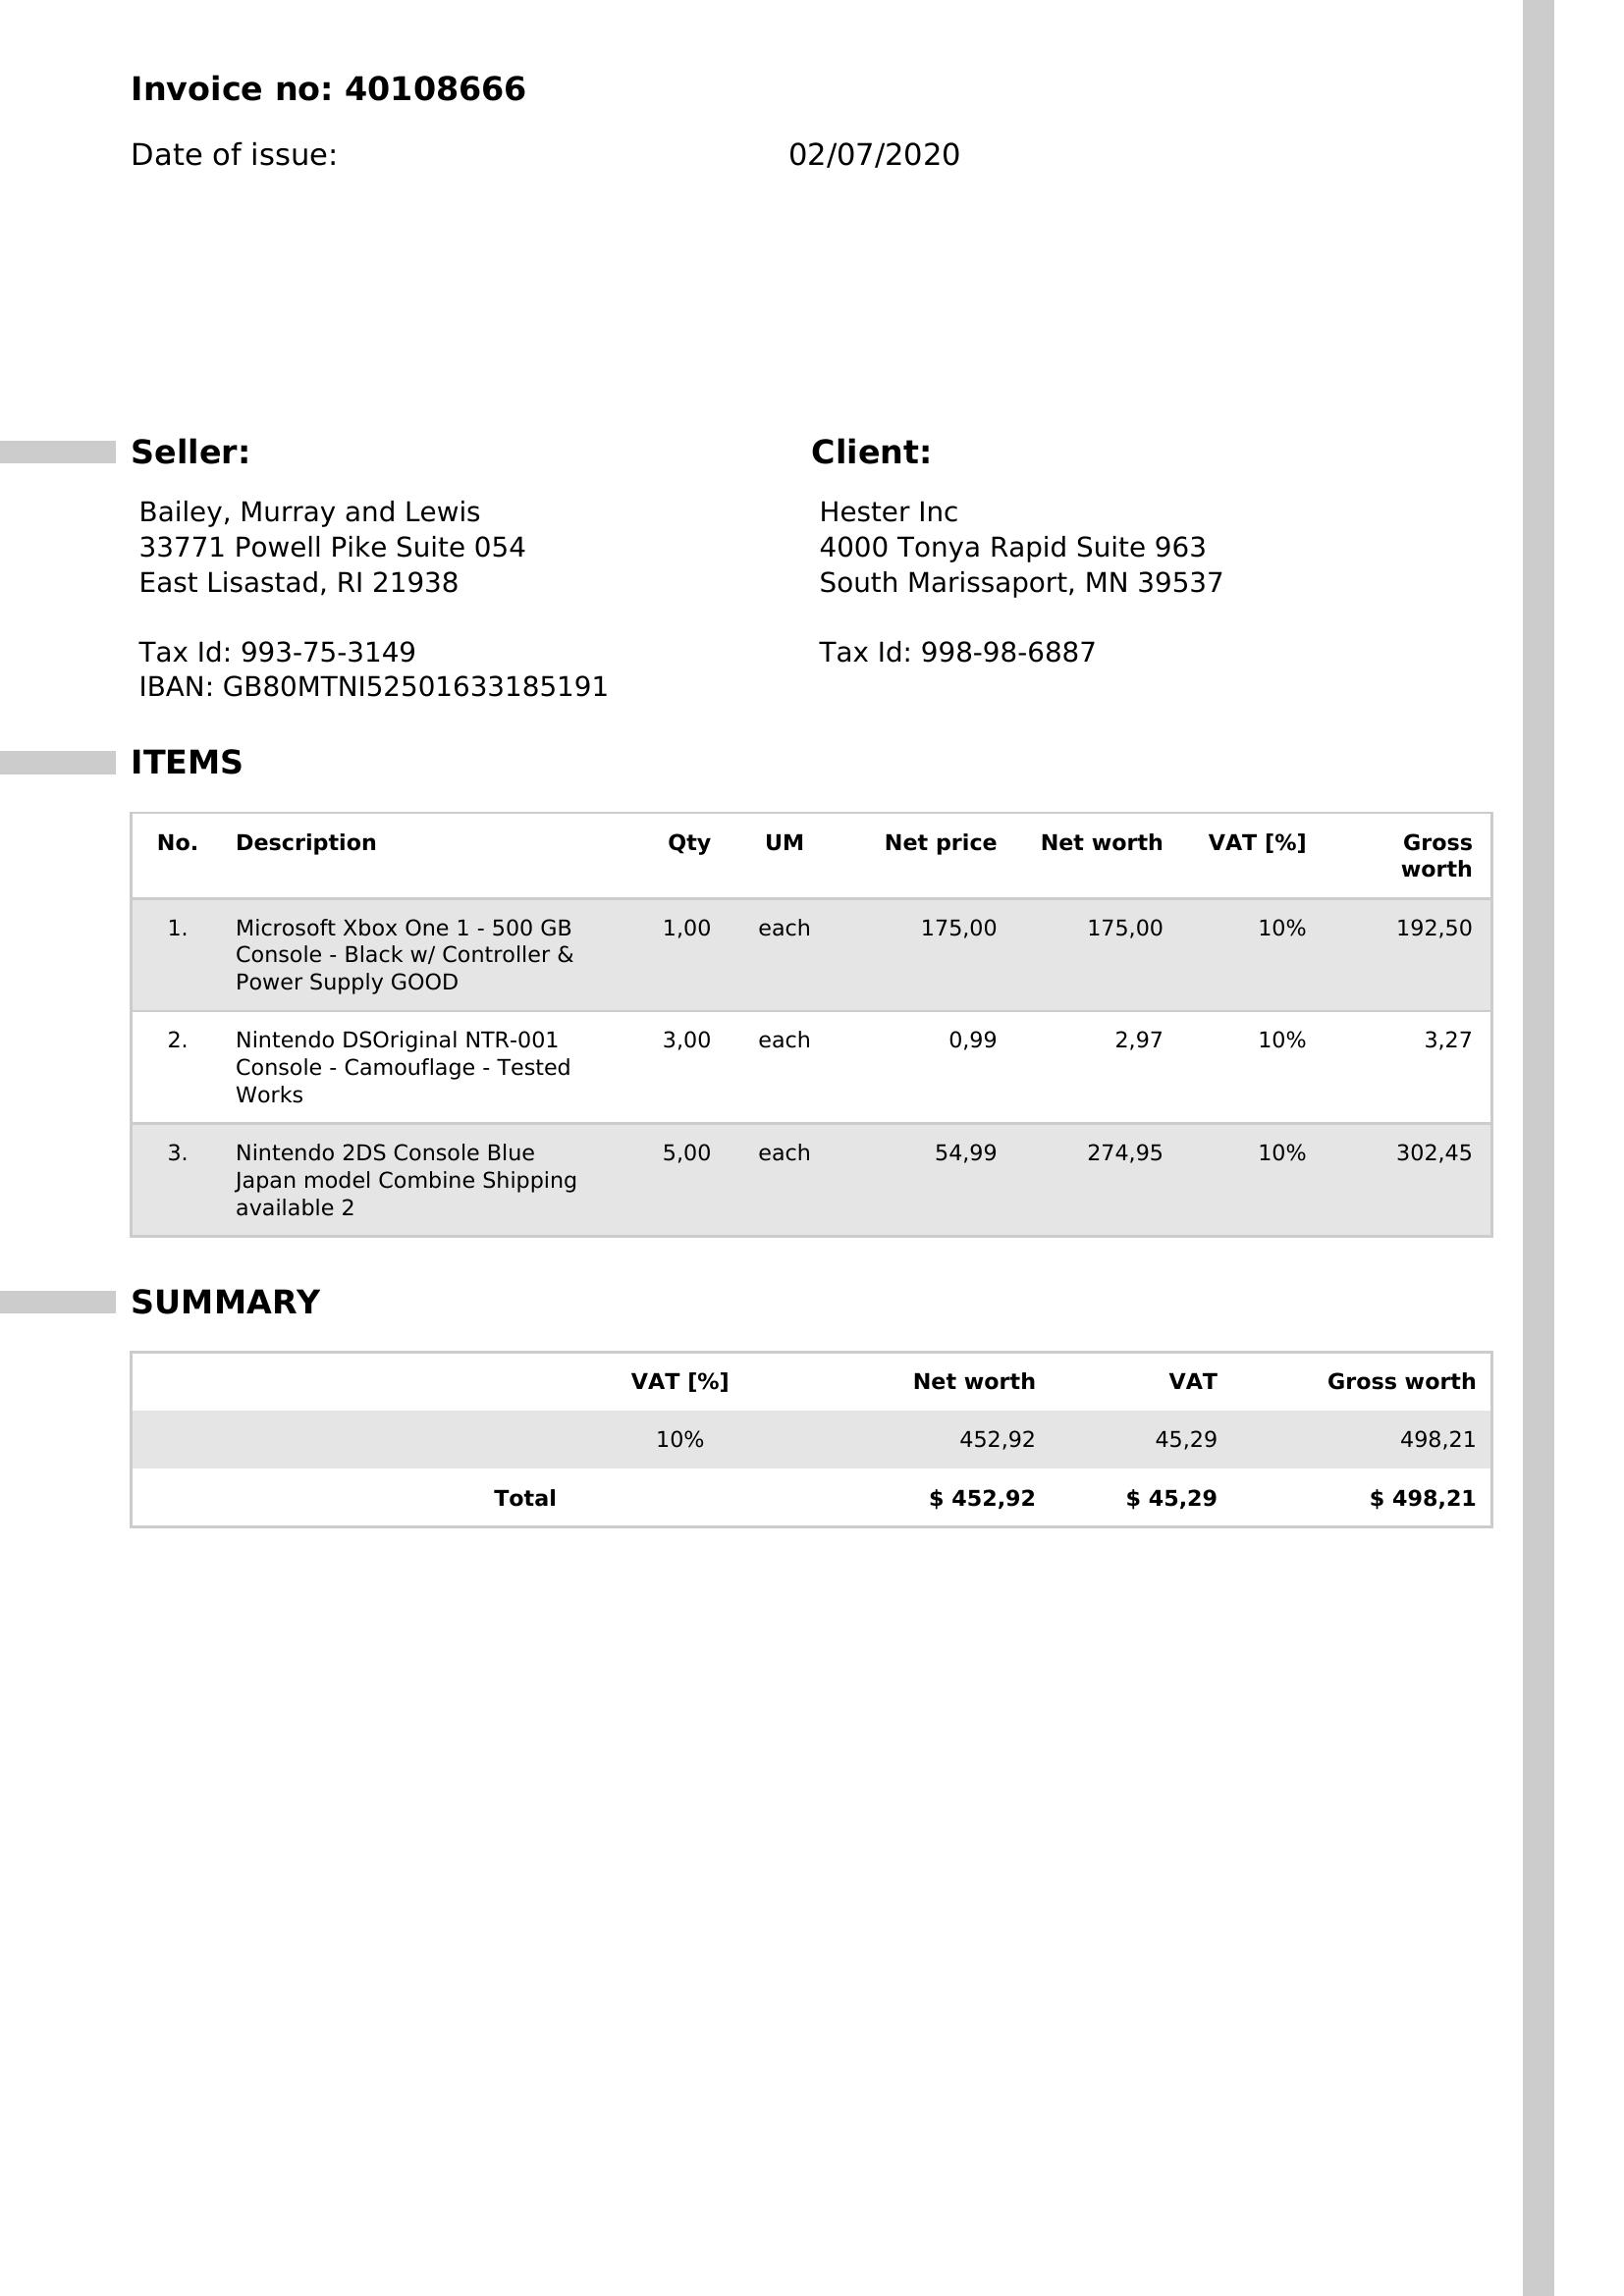

In [1000]:
display(
    Image(
        filename=str(row["path"])
    )
)

items line

In [1001]:
line_items = "ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. Microsoft Xbox One 1 - 500 GB 1,00 each 175,00 175,00 10% 192,50 Console Black wl Controller & Power Supply GOOD 2 Nintendo DSOriginal NTR-001 3,00 each 0,99 2,97 10% 3,27 Console Camouflage Tested Works 3 Nintendo 2DS Console Blue 5,00 each 54,99 274,95 10% 302,45 Japan model Combine Shipping available 2"

### Rule-based

Text:

```
1. Microsoft Xbox One 1 - 500 GB
1,00 each 175,00 175,00 10% 192,50
Console Black wl Controller & Power Supply GOOD
```

json:

```json
{
    "description": (
        "Microsoft Xbox One 1 - 500 GB "
        "Console Black wl Controller & Power Supply GOOD"
    ),
    "quantity": "1.00",
    "total_price": "192.50",
}
```

[item number] [description]
[quantity] each [net price] [net worth] [VAT %] [gross worth]

In [1002]:
def extract_items_section(text: str) -> str | None:
    match = re.search(
        r"\bITEMS\b(?P<items>.*?)\bSUMMARY\b",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )

    if match is None:
        return None

    return match.group("items").strip()

In [1003]:
items_section = extract_items_section(row['ocred_text'])
items_section

'No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. Microsoft Xbox One 1 - 500 GB 1,00 each 175,00 175,00 10% 192,50 Console Black wl Controller & Power Supply GOOD 2 Nintendo DSOriginal NTR-001 3,00 each 0,99 2,97 10% 3,27 Console Camouflage Tested Works 3 Nintendo 2DS Console Blue 5,00 each 54,99 274,95 10% 302,45 Japan model Combine Shipping available 2'

In [1020]:
MONEY_PATTERN = r"\d+(?:[ .]\d{3})*(?:[,.]\d{2})"

ITEM_VALUES_PATTERN = re.compile(
    rf"""
    (?P<quantity>{MONEY_PATTERN})
    \s+
    (?P<unit>[A-Za-z]+)
    \s+
    (?P<net_price>{MONEY_PATTERN})
    \s+
    (?P<net_worth>{MONEY_PATTERN})
    \s+
    (?P<vat>\d+(?:[,.]\d+)?%)
    \s+
    (?P<gross_worth>{MONEY_PATTERN})
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)

In [1014]:
matches = []
for match in ITEM_VALUES_PATTERN.finditer(items_section):
    print("quantity", match.group('quantity'), "unit", match.group("unit"), "net price", match.group("net_price"))

quantity 1,00 unit each net price 175,00
quantity 3,00 unit each net price 0,99
quantity 5,00 unit each net price 54,99


In [ ]:
matches = []
for match in ITEM_VALUES_PATTERN.finditer(items_section):
    print("quantity:", match.group('quantity'), "unit:", match.group("unit"), "net price:", match.group("net_price"), "net worth:", match.group("net_worth"))

quantity 1,00 unit each net price 175,00 net worth 175,00
quantity 3,00 unit each net price 0,99 net worth 2,97
quantity 5,00 unit each net price 54,99 net worth 274,95


In [ ]:
matches = []
for match in ITEM_VALUES_PATTERN.finditer(items_section):
    print("quantity:", match.group('quantity'), "unit:", match.group("unit"), "net price:", match.group("net_price"), "net worth:", match.group("net_worth"), "vat", match.group("vat"))

quantity: 1,00 unit: each net price: 175,00 net worth: 175,00 vat 10%
quantity: 3,00 unit: each net price: 0,99 net worth: 2,97 vat 10%
quantity: 5,00 unit: each net price: 54,99 net worth: 274,95 vat 10%


In [1021]:
matches = []
for match in ITEM_VALUES_PATTERN.finditer(items_section):
    print("quantity:", match.group('quantity'), "unit:", match.group("unit"), "net price:", match.group("net_price"), "net worth:", match.group("net_worth"), "vat", match.group("vat"), "ttotal price", match.group("gross_worth"))

quantity: 1,00 unit: each net price: 175,00 net worth: 175,00 vat 10% ttotal price 192,50
quantity: 3,00 unit: each net price: 0,99 net worth: 2,97 vat 10% ttotal price 3,27
quantity: 5,00 unit: each net price: 54,99 net worth: 274,95 vat 10% ttotal price 302,45


In [1022]:
value_matches = list(ITEM_VALUES_PATTERN.finditer(items_section))
value_matches

[<re.Match object; span=(96, 130), match='1,00 each 175,00 175,00 10% 192,50'>,
 <re.Match object; span=(209, 237), match='3,00 each 0,99 2,97 10% 3,27'>,
 <re.Match object; span=(298, 331), match='5,00 each 54,99 274,95 10% 302,45'>]

In [1039]:
items_section

'No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. Microsoft Xbox One 1 - 500 GB 1,00 each 175,00 175,00 10% 192,50 Console Black wl Controller & Power Supply GOOD 2 Nintendo DSOriginal NTR-001 3,00 each 0,99 2,97 10% 3,27 Console Camouflage Tested Works 3 Nintendo 2DS Console Blue 5,00 each 54,99 274,95 10% 302,45 Japan model Combine Shipping available 2'

In [1038]:

value_match = value_matches[0]
num_groups = 6
spans = [value_match.span(idx + 1) for idx in range(num_groups)]
spans

[(96, 100), (101, 105), (106, 112), (113, 119), (120, 123), (124, 130)]

In [1060]:

value_match = value_matches[0]
num_groups = 6
spans = [value_match.span(idx + 1) for idx in range(num_groups)]
spans

[(96, 100), (101, 105), (106, 112), (113, 119), (120, 123), (124, 130)]

In [1042]:
items_section[130:209]

' Console Black wl Controller & Power Supply GOOD 2 Nintendo DSOriginal NTR-001 '

In [1052]:
ocr_text = row['ocred_text']
ITEMS_HEADER_PATTERN = re.compile(
    r"""
    \s*
    (?:No\.?\s+)?
    Description
    \s+
    Qty\.?
    \s+
    U\.?M\.?
    \s+
    Net\s+price
    \s+
    Net\s+worth
    \s+
    VAT
    \s*
    (?:\[\s*%\s*\]|%|(?:\[\s*)?(?:percent)(?:\s*\])?)
    \s+
    Gross\s+worth
    \s*
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)

section_match = re.search(
    r"\bITEMS\b(?P<items>.*?)\bSUMMARY\b",
    ocr_text,
    flags=re.IGNORECASE | re.DOTALL,
)

section_start = section_match.start("items")
section_end = section_match.end("items")
section_text = text[section_start:section_end]
section_start, section_end, section_text

(280,
 654,
 ' Description Qty UM Net price Net worth VAT [%] Gross worth 1. Zara black dress in Small 2,00 each 25,00 50,00 10% 55,00 2 Speechless Green Brown White 1,00 each 7,00 7,00 10% 7,70 Psychedelic Sleeveless Dress Size Large 3 Newborn Toddler Baby Girls 5,00 each 9,15 45,75 10% 50,33 Floral Print Romper Dress Bodysuits Ouftits Clothes Vintage 80s All That Jazz Blue 3,00 each ')

In [1058]:
header_match = ITEMS_HEADER_PATTERN.match(section_text)
header_start = header_match.start()
header_end = header_match.end()
header_start, header_end, section_text[header_start:header_end]

(0, 60, ' Description Qty UM Net price Net worth VAT [%] Gross worth ')

In [1063]:
value_matches = list(ITEM_VALUES_PATTERN.finditer(section_text))
value_match = value_matches[0]
num_groups = 6
spans = [value_match.span(idx + 1) for idx in range(num_groups)]
spans

[(89, 93), (94, 98), (99, 104), (105, 110), (111, 114), (115, 120)]

In [1064]:
section_text[60:89]

'1. Zara black dress in Small '

In [ ]:
# ITEM_DESCRIPTION_PATTERN = re.compile(
#     r"""
#     ^\s*
#     (?P<item_number>[1-9]\d{0,2})
#     \s*
#     [.)]?
#     \s+
#     (?P<description>.+?)
#     \s*$
#     """,
#     flags=re.DOTALL | re.VERBOSE,
# )
# matches = list(ITEM_DESCRIPTION_PATTERN.finditer(section_text[60:89]))
# match = matches[-1]
# section_text[60:89][match.end():]
ITEM_DESCRIPTION_PATTERN = re.compile(
    r"^\s*(?P<item_number>\d+)[.)]?\s+(?P<description>.*?)\s*$"
)

value = "1. Zara black dress in Small "

match_ = ITEM_DESCRIPTION_PATTERN.match(section_text[60:89])
match_.group("description")

'Zara black dress in Small'

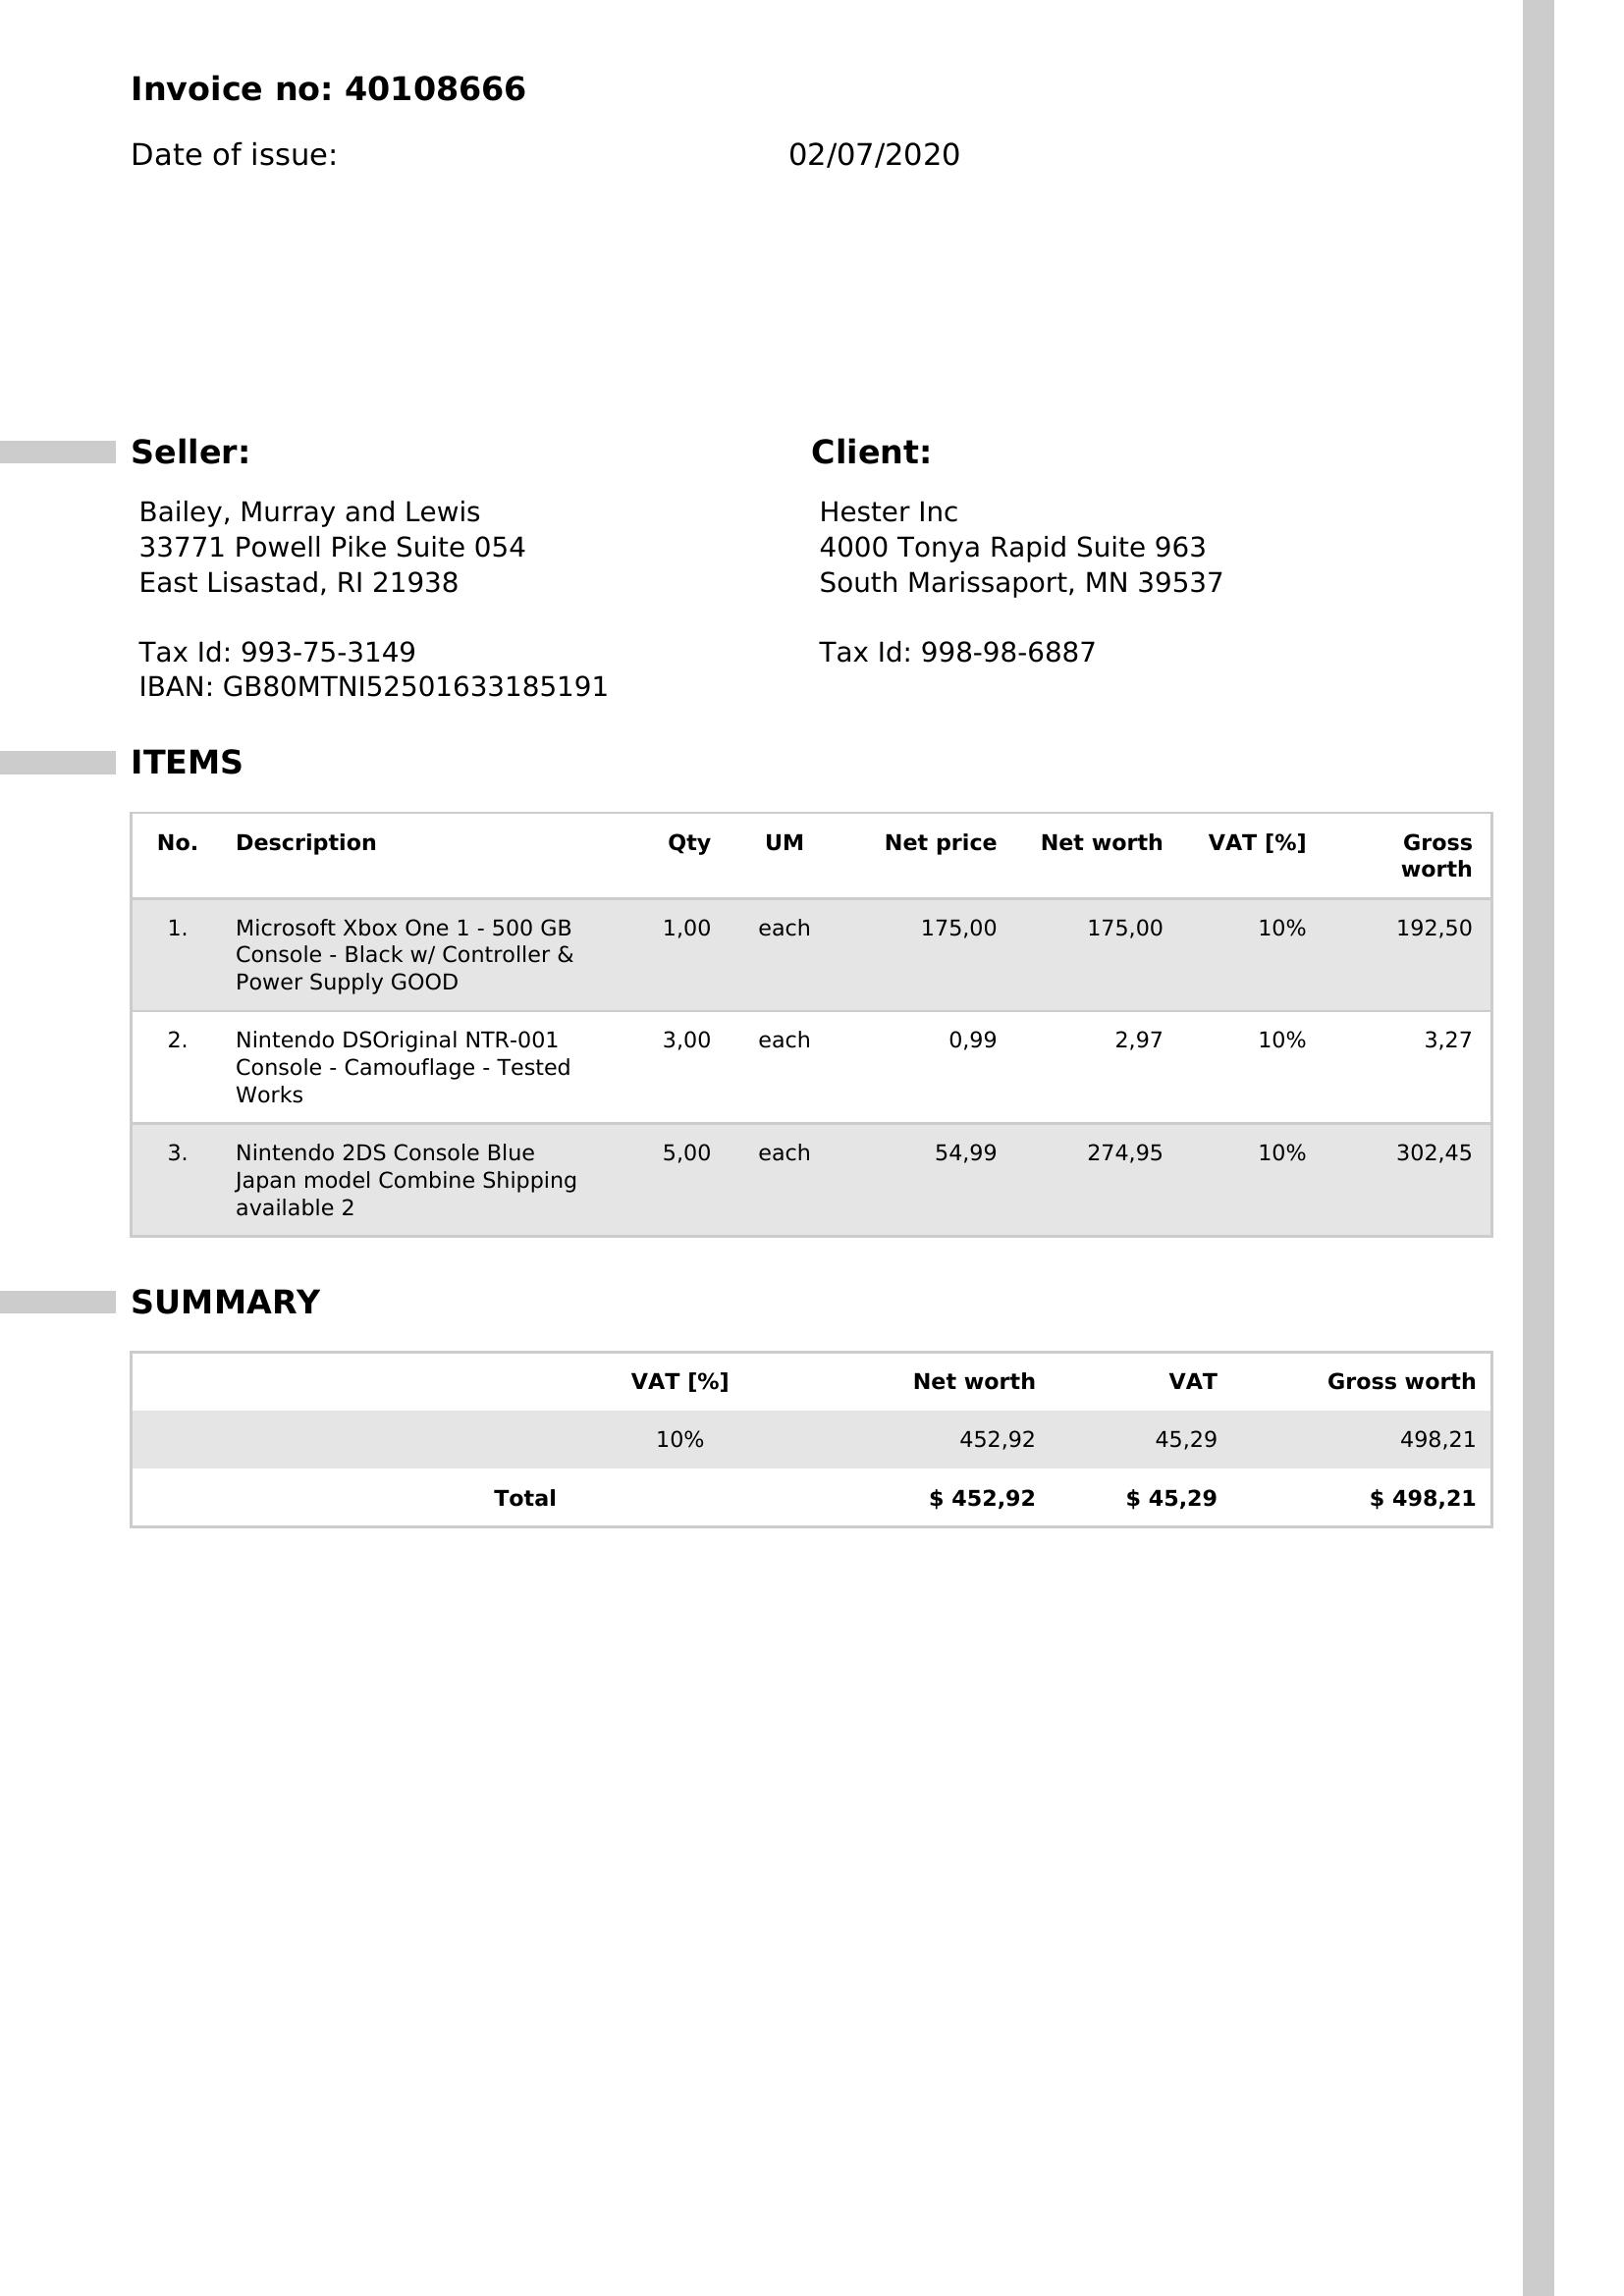

In [1093]:
display(
    Image(
        filename=str(row["path"])
    )
)

### Full line-items extraction

In [1161]:
ITEMS_SECTION_PATTERN = r"\bITEMS\b(?P<items>.*?)\bSUMMARY\b"
ITEMS_HEADER_PATTERN = re.compile(
    r"""
    \s*
    (?:No\.?\s+)?
    Description
    \s+
    Qty\.?
    \s+
    U\.?M\.?
    \s+
    Net\s+price
    \s+
    Net\s+worth
    \s+
    VAT
    \s*
    (?:\[\s*%\s*\]|%|(?:\[\s*)?(?:percent)(?:\s*\])?)
    \s+
    Gross\s+worth
    \s*
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)
ITEM_VALUES_PATTERN = re.compile(
    rf"""
    (?P<quantity>{MONEY_PATTERN})
    \s+
    (?P<unit>[A-Za-z]+)
    \s+
    (?P<net_price>{MONEY_PATTERN})
    \s+
    (?P<net_worth>{MONEY_PATTERN})
    \s+
    (?P<vat>\d+(?:[,.]\d+)?%)
    \s+
    (?P<gross_worth>{MONEY_PATTERN})
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)
ITEM_DESCRIPTION_PATTERN = re.compile(
    r"^\s*(?P<item_number>\d+)[.)]?\s+(?P<description>.*?)\s*$"
)


In [1135]:
class LineItem(BaseModel):
    item_number: int
    description: str
    quantity: str
    total_price: str


class ItemValueBlock(BaseModel):
    start: int
    end: int
    text: str
    quantity: str
    unit: str
    net_price: str
    net_worth: str
    vat: str
    gross_worth: str


def normalize_whitespace(value: str) -> str:
    return re.sub(r"\s+", " ", value).strip()

def split_at_expected_item(
    value: str,
    expected_item_number: int,
) -> tuple[str, str] | None:
    pattern = re.compile(
        rf"""
        (?<!\S)
        (?P<item_number>{expected_item_number})
        [.)]?
        (?=\s)
        \s+
        """,
        flags=re.VERBOSE,
    )

    matches = list(pattern.finditer(value))

    if not matches:
        return None

    # The last occurrence is usually the actual next-row marker.
    match = matches[-1]

    return (
        normalize_whitespace(value[:match.start()]),
        normalize_whitespace(value[match.end():]),
    )

def extract_line_items(text: str) -> list[LineItem] | None:
    spans: list[ItemValueBlock] = []
    section_match = re.search(
        r"\bITEMS\b(?P<items>.*?)\bSUMMARY\b",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )
    if not section_match:
        return

    section_start = section_match.start("items")
    section_end = section_match.end("items")
    section_text = text[section_start:section_end]

    header_match = ITEMS_HEADER_PATTERN.match(section_text)
    if not header_match:
        return

    header_start = header_match.start()
    header_end = header_match.end()

    value_blocks = [
        ItemValueBlock(
            start=match.start(),
            end=match.end(),
            text=match.group(0),
            quantity=match.group("quantity"),
            unit=match.group("unit"),
            net_price=match.group("net_price"),
            net_worth=match.group("net_worth"),
            vat=match.group("vat"),
            gross_worth=match.group("gross_worth"),
        )
        for match in ITEM_VALUES_PATTERN.finditer(
            section_text,
            header_end,
        )
    ]

    if not value_blocks:
        return []
    
    description_beginnings: list[str] = []
    description_continuations: list[str] = []

    # The first item starts between the header and first numeric block.
    first_prefix = section_text[
        header_end:value_blocks[0].start
    ]

    first_item_number = 1

    first_item_marker_pattern = re.compile(
        r"""
        ^\s*
        1
        [.)]?
        \s+
        """,
        flags=re.VERBOSE,
    )

    first_marker_match = first_item_marker_pattern.match(
        first_prefix
    )

    if first_marker_match is None:
        # OCR omitted the first item number.
        first_description = normalize_whitespace(
            first_prefix
        )
    else:
        first_description = normalize_whitespace(
            first_prefix[first_marker_match.end():]
        )

    description_beginnings.append(first_description)

    # Every gap contains:
    #
    # current item continuation
    # + next item number
    # + next item description beginning
    for index in range(len(value_blocks) - 1):
        current_block = value_blocks[index]
        next_block = value_blocks[index + 1]

        gap = section_text[
            current_block.end:next_block.start
        ]

        expected_item_number = first_item_number + index + 1

        split_result = split_at_expected_item(
            value=gap,
            expected_item_number=expected_item_number,
        )
        if split_result is None:
            return None

        continuation, next_beginning = split_result

        description_continuations.append(continuation)
        description_beginnings.append(next_beginning)

    # The text after the final numeric block belongs to the final item.
    final_continuation = section_text[
        value_blocks[-1].end:
    ]
    description_continuations.append(
        normalize_whitespace(final_continuation)
    )
    line_items: list[LineItem] = []
    for index, value_block in enumerate(value_blocks):
        description = normalize_whitespace(
            " ".join(
                part
                for part in [
                    description_beginnings[index],
                    description_continuations[index],
                ]
                if part
            )
        )

        line_items.append(
            LineItem(
                item_number=first_item_number + index,
                description=description,
                quantity=value_block.quantity,
                total_price=value_block.gross_worth,
            )
        )

    return line_items    

line_items = extract_line_items(ocr_text)
line_items

[LineItem(item_number=1, description='Microsoft Xbox One 1 - 500 GB Console Black wl Controller & Power Supply GOOD', quantity='1,00', total_price='192,50'),
 LineItem(item_number=2, description='Nintendo DSOriginal NTR-001 Console Camouflage Tested Works', quantity='3,00', total_price='3,27'),
 LineItem(item_number=3, description='Nintendo 2DS Console Blue Japan model Combine Shipping available 2', quantity='5,00', total_price='302,45')]

In [1140]:
row = df.iloc[7]
row

,7
file_name,batch1-0108.jpg
json_data,"\n{\n ""invoice"": {\n ""client_name"": ""Combs..."
ocred_text,Invoice no: 20012449 Date of issue: 04/22/2013...
subdir,batch1_1
source_group,batch_1/batch_1
csv_path,/content/invoices/batch_1/batch_1/batch1_1.csv
path,/content/invoices/batch_1/batch_1/batch1_1/bat...
target,{'invoice': {'client_address': '433 Ferguson L...
top_level_keys,"[invoice, items, payment_instructions, subtotal]"
target_text,"{""invoice"":{""client_address"":""433 Ferguson Lan..."


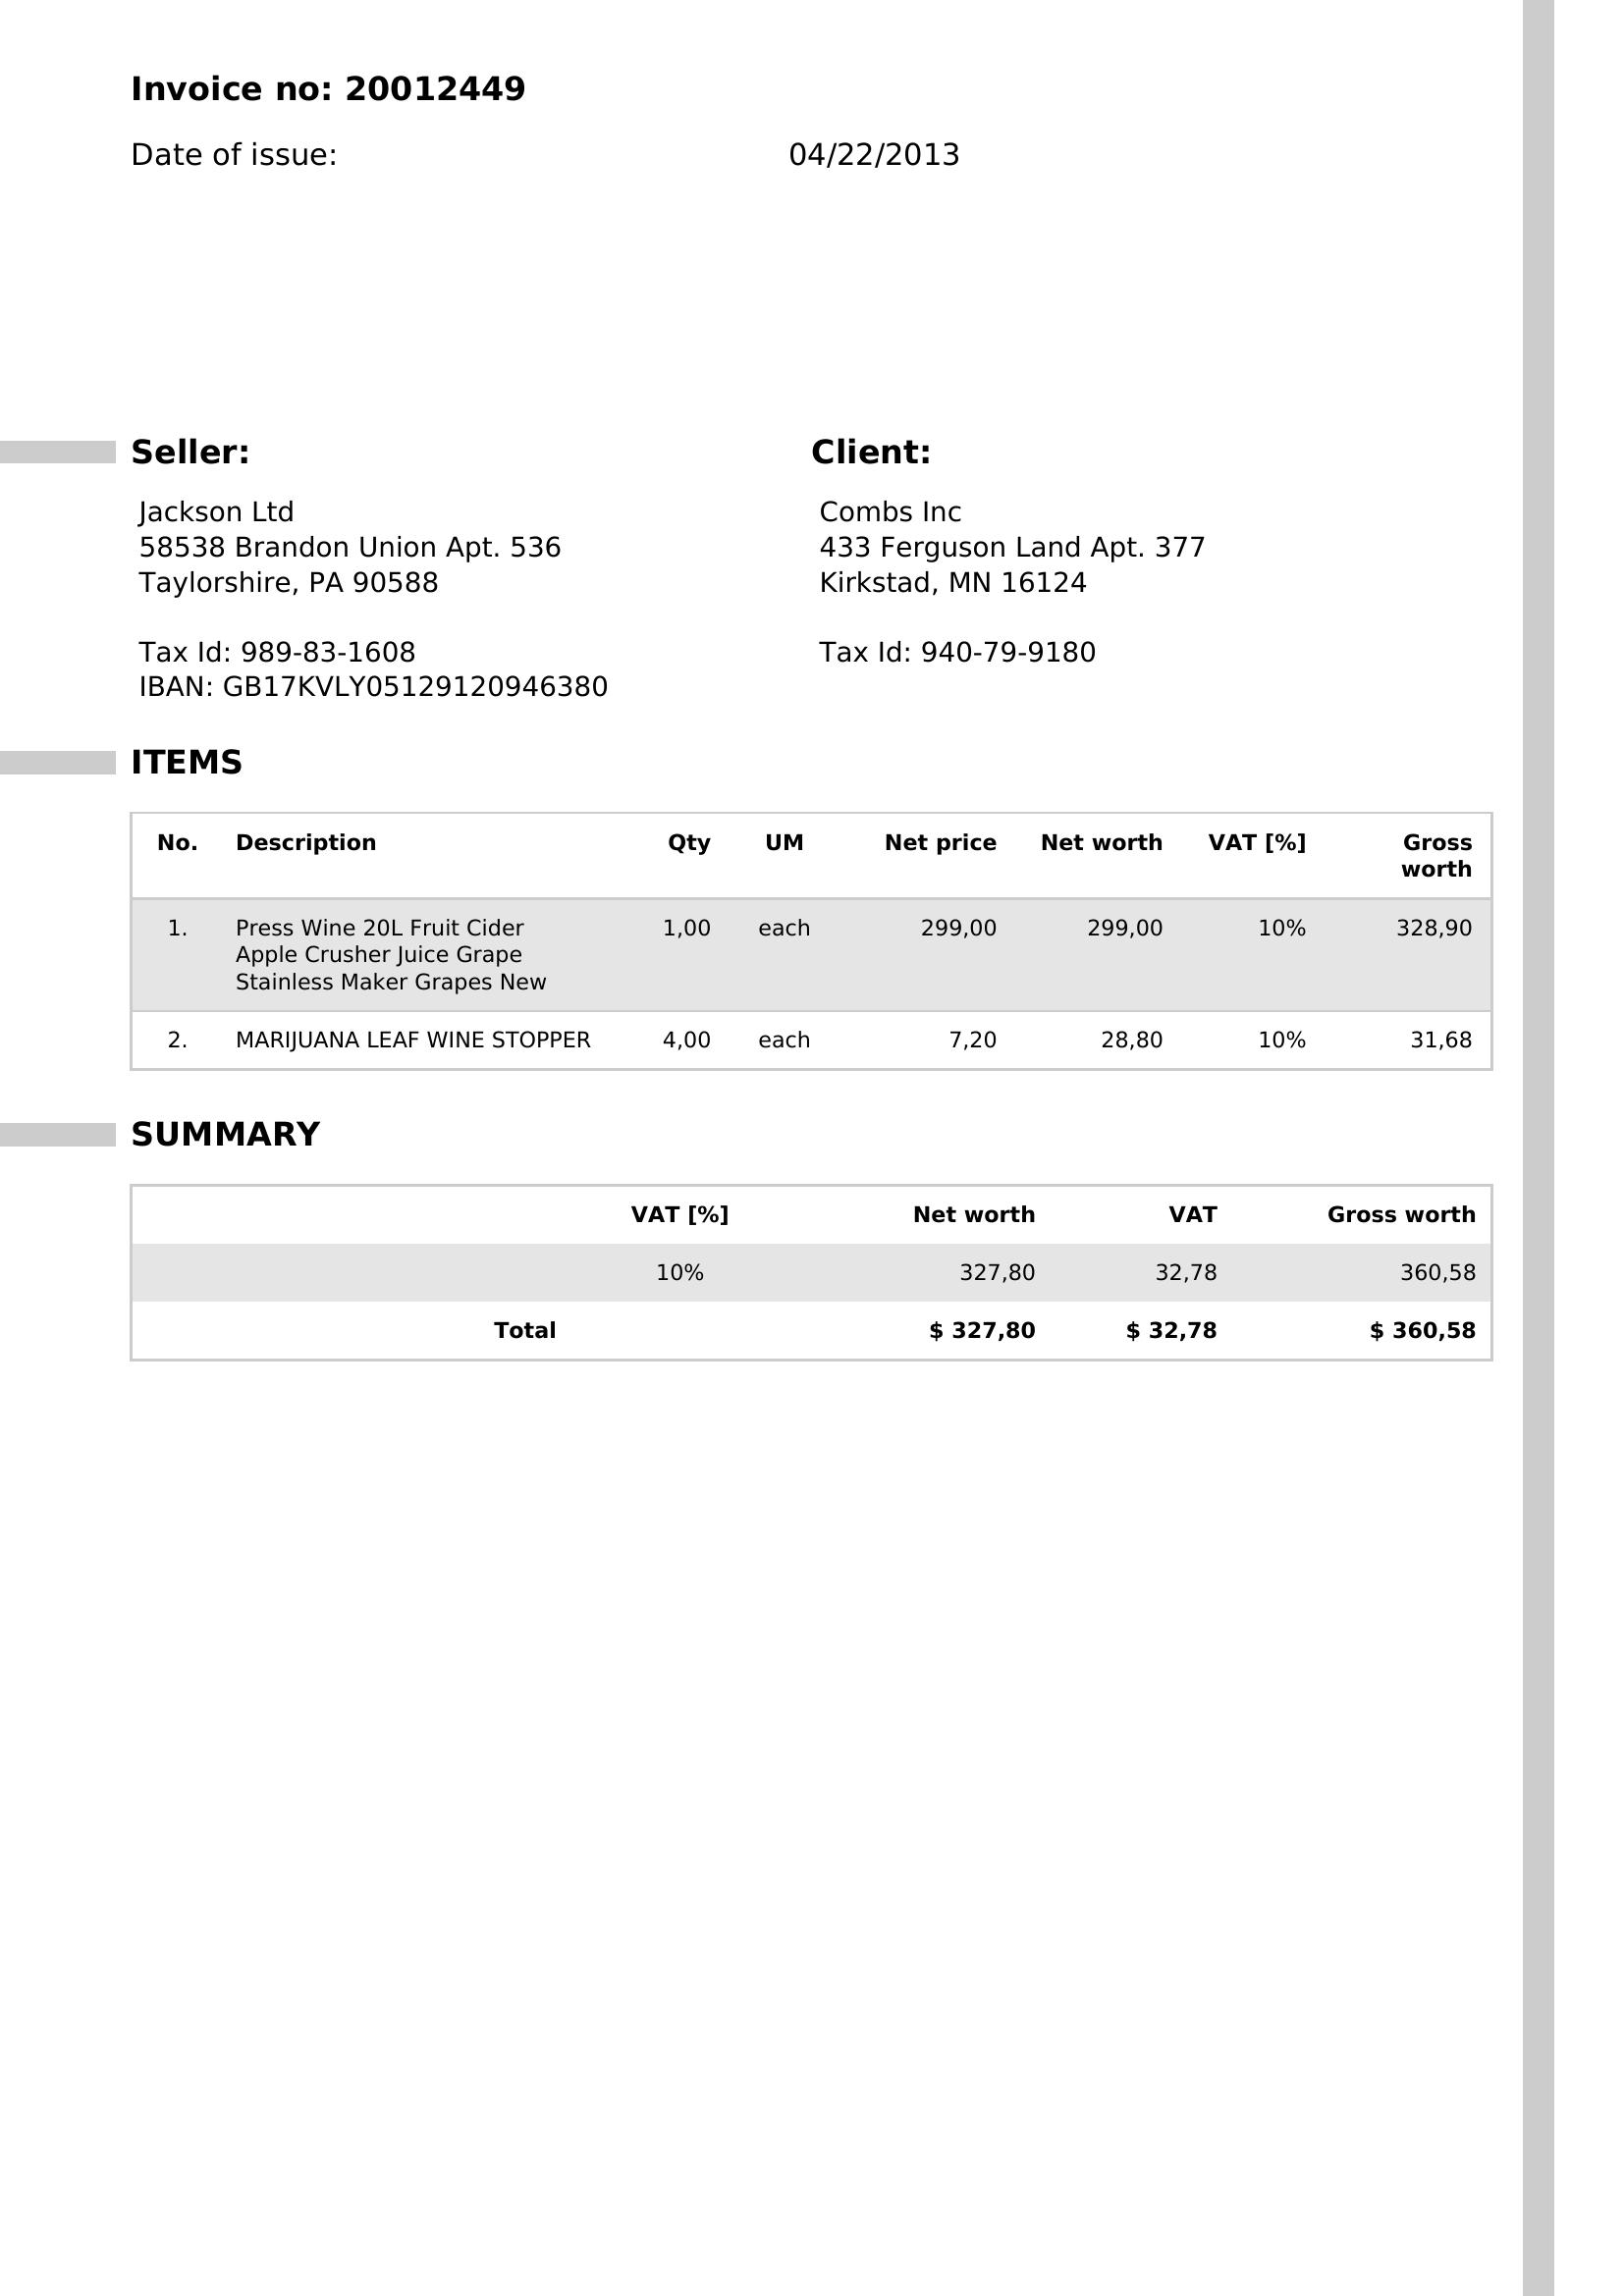

In [1141]:
display(
    Image(
        filename=str(row["path"])
    )
)

In [1142]:
line_items = extract_line_items(row['ocred_text'])
line_items

[LineItem(item_number=1, description='Press Wine 20L Fruit Cider Apple Crusher Juice Grape Stainless Maker Grapes New', quantity='1,00', total_price='328,90'),
 LineItem(item_number=2, description='MARIJUANA LEAF WINE STOPPER', quantity='4,00', total_price='31,68')]

In [1139]:
row['ocred_text']

'Invoice no: 57290992 Date of issue: 10/03/2011 Seller: Client: Adams PLC Johnson, Daniels and Ramirez USS Moon 6889 Oliver Summit FPO AA 34591 South Ebony, NY 23978 Tax Id: 964-98-1799 Tax Id: 925-71-0496 IBAN: GB3OOLCJ81769735097340 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 25"x25 Marble Black Top 5,00 each 2 789,00 13 945,00 10% 15 339,50 custom Table Carnelian Marquetry Art Halloween Gift 2 7\'x4 Blue Random Marble 3,00 each 8 194,09 24 582,27 10% 27 040,50 Dining Hallway Table Top Lapis Lazuli Decor E947A 3 6\'x3\' White Marble Dining Table 4,00 each 6 408,49 25 633,96 10% 28 197,36 Top Multi Inlay Floral Elephant Art Decor H4952 SUMMARY VAT [%] Net worth VAT Gross worth 10% 64 161,23 6 416,12 70 577,35 Total $ 64 161,23 $ 6 416,12 $ 70 577,35 Inlay'

###  1. Evaluation normalizers

In [1143]:
import json
import re
import unicodedata
from decimal import Decimal, InvalidOperation


def normalize_description(value: str | None) -> str | None:
    if value is None:
        return None

    value = unicodedata.normalize("NFKC", str(value))
    value = re.sub(r"\s+", " ", value)

    return value.strip().casefold()


def normalize_number(value: str | int | float | None) -> Decimal | None:
    if value is None:
        return None

    compact = unicodedata.normalize("NFKC", str(value))
    compact = re.sub(r"[^\d,.\- ]", "", compact)
    compact = compact.replace(" ", "")

    if not compact:
        return None

    if "," in compact and "." in compact:
        if compact.rfind(",") > compact.rfind("."):
            compact = compact.replace(".", "")
            compact = compact.replace(",", ".")
        else:
            compact = compact.replace(",", "")
    elif "," in compact:
        compact = compact.replace(",", ".")

    try:
        return Decimal(compact)
    except InvalidOperation:
        return None

### 2. Extract expected items from JSON

In [1144]:
def extract_expected_items(
    json_data: str,
) -> list[dict]:
    target = json.loads(json_data)
    return target.get("items") or []

In [1145]:
sample_target = json.loads(df.iloc[0]["json_data"])

sample_target.keys()

dict_keys(['invoice', 'items', 'subtotal', 'payment_instructions'])

### 3. Run the parser over the whole DataFrame

In [1146]:
document_records = []
item_records = []

for row_index, row in df.iterrows():
    text = row["ocred_text"]
    expected_items = extract_expected_items(
        row["json_data"]
    )

    parsing_error = None

    try:
        predicted_items = extract_line_items(text)
    except Exception as error:
        predicted_items = None
        parsing_error = (
            f"{type(error).__name__}: {error}"
        )

    parser_succeeded = predicted_items is not None
    predicted_items = predicted_items or []

    expected_count = len(expected_items)
    predicted_count = len(predicted_items)

    document_records.append({
        "row_index": row_index,
        "file_name": row.get("file_name"),
        "expected_count": expected_count,
        "predicted_count": predicted_count,
        "count_difference": (
            predicted_count - expected_count
        ),
        "count_matches": (
            predicted_count == expected_count
        ),
        "parser_succeeded": parser_succeeded,
        "error": parsing_error,
    })

    maximum_count = max(
        expected_count,
        predicted_count,
    )

    for item_index in range(maximum_count):
        expected = (
            expected_items[item_index]
            if item_index < expected_count
            else None
        )
        predicted = (
            predicted_items[item_index]
            if item_index < predicted_count
            else None
        )

        expected_description = (
            expected.get("description")
            if expected is not None
            else None
        )
        expected_quantity = (
            expected.get("quantity")
            if expected is not None
            else None
        )
        expected_total = (
            expected.get("total_price")
            if expected is not None
            else None
        )

        predicted_description = (
            predicted.description
            if predicted is not None
            else None
        )
        predicted_quantity = (
            predicted.quantity
            if predicted is not None
            else None
        )
        predicted_total = (
            predicted.total_price
            if predicted is not None
            else None
        )

        description_matches = (
            expected is not None
            and predicted is not None
            and normalize_description(
                expected_description
            )
            == normalize_description(
                predicted_description
            )
        )

        quantity_matches = (
            expected is not None
            and predicted is not None
            and normalize_number(expected_quantity)
            == normalize_number(predicted_quantity)
        )

        total_matches = (
            expected is not None
            and predicted is not None
            and normalize_number(expected_total)
            == normalize_number(predicted_total)
        )

        item_records.append({
            "row_index": row_index,
            "file_name": row.get("file_name"),
            "item_index": item_index,
            "expected_present": expected is not None,
            "predicted_present": predicted is not None,
            "expected_description": expected_description,
            "predicted_description": predicted_description,
            "description_matches": description_matches,
            "expected_quantity": expected_quantity,
            "predicted_quantity": predicted_quantity,
            "quantity_matches": quantity_matches,
            "expected_total_price": expected_total,
            "predicted_total_price": predicted_total,
            "total_price_matches": total_matches,
            "complete_item_matches": (
                description_matches
                and quantity_matches
                and total_matches
            ),
        })

In [1147]:
document_report = pd.DataFrame(document_records)
item_report = pd.DataFrame(item_records)

### 4. Document-level summary

In [1148]:
document_summary = pd.DataFrame([
    {
        "metric": "Documents",
        "correct": len(document_report),
        "support": len(document_report),
        "rate": 1.0,
    },
    {
        "metric": "Parser succeeded",
        "correct": int(
            document_report["parser_succeeded"].sum()
        ),
        "support": len(document_report),
        "rate": document_report[
            "parser_succeeded"
        ].mean(),
    },
    {
        "metric": "Correct item count",
        "correct": int(
            document_report["count_matches"].sum()
        ),
        "support": len(document_report),
        "rate": document_report[
            "count_matches"
        ].mean(),
    },
])

document_summary

,metric,correct,support,rate
0,Documents,1413,1413,1.000000
1,Parser succeeded,629,1413,0.445152
2,Correct item count,625,1413,0.442321


In [1149]:
document_report[
    "count_difference"
].value_counts().sort_index()

,count
count_difference,
-7,205
-6,192
-5,210
-4,164
-3,10
-2,3
-1,4
0,625


### 5. Field-level summary

In [1150]:
expected_item_report = item_report[
    item_report["expected_present"]
].copy()

item_summary = pd.DataFrame([
    {
        "field": "item detected",
        "matches": int(
            expected_item_report[
                "predicted_present"
            ].sum()
        ),
        "support": len(expected_item_report),
        "match_rate": expected_item_report[
            "predicted_present"
        ].mean(),
    },
    {
        "field": "description",
        "matches": int(
            expected_item_report[
                "description_matches"
            ].sum()
        ),
        "support": len(expected_item_report),
        "match_rate": expected_item_report[
            "description_matches"
        ].mean(),
    },
    {
        "field": "quantity",
        "matches": int(
            expected_item_report[
                "quantity_matches"
            ].sum()
        ),
        "support": len(expected_item_report),
        "match_rate": expected_item_report[
            "quantity_matches"
        ].mean(),
    },
    {
        "field": "total_price",
        "matches": int(
            expected_item_report[
                "total_price_matches"
            ].sum()
        ),
        "support": len(expected_item_report),
        "match_rate": expected_item_report[
            "total_price_matches"
        ].mean(),
    },
    {
        "field": "complete item",
        "matches": int(
            expected_item_report[
                "complete_item_matches"
            ].sum()
        ),
        "support": len(expected_item_report),
        "match_rate": expected_item_report[
            "complete_item_matches"
        ].mean(),
    },
])

item_summary

,field,matches,support,match_rate
0,item detected,1267,5600,0.226250
1,description,813,5600,0.145179
2,quantity,1266,5600,0.226071
3,total_price,1214,5600,0.216786
4,complete item,778,5600,0.138929


### 6. Inspect parser failures

In [1151]:
document_report.loc[
    ~document_report["parser_succeeded"],
    [
        "row_index",
        "file_name",
        "expected_count",
        "error",
    ],
].head(20)

,row_index,file_name,expected_count,error
0,0,batch1-0494.jpg,5,None
3,3,batch1-0497.jpg,7,None
10,10,batch1-0187.jpg,7,None
11,11,batch1-0039.jpg,4,None
12,12,batch1-0490.jpg,6,None
15,15,batch1-0210.jpg,7,None
16,16,batch1-0020.jpg,5,None
20,20,batch1-0136.jpg,7,None
21,21,batch1-0274.jpg,6,None
23,23,batch1-0384.jpg,6,None


In [1152]:
document_report.loc[
    ~document_report["count_matches"],
    [
        "row_index",
        "file_name",
        "expected_count",
        "predicted_count",
        "count_difference",
        "error",
    ],
].head(20)

,row_index,file_name,expected_count,predicted_count,count_difference,error
0,0,batch1-0494.jpg,5,0,-5,None
3,3,batch1-0497.jpg,7,0,-7,None
10,10,batch1-0187.jpg,7,0,-7,None
11,11,batch1-0039.jpg,4,0,-4,None
12,12,batch1-0490.jpg,6,0,-6,None
15,15,batch1-0210.jpg,7,0,-7,None
16,16,batch1-0020.jpg,5,0,-5,None
20,20,batch1-0136.jpg,7,0,-7,None
21,21,batch1-0274.jpg,6,0,-6,None
23,23,batch1-0384.jpg,6,0,-6,None


###  7. Inspect field mismatches

In [1153]:
item_report.loc[
    item_report["expected_present"]
    & ~item_report["description_matches"],
    [
        "row_index",
        "file_name",
        "item_index",
        "expected_description",
        "predicted_description",
    ],
].head(20)

,row_index,file_name,item_index,expected_description,predicted_description
0,0,batch1-0494.jpg,0,Stemware Rack Display Kitchen\nWine Glass Hold...,None
1,0,batch1-0494.jpg,1,VTG (4) 7 Ounce Since 1852\nMilk Bottle Wine C...,None
2,0,batch1-0494.jpg,2,Vintage Crystal Red Wine\nGlasses NOS West Ger...,None
3,0,batch1-0494.jpg,3,3 Ikea Stainless Steel 4-bottle\nWine Rack 300...,None
4,0,batch1-0494.jpg,4,"Lolita ""Wine Bouquet"" Hand\nPainted and Decora...",None
6,1,batch1-0489.jpg,1,Lotto Youth Boys Fuerzapura L500 Jr Soccer Cle...,Lotto Youth Boys Fuerzapura LSOO Jr Soccer Cle...
7,2,batch1-0499.jpg,0,Microsoft Xbox One 1 - 500 GB\nConsole - Black...,Microsoft Xbox One 1 - 500 GB Console Black wl...
8,2,batch1-0499.jpg,1,Nintendo DSOriginal NTR-001\nConsole - Camoufl...,Nintendo DSOriginal NTR-001 Console Camouflage...
10,3,batch1-0497.jpg,0,Bcbgeneration Black Sleeveless Lace Back Cut O...,None
11,3,batch1-0497.jpg,1,2pcs baby boys clothes cotton hooded top+pants...,None


In [1154]:
item_report.loc[
    item_report["expected_present"]
    & ~item_report["quantity_matches"],
    [
        "row_index",
        "file_name",
        "item_index",
        "expected_quantity",
        "predicted_quantity",
    ],
].head(20)

,row_index,file_name,item_index,expected_quantity,predicted_quantity
0,0,batch1-0494.jpg,0,1.00,None
1,0,batch1-0494.jpg,1,1.00,None
2,0,batch1-0494.jpg,2,1.00,None
3,0,batch1-0494.jpg,3,4.00,None
4,0,batch1-0494.jpg,4,1.00,None
10,3,batch1-0497.jpg,0,2.00,None
11,3,batch1-0497.jpg,1,5.00,None
12,3,batch1-0497.jpg,2,1.00,None
13,3,batch1-0497.jpg,3,5.00,None
14,3,batch1-0497.jpg,4,2.00,None


In [1155]:
item_report.loc[
    item_report["expected_present"]
    & ~item_report["total_price_matches"],
    [
        "row_index",
        "file_name",
        "item_index",
        "expected_total_price",
        "predicted_total_price",
    ],
].head(20)


,row_index,file_name,item_index,expected_total_price,predicted_total_price
0,0,batch1-0494.jpg,0,46.55,None
1,0,batch1-0494.jpg,1,15.40,None
2,0,batch1-0494.jpg,2,39.00,None
3,0,batch1-0494.jpg,3,110.00,None
4,0,batch1-0494.jpg,4,22.00,None
10,3,batch1-0497.jpg,0,6.58,None
11,3,batch1-0497.jpg,1,60.45,None
12,3,batch1-0497.jpg,2,324.50,None
13,3,batch1-0497.jpg,3,44.00,None
14,3,batch1-0497.jpg,4,44.00,None


### 8. Whole-document line-item accuracy

In [1156]:
document_item_accuracy = (
    item_report
    .groupby("row_index")
    .agg(
        all_items_exact=(
            "complete_item_matches",
            "all",
        ),
    )
    .reset_index()
)

In [1157]:
document_item_accuracy = (
    document_item_accuracy.merge(
        document_report[
            ["row_index", "count_matches"]
        ],
        on="row_index",
        how="left",
    )
)

document_item_accuracy["document_exact"] = (
    document_item_accuracy["count_matches"]
    & document_item_accuracy["all_items_exact"]
)

pd.DataFrame([
    {
        "metric": "All line items exact",
        "correct": int(
            document_item_accuracy[
                "document_exact"
            ].sum()
        ),
        "support": len(document_item_accuracy),
        "rate": document_item_accuracy[
            "document_exact"
        ].mean(),
    }
])


,metric,correct,support,rate
0,All line items exact,278,1413,0.196745


In [1158]:
detected_items = item_report.loc[
    item_report["expected_present"]
    & item_report["predicted_present"]
].copy()

conditional_summary = pd.DataFrame([
    {
        "metric": "Document parser coverage",
        "matches": int(
            document_report["parser_succeeded"].sum()
        ),
        "support": len(document_report),
        "rate": document_report[
            "parser_succeeded"
        ].mean(),
    },
    {
        "metric": "Correct count when parser succeeds",
        "matches": int(
            document_report.loc[
                document_report["parser_succeeded"],
                "count_matches",
            ].sum()
        ),
        "support": int(
            document_report["parser_succeeded"].sum()
        ),
        "rate": document_report.loc[
            document_report["parser_succeeded"],
            "count_matches",
        ].mean(),
    },
    {
        "metric": "Item extraction coverage",
        "matches": len(detected_items),
        "support": len(expected_item_report),
        "rate": (
            len(detected_items)
            / len(expected_item_report)
        ),
    },
    {
        "metric": "Description accuracy when detected",
        "matches": int(
            detected_items[
                "description_matches"
            ].sum()
        ),
        "support": len(detected_items),
        "rate": detected_items[
            "description_matches"
        ].mean(),
    },
    {
        "metric": "Quantity accuracy when detected",
        "matches": int(
            detected_items[
                "quantity_matches"
            ].sum()
        ),
        "support": len(detected_items),
        "rate": detected_items[
            "quantity_matches"
        ].mean(),
    },
    {
        "metric": "Total-price accuracy when detected",
        "matches": int(
            detected_items[
                "total_price_matches"
            ].sum()
        ),
        "support": len(detected_items),
        "rate": detected_items[
            "total_price_matches"
        ].mean(),
    },
    {
        "metric": "Complete-item accuracy when detected",
        "matches": int(
            detected_items[
                "complete_item_matches"
            ].sum()
        ),
        "support": len(detected_items),
        "rate": detected_items[
            "complete_item_matches"
        ].mean(),
    },
])

conditional_summary

,metric,matches,support,rate
0,Document parser coverage,629,1413,0.445152
1,Correct count when parser succeeds,625,629,0.993641
2,Item extraction coverage,1267,5600,0.226250
3,Description accuracy when detected,813,1267,0.641673
4,Quantity accuracy when detected,1266,1267,0.999211
5,Total-price accuracy when detected,1214,1267,0.958169
6,Complete-item accuracy when detected,778,1267,0.614049


In [1162]:
def diagnose_line_item_parser(
    text: str,
    expected_count: int,
) -> dict:
    section_match = re.search(
        ITEMS_SECTION_PATTERN,
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )

    if section_match is None:
        return {
            "status": "section_not_found",
            "numeric_blocks": 0,
            "failed_item_number": None,
            "failure_gap": None,
        }

    section_text = section_match.group("items")

    header_match = ITEMS_HEADER_PATTERN.match(
        section_text
    )

    if header_match is None:
        return {
            "status": "header_not_found",
            "numeric_blocks": 0,
            "failed_item_number": None,
            "failure_gap": section_text[:200],
        }

    value_blocks = list(
        ITEM_VALUES_PATTERN.finditer(
            section_text,
            header_match.end(),
        )
    )

    if not value_blocks:
        return {
            "status": "numeric_blocks_not_found",
            "numeric_blocks": 0,
            "failed_item_number": None,
            "failure_gap": section_text[
                header_match.end():
                header_match.end() + 300
            ],
        }

    for index in range(len(value_blocks) - 1):
        current_block = value_blocks[index]
        next_block = value_blocks[index + 1]

        expected_next_item = index + 2

        gap = section_text[
            current_block.end():
            next_block.start()
        ]

        split_result = split_at_expected_item(
            value=gap,
            expected_item_number=expected_next_item,
        )

        if split_result is None:
            return {
                "status": "item_boundary_not_found",
                "numeric_blocks": len(value_blocks),
                "failed_item_number": (
                    expected_next_item
                ),
                "failure_gap": gap,
            }

    if len(value_blocks) != expected_count:
        return {
            "status": "numeric_count_mismatch",
            "numeric_blocks": len(value_blocks),
            "failed_item_number": None,
            "failure_gap": None,
        }

    return {
        "status": "success",
        "numeric_blocks": len(value_blocks),
        "failed_item_number": None,
        "failure_gap": None,
    }

In [1164]:
diagnostic_records = []
for row_index, row in df.iterrows():
    expected_items = extract_expected_items(
        row["json_data"]
    )

    diagnosis = diagnose_line_item_parser(
        text=row["ocred_text"],
        expected_count=len(expected_items),
    )

    diagnostic_records.append({
        "row_index": row_index,
        "file_name": row.get("file_name"),
        "expected_count": len(expected_items),
        **diagnosis,
    })

diagnostic_report = pd.DataFrame(
    diagnostic_records
)


In [1165]:
diagnostic_report[
    "status"
].value_counts()

,count
status,
item_boundary_not_found,784
success,625
numeric_count_mismatch,4


In [1166]:
diagnostic_report[
    "status"
].value_counts(normalize=True)

,proportion
status,
item_boundary_not_found,0.554848
success,0.442321
numeric_count_mismatch,0.002831


In [1167]:
diagnostic_report.loc[
    diagnostic_report["status"]
    == "item_boundary_not_found",
    [
        "row_index",
        "file_name",
        "expected_count",
        "numeric_blocks",
        "failed_item_number",
        "failure_gap",
    ],
].head(20)

,row_index,file_name,expected_count,numeric_blocks,failed_item_number,failure_gap
0,0,batch1-0494.jpg,5,5,4.0,Glasses NOS West Germany 1983 6 10 ounce eleg...
3,3,batch1-0497.jpg,7,6,4.0,Ivory Wedding Dress with Beading Shein Blue A...
10,10,batch1-0187.jpg,7,7,4.0,Desktop Computer i5-9500T 8GB 256GB SSD WIOP ...
11,11,batch1-0039.jpg,4,4,4.0,"HDMI RGB Intel i7 RTX 2060, HDD+SSD, Windows ..."
12,12,batch1-0490.jpg,6,6,4.0,"Storage Organizer, 12 Bottles Dark Gray Tiffa..."
15,15,batch1-0210.jpg,7,7,4.0,Carving Chef Wine Bottle Holder and Display T...
16,16,batch1-0020.jpg,5,5,4.0,Multitaco Soccer Cleats 2.5 White Blue Yellow...
20,20,batch1-0136.jpg,7,7,4.0,Dell Optiplex Windows 10 Pro
21,21,batch1-0274.jpg,6,6,4.0,Set (ASM Books) boy who grew up eating
23,23,batch1-0384.jpg,6,6,4.0,Computer Dual Core 3.4Ghz 8GB 1TB Win 10 Pro ...


In [1186]:
row = df.iloc[15]
row

,15
file_name,batch1-0210.jpg
json_data,"\n{\n ""invoice"": {\n ""client_name"": ""Clark..."
ocred_text,Invoice no: 46920651 Date of issue: 11/15/2015...
subdir,batch1_1
source_group,batch_1/batch_1
csv_path,/content/invoices/batch_1/batch_1/batch1_1.csv
path,/content/invoices/batch_1/batch_1/batch1_1/bat...
target,{'invoice': {'client_address': '252 Courtney M...
top_level_keys,"[invoice, items, payment_instructions, subtotal]"
target_text,"{""invoice"":{""client_address"":""252 Courtney Mot..."


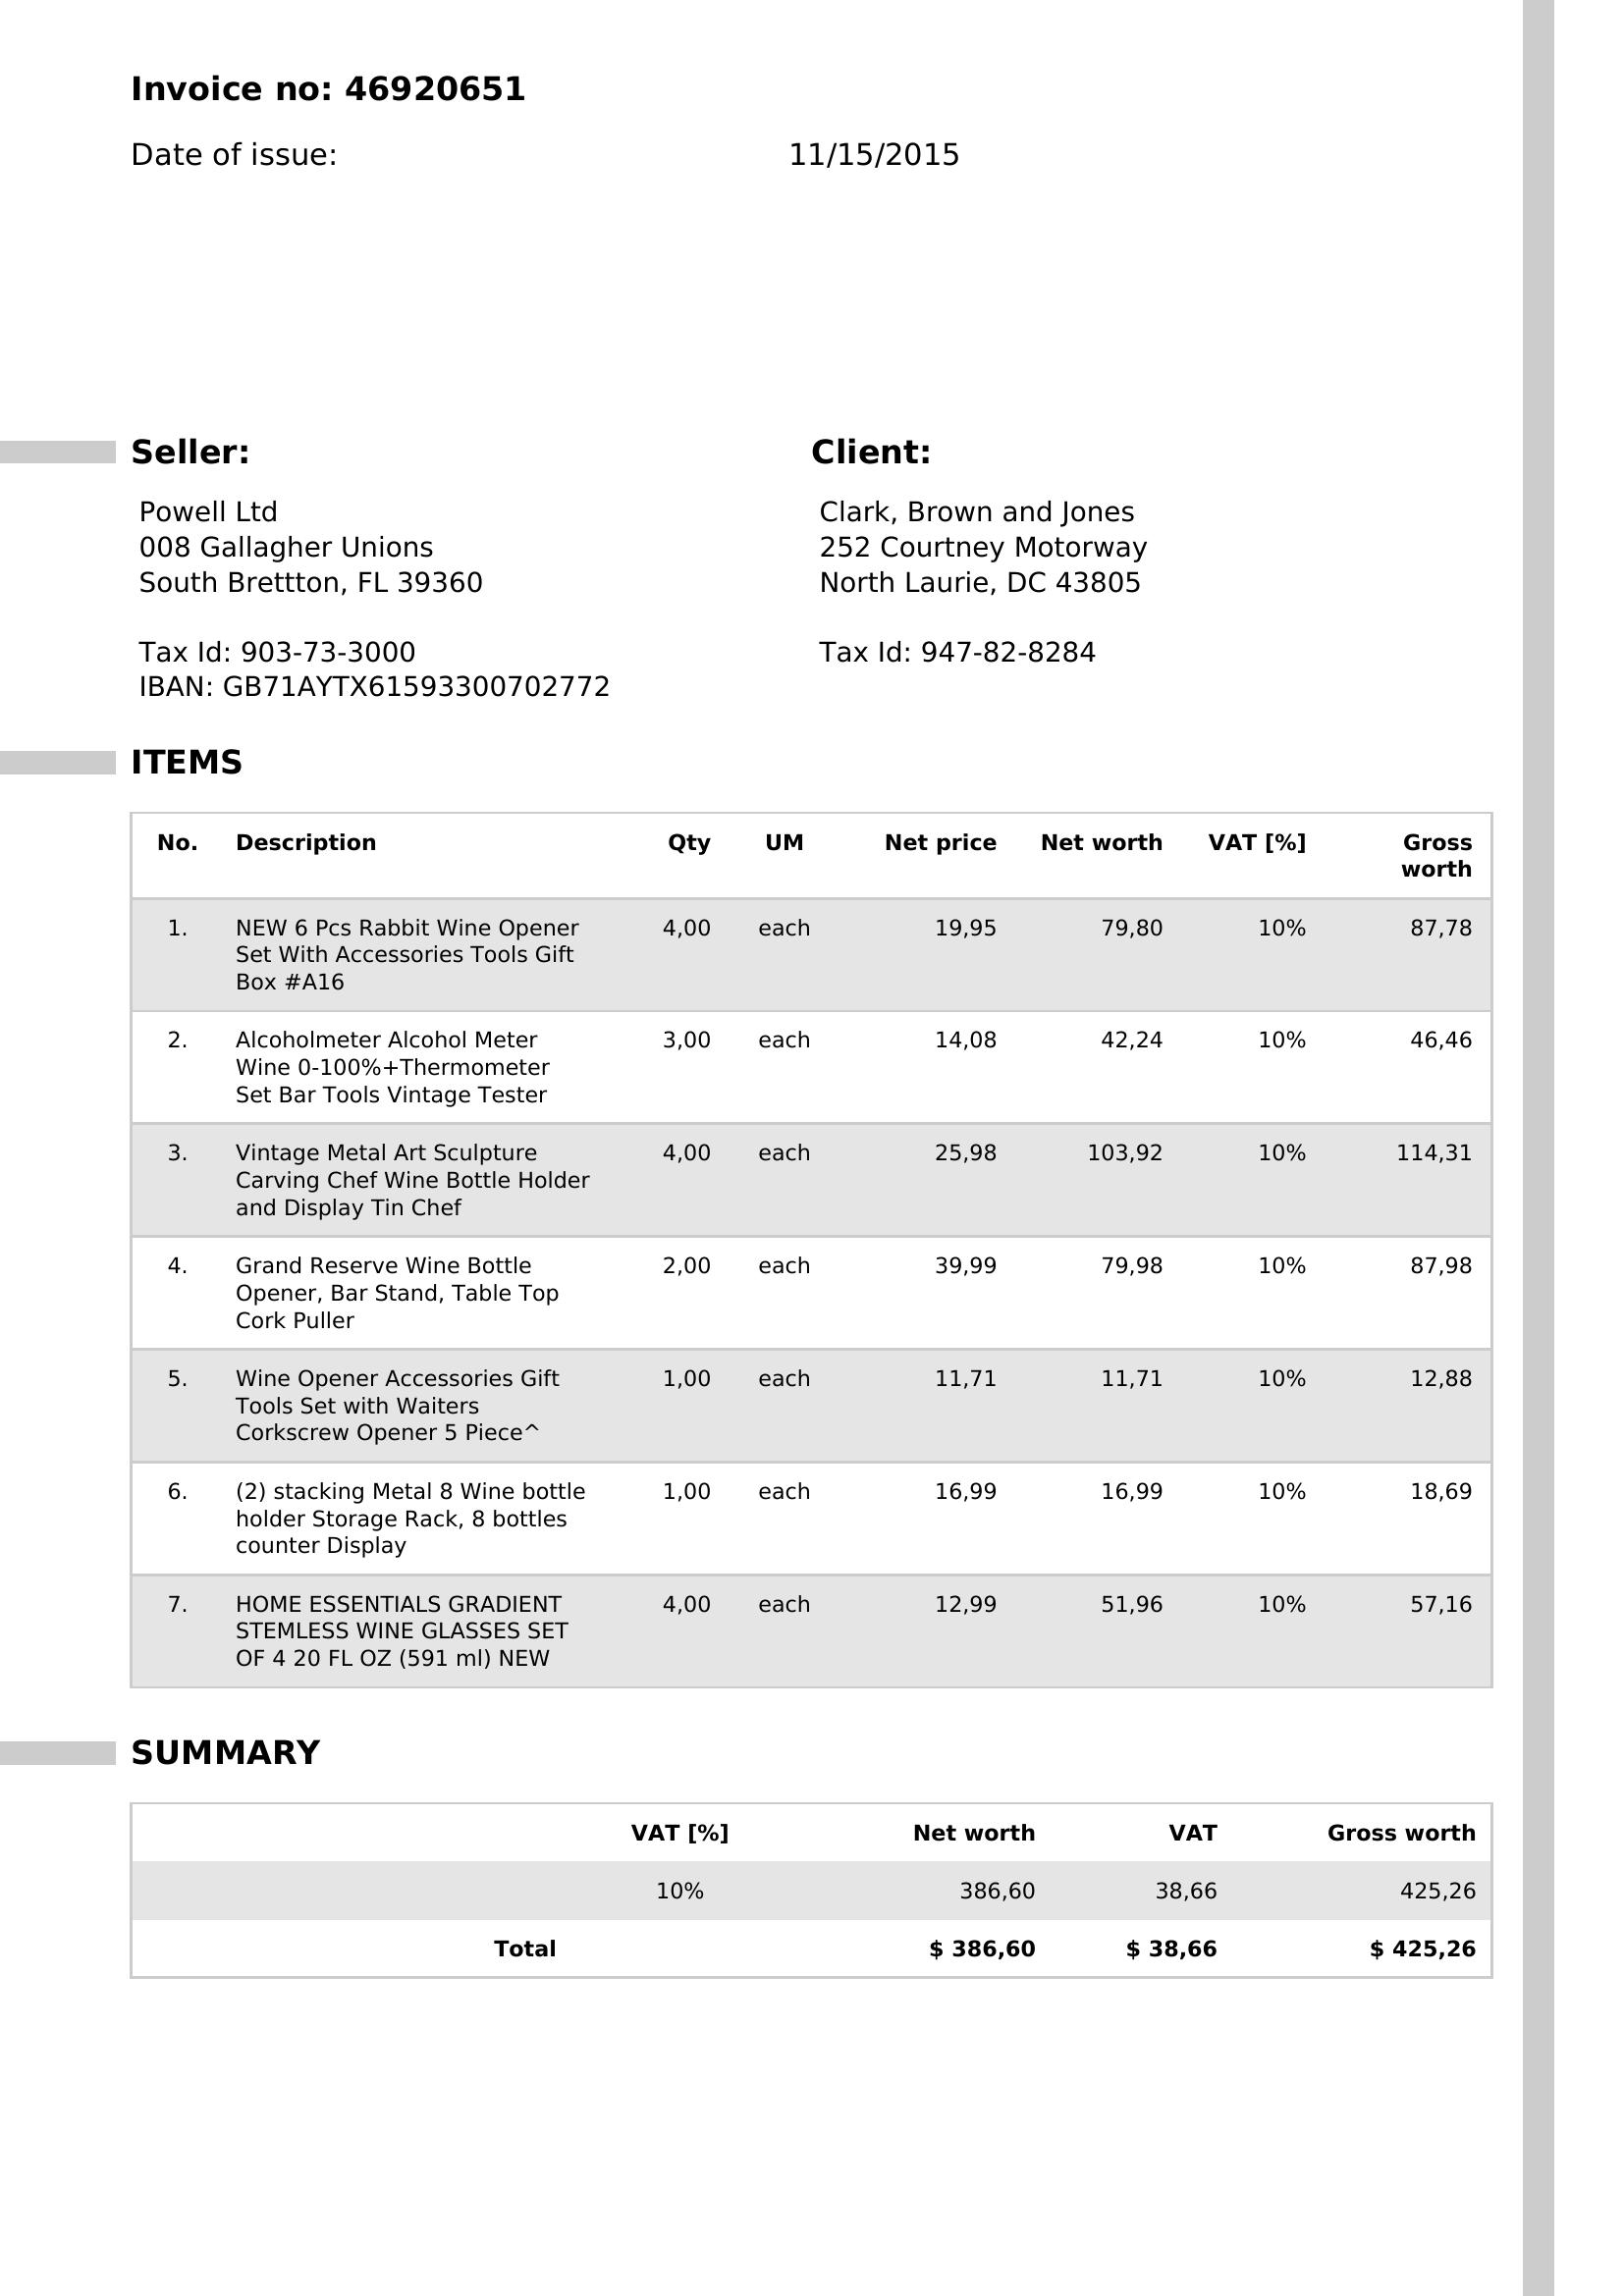

In [1187]:
display(
    Image(
        filename=str(row["path"])
    )
)

In [1188]:
extract_line_items(row['ocred_text'])

In [1189]:
row['ocred_text']

'Invoice no: 46920651 Date of issue: 11/15/2015 Seller: Client: Powell Ltd Clark, Brown and Jones 008 Gallagher Unions 252 Courtney Motorway South Brettton, FL 39360 North Laurie, DC 43805 Tax Id: 903-73-3000 Tax Id: 947-82-8284 IBAN: GBZIAYTX61593300702772 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth NEW 6 Pcs Rabbit Wine Opener 4,00 each 19,95 79,80 10% 87,78 Set With Accessories Tools Gift Box #A16 2 Alcoholmeter Alcohol Meter 3,00 each 14,08 42,24 10% 46,46 Wine 0-100%+Thermometer Set Bar Tools Vintage Tester 3 Vintage Metal Art Sculpture 4,00 each 25,98 103,92 10% 114,31 Carving Chef Wine Bottle Holder and Display Tin Chef Grand Reserve Wine Bottle 2,00 each 39,99 79,98 10% 87,98 Opener, Bar Stand, Table Top Cork Puller 5 Wine Opener Accessories Gift 1,00 each 11,71 11,71 10% 12,88 Tools Set with Waiters Corkscrew Opener 5 Piece 6 (2) stacking Metal 8 Wine bottle 1,00 each 16,99 16,99 10% 18,69 holder Storage Rack, 8 bottles counter Display HOME ESSENTIALS 

In [1168]:
diagnostic_report.loc[
    diagnostic_report["status"]
    == "numeric_count_mismatch",
    [
        "row_index",
        "file_name",
        "expected_count",
        "numeric_blocks",
    ],
].head(20)

,row_index,file_name,expected_count,numeric_blocks
405,405,batch1-0312.jpg,4,3
950,950,batch1-1069.jpg,3,2
992,992,batch1-1100.jpg,3,2
1285,1285,batch1-1470.jpg,2,1


In [1169]:
failed_indexes = diagnostic_report.loc[
    diagnostic_report["status"]
    == "numeric_count_mismatch",
    "row_index",
].head(10)

df.loc[
    failed_indexes,
    ["file_name", "ocred_text"],
]

,file_name,ocred_text
405,batch1-0312.jpg,Invoice no: 89959314 Date of issue: 09/01/2012...
950,batch1-1069.jpg,Invoice no: 92631946 Date of issue: 09/05/2020...
992,batch1-1100.jpg,Invoice no: 45181097 Date of issue: 02/24/2018...
1285,batch1-1470.jpg,Invoice no: 27278750 Date of issue: 08/04/2015...
